# ML4N – Project 8 · Section 1: data exploration and pre-processing

Notes and code for the first section of the project: what the DDoS dataset contains, which problems it has, how it is cleaned and how it becomes the feature matrix used by the models of the following sections. Every step has a short explanation, the code and its output, followed by a comment on what the output shows.

# Introduction to Section 1

Section 1 of the assignment has three points:

- **1.1 – Investigation of the dataset.** Describe the data with statistics and plots, first for the traffic as a whole (*generic traffic level*), then class by class (*ground-truth level*), and check its quality: types, missing and infinite values, constant and duplicated columns, impossible values.
- **1.2 – Pre-processing.** Decide which columns to keep and why, clean the data, study the correlations with Pearson and Spearman, choose how to encode the categorical features and how to scale the numeric ones, apply PCA and decide where it is useful.
- **1.3 – Final feature matrix.** Describe the matrix that the models will receive: its size, the features it keeps and why, which of them carry the most information, their distributions after the transformations and the correlation that remains among them.

The notebook follows the same order. It reads one file, `data/ddos_dataset.csv`, and writes one file, `data/ddos_pulito.csv` (the cleaned dataset); everything else is shown here.

| Part | Sections | Content |
|---|---|---|
| Introduction | 1–2 | the dataset, setup, loading the data |
| **1.1** | 3–6 | structure and quality, generic traffic level, ground-truth level, anomalous values |
| **1.2** | 7–13 | which columns to keep (a five-step funnel), cleaning, Pearson and Spearman, encoding, log and scaling, pipeline, PCA |
| **1.3** | 14–17 | size and composition, the most informative features, distributions after the transformations, residual correlation |
| End | – | summary of Section 1 and notes for Section 2 |

References such as §6.3 point to the numbered sections of this notebook.

## 1. The dataset

**Flows.** Each row is a network *flow*: the packets exchanged between a source and a destination (IP address and port) with a given transport protocol. The flows come from the CIC-DDoS2019 dataset and were extracted with CICFlowMeter, which summarises each flow with about 80 statistics: duration, number and size of the packets in each direction, inter-arrival times (IAT, the time between two consecutive packets), TCP flags, byte and packet rates, and so on. Each row also carries the identifiers of the flow (Flow ID, IP addresses, ports, protocol, timestamp) and its ground-truth label.

**Directions.** CICFlowMeter describes each direction separately. *Forward* (`Fwd`) is the direction from the host that opened the flow (the source) to the destination; *backward* (`Bwd`) is the opposite one, the replies. In an attack the forward packets are the attack traffic, while the backward ones are the answers of the victim, if any.

**Classes.** The column `label` takes 12 values: `benign`, the normal traffic, and 11 DDoS attacks. Eight are reflection/amplification attacks named after the service they abuse (`ddos_dns`, `ddos_ldap`, `ddos_mssql`, `ddos_netbios`, `ddos_ntp`, `ddos_snmp`, `ddos_ssdp`, `ddos_tftp`): the attacker sends small requests with the victim's address as sender, and the servers send large answers to the victim. The other three are floods, where the attacker sends the traffic directly: `ddos_syn` (TCP connection requests) and `ddos_udp`, `ddos_udp_lag` (UDP packets).

**What Section 1 must establish.** Before training a classifier we need to know what the data look like, which columns can be trusted and how to present them to a model. In particular: how different benign traffic is from the attacks, which attacks resemble each other (and will therefore be confused by the models of Section 2), which columns would let a model "cheat" by recognising the experiment instead of the attack, and which columns are corrupted.

## 2. Setup

### 2.1 Configuration

The notebook looks for the dataset in a `data` folder next to it; the cleaned dataset is written to the same folder in §8.4.

In [1]:
from pathlib import Path

PROJECT_ROOT = Path.cwd()                                # folder of the notebook
DATA_CSV = PROJECT_ROOT / "data" / "ddos_dataset.csv"     # input: the raw dataset
CLEAN_CSV = PROJECT_ROOT / "data" / "ddos_pulito.csv"     # output: the cleaned dataset (§8.4)

if not DATA_CSV.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_CSV}")
print(f"Dataset: {DATA_CSV.name} ({DATA_CSV.stat().st_size / 1e6:.1f} MB)")

Dataset: ddos_dataset.csv (29.3 MB)


### 2.2 Libraries and display options

pandas and NumPy for the data, Matplotlib for the plots, scikit-learn for the encoding, the scaling, the PCA and the mutual information of points 1.2–1.3 (install it with `pip install scikit-learn` if needed). The display options show all the columns of a table and do not truncate long tables.

In [2]:
%matplotlib inline

import csv
import sys
import warnings

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.feature_selection import mutual_info_classif
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, LabelEncoder, OneHotEncoder, StandardScaler

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 250)
pd.set_option("display.max_rows", 200)

print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {np.__version__} | "
      f"matplotlib {matplotlib.__version__} | scikit-learn {sklearn.__version__}")

Python 3.13.18 | pandas 3.0.6 | numpy 2.5.3 | matplotlib 3.11.2 | scikit-learn 1.9.1


### 2.3 Helper functions

A few definitions used throughout the notebook.

**Classes and colours.** `CLASS_COLORS` gives each class a fixed colour, so that a class looks the same in every figure; `LABELS` is the fixed order of the classes in tables and plots (`benign` first, then the attacks in alphabetical order). Twelve colours cannot all be told apart at a glance, so the colours are chosen to differ most within the groups of classes that resemble each other (`ddos_ldap`/`ddos_mssql`/`ddos_ssdp`, `ddos_syn`/`ddos_tftp`, `ddos_udp`/`ddos_udp_lag`), and plots with many classes add a second cue: solid and dashed lines (`LINESTYLE`) or the class names written on the plot. When benign traffic is compared with all the attacks together, benign is black and the attacks orange.

**Loading.**

- `read_raw_csv()` returns the file exactly as stored on disk. It reads each column as a whole (`low_memory=False`), so that every column gets a single data type (§6.7).
- `load_dataset()` starts from the raw file and prepares it for the analyses: it strips the leading spaces from the column names, drops the index column `Unnamed: 0` if the file has one (§2.4), replaces infinite values with `NaN` and converts `Timestamp` to date and time.

**Small tools.** `show_figure(fig)` arranges, shows and closes a figure; `ecdf(values)` returns the points of an empirical cumulative distribution (explained in §5.3); `show_left(table)` displays tables of sentences with left-aligned cells.

In [3]:
# --- classes and colours -------------------------------------------------------
CLASS_COLORS = {
    "benign": "black",
    "ddos_dns": "#e87ba4", "ddos_ldap": "#2a78d6", "ddos_mssql": "#eb6834",
    "ddos_netbios": "#008300", "ddos_ntp": "#8c564b", "ddos_snmp": "#eda100",
    "ddos_ssdp": "#1baf7a", "ddos_syn": "#e34948", "ddos_tftp": "#6250d6",
    "ddos_udp": "#00a3c4", "ddos_udp_lag": "#7f7f7f",
}
LABELS = list(CLASS_COLORS)                                   # benign first, then the attacks A-Z
LINESTYLE = {lab: "-" if i % 2 == 0 else "--" for i, lab in enumerate(LABELS)}
BENIGN_COLOR, ATTACK_COLOR = "black", "#eb6834"

# --- loading -------------------------------------------------------------------
INDEX_COL = "Unnamed: 0"     # name pandas gives to an index column without a name


def read_raw_csv():
    """The CSV as stored on disk, without any cleaning (names keep their leading spaces)."""
    return pd.read_csv(DATA_CSV, low_memory=False)


def load_dataset():
    """The CSV prepared for the analyses: names stripped, index column dropped if present,
    inf -> NaN, Timestamp as date/time."""
    df = read_raw_csv()
    df.columns = df.columns.str.strip()
    if INDEX_COL in df.columns:
        df = df.drop(columns=INDEX_COL)
    df = df.replace([np.inf, -np.inf], np.nan)
    df["Timestamp"] = pd.to_datetime(df["Timestamp"])
    return df


# --- small tools ---------------------------------------------------------------
def show_figure(fig, tight=True):
    """Show a figure and close it. tight=False keeps a layout already arranged by the cell."""
    if tight:
        fig.tight_layout()
    display(fig)
    plt.close(fig)


def ecdf(values):
    """Sorted values and, for each, the share of values <= it."""
    x = np.sort(np.asarray(values, dtype=float))
    return x, np.arange(1, len(x) + 1) / len(x)


def show_left(table, precision=2):
    """Display a table with left-aligned cells: easier to read when they hold sentences."""
    display(table.style.format(precision=precision)
            .set_properties(**{"text-align": "left"})
            .set_table_styles([{"selector": "th", "props": [("text-align", "left")]}]))

### 2.4 Format of the file

Before loading the data, a look at the raw text of the file: how many fields the header has and how many each data row has.

In [4]:
with open(DATA_CSV, newline="", encoding="utf-8") as f:
    reader = csv.reader(f)
    header = next(reader)
    first_row = next(reader)
    fields_per_row = pd.Series([len(first_row)] + [len(row) for row in reader]).value_counts()

print(f"Header: {len(header)} fields, the first one is {header[0]!r}")
print(f"Data rows: {fields_per_row.to_dict()}   ({{number of fields: number of rows}})")
print(f"First data row begins with: {first_row[:3]}")

Header: 87 fields, the first one is 'Flow ID'
Data rows: {88: 64239}   ({number of fields: number of rows})
First data row begins with: ['0', '172.16.0.5-192.168.50.1-634-60495-17', '172.16.0.5']


The header has 87 names, but each of the 64,239 data rows has 88 fields: every row starts with an integer that has no name in the header (`'0'` in the first row), followed by the Flow ID. So the file contains an unnamed index column. The next cell checks how pandas reads it.

In [5]:
plain = pd.read_csv(DATA_CSV, low_memory=False)
print(f"Columns: {plain.shape[1]}, the first one is {plain.columns[0]!r}; "
      f"'{INDEX_COL}' among the columns: {INDEX_COL in plain.columns}")
print(f"Row index: from {plain.index.min()} to {plain.index.max()}, {len(plain):,} rows")
del plain

Columns: 87, the first one is 'Flow ID'; 'Unnamed: 0' among the columns: False
Row index: from 0 to 65999, 64,239 rows


When the data rows have one field more than the header, pandas uses the extra field as the row index on its own: the DataFrame has 87 columns, `Flow ID` comes first and there is no `Unnamed: 0` column. The index is therefore not a feature. Its values are not plain row numbers, though: they run from 0 to 65,999 with gaps, and §6.1 shows what they reveal about how the file was built.

If the file were saved with the index column named in the header, pandas would create an `Unnamed: 0` column instead; `load_dataset()` drops it when present, so the notebook works in both cases.

### 2.5 Loading the data

The dataset is loaded **once** here and never modified afterwards: every analysis of 1.1 and 1.2 reads `df`, and anything derived from it (the transport protocol as a name, attack or not) is kept in separate variables.

- `raw`: the file as stored, used where the untouched values matter (infinite values in §3.3, the cleaning in §8);
- `df`: the dataset prepared by `load_dataset()`;
- `TRANSPORT`: the protocol number as a name (6 = TCP, 17 = UDP, 0 = "other");
- `IS_ATTACK`: True for every flow that is not benign.

In [6]:
raw = read_raw_csv()
df = load_dataset()
TRANSPORT = df["Protocol"].map({6: "TCP", 17: "UDP", 0: "other"}).rename("transport")
IS_ATTACK = df["label"] != "benign"

assert set(df["label"]) == set(LABELS), "the classes differ from those of CLASS_COLORS"
print(f"df: {df.shape[0]:,} flows x {df.shape[1]} columns, {df['label'].nunique()} classes")

df: 64,239 flows x 87 columns, 12 classes


# Section 1.1 – Investigation of the dataset

Point 1.1 asks to present the dataset with statistics and plots, at two levels, and to check its quality:

- **structure and quality** (§3): size, the columns and their types, missing and infinite values, constant and duplicated columns, duplicate rows, descriptive statistics;
- **generic traffic level** (§4): flows per class and class imbalance, source and destination IPs, transport protocols, when each class occurs, the services in benign traffic;
- **ground-truth level** (§5): the classes compared with each other (ports, key features, median and IQR, TCP flags), ending with the answers to the two questions of the assignment: *can benign traffic be told apart from the attacks? which attacks are easy to separate and which overlap?* (§5.8);
- **anomalous values** (§6): the index column, impossible negative values, special values, a text column with mixed types.

Nothing is modified here: the decisions that follow from the analysis are taken in point 1.2.

## 3. Structure and quality

### 3.1 Size and a typical flow of each class

The size of the dataset, then one flow per class on a selection of columns, to compare the classes at a glance. As "typical" flow the cell takes, for each class, the flow whose duration is closest to the median duration of the class: the first row of a class is not necessarily representative.

In [7]:
print(f"Rows (flows): {df.shape[0]:,}   Columns: {df.shape[1]}")

EXAMPLE_COLUMNS = ["Protocol", "Source Port", "Destination Port", "Flow Duration", "Total Fwd Packets",
                   "Total Backward Packets", "Total Length of Fwd Packets", "Fwd Packet Length Max",
                   "Flow Bytes/s", "Flow Packets/s", "Flow IAT Mean", "ACK Flag Count",
                   "Fwd Header Length", "min_seg_size_forward", "Init_Win_bytes_forward",
                   "SimillarHTTP", "Inbound"]
typical = df.groupby("label")["Flow Duration"].apply(lambda s: (s - s.median()).abs().idxmin())
display(df.loc[typical.reindex(LABELS), ["label"] + EXAMPLE_COLUMNS].set_index("label").T)

Rows (flows): 64,239   Columns: 87


label,benign,ddos_dns,ddos_ldap,ddos_mssql,ddos_netbios,ddos_ntp,ddos_snmp,ddos_ssdp,ddos_syn,ddos_tftp,ddos_udp,ddos_udp_lag
Protocol,6,17,17,17,17,6,17,17,6,6,17,17
Source Port,50645,634,900,850,34012,25926,529,700,60506,12163,54872,42072
Destination Port,443,51301,1808,20345,2334,80,26888,36081,39070,12163,21124,26872
Flow Duration,20822,28301,1,1,1,211,1,2,51,1,104734,49
Total Fwd Packets,1,158,2,2,2,1,2,2,2,2,4,2
Total Backward Packets,3,0,0,0,0,1,0,0,2,0,0,0
Total Length of Fwd Packets,0.0,69232.0,2944.0,2944.0,884.0,0.0,458.0,2944.0,0.0,0.0,1398.0,766.0
Fwd Packet Length Max,0.0,440.0,1472.0,1472.0,442.0,0.0,229.0,1472.0,0.0,0.0,369.0,383.0
Flow Bytes/s,2977.619825,2446273.983251,2944000000.0,2944000000.0,884000000.0,0.0,458000000.0,1472000000.0,0.0,0.0,13348.100903,15632653.061224
Flow Packets/s,192.104505,5582.841596,2000000.0,2000000.0,2000000.0,9478.672986,2000000.0,1000000.0,78431.372549,2000000.0,38.191991,40816.326531


One typical flow per class already shows clear differences:

- **benign**: an HTTPS request (TCP, destination port 443) of about 21 ms, with 1 forward and 3 backward packets and `Inbound` = 0: a client that gets answers;
- **the UDP reflections** (`ddos_ldap`, `ddos_mssql`, `ddos_netbios`, `ddos_snmp`, `ddos_ssdp`): 1–2 µs, 2 forward packets, no answer, from a low source port to a random destination port. Only the packet size changes: 1,472 bytes for LDAP, MSSQL and SSDP, 442 for NetBIOS, 229 for SNMP;
- **`ddos_dns`**: 158 forward packets of 440 bytes in 28 ms;
- **`ddos_syn` and `ddos_tftp`**: TCP flows without payload, with the ACK flag and an initial window of 5,840 bytes; in the `ddos_tftp` flow source and destination port are the same (12163);
- **`ddos_ntp`**: a TCP flow towards port 80, one packet per direction and no payload: not an NTP flow (§4.4);
- **`ddos_udp` and `ddos_udp_lag`**: UDP packets of 369 and 383 bytes, the first flow lasting 105 ms.

Three oddities are already visible, all studied in §6: `Fwd Header Length` is negative in most UDP flows and equal to minus the number of forward packets (−2 with 2 packets, −4 with 4); `min_seg_size_forward` is −1 in the same flows; `Init_Win_bytes_forward` is −1 in every UDP flow.

### 3.2 The columns

CICFlowMeter's 87 columns fall into a few families. The dictionary below assigns every column to its family, with a short description of what the family measures; the `assert` checks that no column is forgotten or counted twice. The families are used again in §7, where the columns are reviewed one by one.

In [8]:
COLUMN_FAMILIES = {
    "identifiers": ("who talks to whom, how and when",
        ["Flow ID", "Source IP", "Source Port", "Destination IP", "Destination Port", "Protocol", "Timestamp"]),
    "duration": ("time from the first to the last packet (µs)", ["Flow Duration"]),
    "volume": ("packets and bytes sent in each direction",
        ["Total Fwd Packets", "Total Backward Packets", "Total Length of Fwd Packets",
         "Total Length of Bwd Packets", "Down/Up Ratio"]),
    "packet size": ("size of the packets (bytes): per direction and for the whole flow",
        ["Fwd Packet Length Max", "Fwd Packet Length Min", "Fwd Packet Length Mean", "Fwd Packet Length Std",
         "Bwd Packet Length Max", "Bwd Packet Length Min", "Bwd Packet Length Mean", "Bwd Packet Length Std",
         "Min Packet Length", "Max Packet Length", "Packet Length Mean", "Packet Length Std",
         "Packet Length Variance", "Average Packet Size", "Avg Fwd Segment Size", "Avg Bwd Segment Size"]),
    "rates": ("bytes and packets per second",
        ["Flow Bytes/s", "Flow Packets/s", "Fwd Packets/s", "Bwd Packets/s"]),
    "inter-arrival times": ("time between consecutive packets (µs): whole flow, forward, backward",
        ["Flow IAT Mean", "Flow IAT Std", "Flow IAT Max", "Flow IAT Min",
         "Fwd IAT Total", "Fwd IAT Mean", "Fwd IAT Std", "Fwd IAT Max", "Fwd IAT Min",
         "Bwd IAT Total", "Bwd IAT Mean", "Bwd IAT Std", "Bwd IAT Max", "Bwd IAT Min"]),
    "TCP flags": ("how many packets carry each TCP flag (per direction for PSH and URG)",
        ["Fwd PSH Flags", "Bwd PSH Flags", "Fwd URG Flags", "Bwd URG Flags", "FIN Flag Count",
         "SYN Flag Count", "RST Flag Count", "PSH Flag Count", "ACK Flag Count", "URG Flag Count",
         "CWE Flag Count", "ECE Flag Count"]),
    "headers and TCP windows": ("header bytes, segment sizes, packets with payload, initial TCP window",
        ["Fwd Header Length", "Bwd Header Length", "Fwd Header Length.1", "min_seg_size_forward",
         "act_data_pkt_fwd", "Init_Win_bytes_forward", "Init_Win_bytes_backward"]),
    "bulk": ("transfers of many packets in a row without pauses",
        ["Fwd Avg Bytes/Bulk", "Fwd Avg Packets/Bulk", "Fwd Avg Bulk Rate",
         "Bwd Avg Bytes/Bulk", "Bwd Avg Packets/Bulk", "Bwd Avg Bulk Rate"]),
    "subflows": ("the same counts computed on sub-flows",
        ["Subflow Fwd Packets", "Subflow Fwd Bytes", "Subflow Bwd Packets", "Subflow Bwd Bytes"]),
    "activity and idle": ("how long the flow is active before a pause, and how long the pauses last (µs)",
        ["Active Mean", "Active Std", "Active Max", "Active Min", "Idle Mean", "Idle Std", "Idle Max", "Idle Min"]),
    "content and direction": ("an HTTP request in the flow; flow towards the monitored network",
        ["SimillarHTTP", "Inbound"]),
    "target": ("the class of the flow", ["label"]),
}
FAMILY_OF = {c: fam for fam, (_, cols) in COLUMN_FAMILIES.items() for c in cols}
assert sorted(FAMILY_OF) == sorted(df.columns) and len(FAMILY_OF) == sum(len(c) for _, c in COLUMN_FAMILIES.values())

show_left(pd.DataFrame([{"family": fam, "columns": len(cols), "what they measure": what}
                        for fam, (what, cols) in COLUMN_FAMILIES.items()]).set_index("family"))

,columns,what they measure
family,,
identifiers,7,"who talks to whom, how and when"
duration,1,time from the first to the last packet (µs)
volume,5,packets and bytes sent in each direction
packet size,16,size of the packets (bytes): per direction and for the whole flow
rates,4,bytes and packets per second
inter-arrival times,14,"time between consecutive packets (µs): whole flow, forward, backward"
TCP flags,12,how many packets carry each TCP flag (per direction for PSH and URG)
headers and TCP windows,7,"header bytes, segment sizes, packets with payload, initial TCP window"
bulk,6,transfers of many packets in a row without pauses


Thirteen families: 7 identifiers, the label and 79 measurements. Some families are large because CICFlowMeter computes the same quantity in several versions (for the whole flow and for each direction; mean, standard deviation, maximum and minimum), so the measurements are likely to repeat each other: §3.5 and §7 check this.

The next table describes every column: its family, data type, number of distinct values, minimum and maximum (for the numeric columns) and its value in the first row.

In [9]:
numeric = df.select_dtypes("number")
columns = pd.DataFrame({
    "family": pd.Series(FAMILY_OF),
    "dtype": df.dtypes.astype(str),
    "distinct values": df.nunique(),
    "min": pd.Series({c: numeric[c].min() for c in numeric}, dtype=object),
    "max": pd.Series({c: numeric[c].max() for c in numeric}, dtype=object),
    "first row": df.iloc[0],
}).reindex(df.columns)
display(columns.fillna("-"))

,family,dtype,distinct values,min,max,first row
Flow ID,identifiers,str,60958,-,-,172.16.0.5-192.168.50.1-634-60495-17
Source IP,identifiers,str,216,-,-,172.16.0.5
Source Port,identifiers,int64,22994,0,65518,634
Destination IP,identifiers,str,245,-,-,192.168.50.1
Destination Port,identifiers,int64,34733,0,65535,60495
Protocol,identifiers,int64,3,0,17,17
Timestamp,identifiers,datetime64[us],64234,-,-,2018-12-01 10:51:39.813448
Flow Duration,duration,int64,15718,1,119999958,28415
Total Fwd Packets,volume,int64,155,1,85894,97
Total Backward Packets,volume,int64,161,0,1862,0


The table is the reference for the rest of the notebook. A few things stand out:

- **identifiers**: `Flow ID` has only 60,958 distinct values for 64,239 rows, so the same combination of addresses, ports and protocol can produce several flows; `Timestamp` has 64,234;
- **ranges**: durations up to 119,999,958 µs (120 s, the flow timeout of CICFlowMeter), up to 85,894 forward packets, rates up to 2.9·10⁹ B/s: the features span many orders of magnitude (§11);
- **flags**: the TCP flag columns have at most two distinct values, and several have a single one (§3.4);
- **impossible minima**: `Fwd Header Length` (and its copy), `Bwd Header Length` and `min_seg_size_forward` have negative minima, and the two `Init_Win_bytes` columns reach −1 (§6);
- **suspicious twins**: some columns have the same number of distinct values and the same range as another one, e.g. `Subflow Fwd Packets` and `Total Fwd Packets` (155 values, from 1 to 85,894): §3.5 checks whether they are copies;
- `SimillarHTTP` is a text column with 187 distinct values (§6.7).

### 3.3 Data types, missing and infinite values

`load_dataset()` turns `inf` into `NaN`, so both checks are made on `raw`, the file as read. Infinite values are typical of CICFlowMeter's rate columns (`Flow Bytes/s`, `Flow Packets/s`) when a flow lasts 0 µs.

In [10]:
display(df.dtypes.astype(str).value_counts().rename("columns").to_frame())

raw_named = raw.rename(columns=str.strip)               # same names as df, values untouched
n_nan = raw_named.isna().sum()
n_inf = np.isinf(raw_named.select_dtypes(include="number")).sum()
print("Columns with NaN:", n_nan[n_nan > 0].to_dict() or "none")
print("Columns with inf:", n_inf[n_inf > 0].to_dict() or "none")

,columns
float64,45
int64,36
str,5
datetime64[us],1


Columns with NaN: none
Columns with inf: none


- **Types:** 45 float columns, 36 integer columns, 5 text columns and the timestamp. With pandas ≥ 3 the text type is shown as `str`, with earlier versions as `object`; the content is the same. Besides the label, the text columns are `Flow ID`, the two IPs and `SimillarHTTP` (§6.7).
- **No missing and no infinite values**, even in the raw file. This is unusual for CICFlowMeter output, where the rates are infinite for flows lasting 0 µs; here the shortest flow lasts 1 µs (§3.7), so the file was most likely filtered before being distributed. The gaps in the index of §6.1 point the same way.

### 3.4 Constant columns

A column with the same value in every row carries no information.

In [11]:
CONSTANT = [c for c in df.columns if df[c].nunique(dropna=False) == 1]
display(pd.DataFrame({"only value": [df[c].iloc[0] for c in CONSTANT],
                      "family": [FAMILY_OF[c] for c in CONSTANT]},
                     index=pd.Index(CONSTANT, name=f"constant columns ({len(CONSTANT)})")))

,only value,family
constant columns (12),,
Bwd PSH Flags,0,TCP flags
Fwd URG Flags,0,TCP flags
Bwd URG Flags,0,TCP flags
FIN Flag Count,0,TCP flags
PSH Flag Count,0,TCP flags
ECE Flag Count,0,TCP flags
Fwd Avg Bytes/Bulk,0,bulk
Fwd Avg Packets/Bulk,0,bulk
Fwd Avg Bulk Rate,0,bulk


Twelve columns are 0 in every row: the six bulk statistics, three flag counts (FIN, PSH, ECE) and three directional flags (backward PSH, forward and backward URG). They are the first columns removed in §7.

### 3.5 Identical columns

Two columns are identical when they hold the same numbers in every row. The comparison is made on the values converted to float, so that a column stored as integers and its copy stored as floats are recognised too (`Series.equals` would miss them, because it also compares the data type). For each pair, the column that comes later in the file is called the copy.

In [12]:
compared = [c for c in numeric.columns if c not in CONSTANT]
as_float = {c: df[c].to_numpy(dtype=float) for c in compared}
COPIES = {}                                    # copy -> original
for i, a in enumerate(compared):
    for b in compared[i + 1:]:
        if b not in COPIES and np.array_equal(as_float[a], as_float[b]):
            COPIES[b] = a
display(pd.DataFrame({"identical to": COPIES.values(),
                      "dtype (copy / original)": [f"{df[c].dtype} / {df[o].dtype}" for c, o in COPIES.items()]},
                     index=pd.Index(COPIES.keys(), name="copy")))

,identical to,dtype (copy / original)
copy,,
Subflow Fwd Packets,Total Fwd Packets,int64 / int64
Subflow Bwd Packets,Total Backward Packets,int64 / int64
Subflow Fwd Bytes,Total Length of Fwd Packets,int64 / float64
Subflow Bwd Bytes,Total Length of Bwd Packets,int64 / float64
RST Flag Count,Fwd PSH Flags,int64 / int64
Fwd Header Length.1,Fwd Header Length,int64 / int64


Six columns are exact copies of another one:

- the four **subflow** statistics repeat the totals of the whole flow: in this file every flow is a single subflow. Two of them, `Subflow Fwd Bytes` and `Subflow Bwd Bytes`, are stored as integers while their originals are floats;
- `Fwd Header Length.1` is the well-known duplicate column of CICFlowMeter's output, corrupted values included (§6.3);
- `RST Flag Count` equals `Fwd PSH Flags` in every row. Two different TCP flags cannot always coincide, so this is an artefact of the extractor, not a property of the traffic.

The copies are removed in §7, the originals are judged on their own.

### 3.6 Duplicate rows

In [13]:
print("Duplicate rows (all 87 columns compared):", df.duplicated().sum())

Duplicate rows (all 87 columns compared): 0


No two rows are identical. The comparison includes `Flow ID` and `Timestamp`, which differ almost everywhere: once the identifiers and the other removed columns are dropped, 971 duplicates appear (§8.3).

### 3.7 Descriptive statistics of the key features

`describe()` on a selection of features: the volume and timing of the flow, the packet size, the rates, and the columns that §6 will show to be anomalous. These are raw values, corrupted ones included.

In [14]:
DESCRIBE = ["Flow Duration", "Total Fwd Packets", "Total Backward Packets", "Total Length of Fwd Packets",
            "Fwd Packet Length Max", "Flow Bytes/s", "Flow Packets/s", "Flow IAT Mean", "Idle Mean",
            "Fwd Header Length", "min_seg_size_forward", "Init_Win_bytes_forward", "Init_Win_bytes_backward"]
display(df[DESCRIBE].describe().T)

,count,mean,std,min,25%,50%,75%,max
Flow Duration,64239.0,5.150614e+06,2.249713e+07,1.000000e+00,1.000000,2.0,2.087700e+04,1.200000e+08
Total Fwd Packets,64239.0,1.881485e+01,4.623053e+02,1.000000e+00,2.000000,2.0,2.000000e+00,8.589400e+04
Total Backward Packets,64239.0,1.304036e+00,2.519972e+01,0.000000e+00,0.000000,0.0,0.000000e+00,1.862000e+03
Total Length of Fwd Packets,64239.0,6.699522e+03,2.051032e+04,0.000000e+00,123.000000,1050.0,2.944000e+03,1.760000e+05
Fwd Packet Length Max,64239.0,6.139929e+02,5.856917e+02,0.000000e+00,53.000000,393.0,1.464000e+03,3.564000e+03
Flow Bytes/s,64239.0,7.634940e+08,9.955216e+08,0.000000e+00,9610.494218,383000000.0,1.364500e+09,2.944000e+09
Flow Packets/s,64239.0,1.039858e+06,9.012285e+05,5.262150e-02,5257.900173,1000000.0,2.000000e+06,3.000000e+06
Flow IAT Mean,64239.0,3.657561e+05,1.556677e+06,5.000000e-01,1.000000,2.0,2.000477e+02,3.686411e+07
Idle Mean,64239.0,1.155553e+06,5.341380e+06,0.000000e+00,0.000000,0.0,0.000000e+00,1.147455e+08
Fwd Header Length,64239.0,-1.594533e+09,1.631552e+10,-2.125438e+11,-2.000000,28.0,4.000000e+01,1.559380e+05


The distributions are extremely skewed:

- the median flow lasts 2 µs and has 2 forward packets; at least three quarters of the flows have no backward packet and no idle time;
- the longest flows reach 1.2·10⁸ µs (120 s) and 85,894 forward packets;
- `Flow Packets/s` ranges from 0.05 to 3·10⁶, and the median `Flow Bytes/s` is 3.8·10⁸: half the flows belong to high-volume attacks;
- the mean is far above the median (for `Flow Duration` 5.2·10⁶ µs against 2): a few huge values dominate it.

The corrupted columns give meaningless statistics: `Fwd Header Length` has a mean of −1.6·10⁹ and a minimum of −2.1·10¹¹ bytes, `min_seg_size_forward` a mean of −4.2·10⁷. For `Init_Win_bytes_*`, −1 is the median and even the 75th percentile (§6.6). Statistics and scalings based on means and variances must therefore be computed after the cleaning, and on transformed values (§11).

## 4. Generic traffic level

The dataset as a whole, before looking at single features: a summary table, the number of flows per class (class imbalance), the IP addresses (how concentrated the traffic is), the transport protocols, when each class occurs and the services seen in benign traffic.

### 4.1 Summary table

In [15]:
attack_types = [l for l in LABELS if l != "benign"]
t_min, t_max = df["Timestamp"].min(), df["Timestamp"].max()
hours, rest = divmod(int((t_max - t_min).total_seconds()), 3600)
proto_pct = TRANSPORT.value_counts(normalize=True)

summary = pd.DataFrame({
    "Quantity": ["Total flows", "Classes", "Attack types", "Time span",
                 "Distinct source / destination IPs", "Transport protocols"],
    "Value": [
        f"{len(df):,}",
        f"{df['label'].nunique()} (1 benign + {len(attack_types)} attacks)",
        ", ".join(a.removeprefix("ddos_").replace("_", "-").upper() for a in attack_types),
        f"{t_min:%d/%m/%Y}, {t_min:%H:%M:%S}-{t_max:%H:%M:%S} ({hours} h {rest // 60} min)",
        f"{df['Source IP'].nunique()} / {df['Destination IP'].nunique()}",
        ", ".join(f"{p} {v:.1%}" for p, v in proto_pct.items()),
    ],
}).set_index("Quantity")
show_left(summary)

,Value
Quantity,
Total flows,"64,239"
Classes,12 (1 benign + 11 attacks)
Attack types,"DNS, LDAP, MSSQL, NETBIOS, NTP, SNMP, SSDP, SYN, TFTP, UDP, UDP-LAG"
Time span,"01/12/2018, 09:17:11-13:34:27 (4 h 17 min)"
Distinct source / destination IPs,216 / 245
Transport protocols,"UDP 76.1%, TCP 23.8%, other 0.1%"


64,239 flows in 12 classes, all recorded on 1 December 2018 in 4 h 17 min, between 216 source and 245 destination addresses; 76.1% of the flows are UDP and 23.8% TCP.

### 4.2 Flows per class

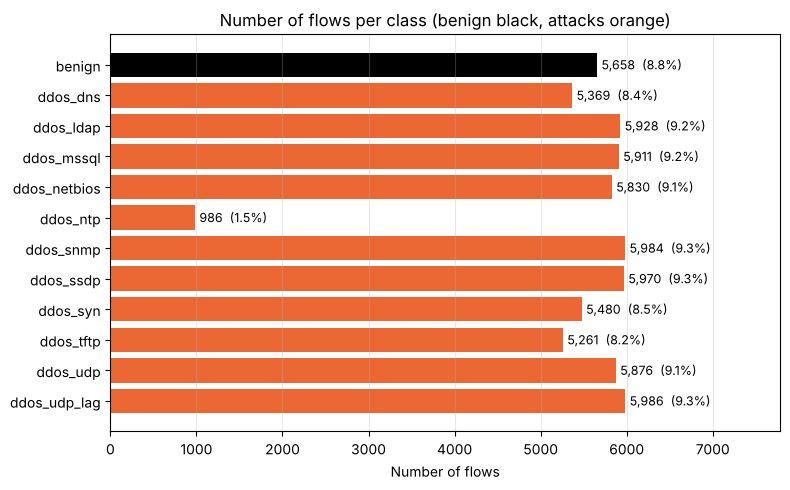

Largest / smallest class: ddos_udp_lag (5,986) / ddos_ntp (986), ratio 6.1


In [16]:
counts = df["label"].value_counts().reindex(LABELS)
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.barh(counts.index[::-1], counts.values[::-1],
               color=[BENIGN_COLOR if l == "benign" else ATTACK_COLOR for l in counts.index[::-1]])
ax.bar_label(bars, labels=[f"{v:,}  ({100 * v / len(df):.1f}%)" for v in counts.values[::-1]],
             padding=3, fontsize=9)
ax.set_xlim(0, counts.max() * 1.3)
ax.set_xlabel("Number of flows")
ax.set_title("Number of flows per class (benign black, attacks orange)")
ax.grid(axis="x", alpha=0.3)
show_figure(fig)
print(f"Largest / smallest class: {counts.idxmax()} ({counts.max():,}) / "
      f"{counts.idxmin()} ({counts.min():,}), ratio {counts.max() / counts.min():.1f}")

Eleven classes are roughly balanced, from 5,261 flows (`ddos_tftp`) to 5,986 (`ddos_udp_lag`). The exception is `ddos_ntp`, with 986 flows (1.5%), 6.1 times fewer than the largest class; §6.1 explains where this comes from.

Benign traffic is only 8.8% of the dataset, so a model that always answered "attack" would be right 91% of the time: accuracy alone says little here, and Section 2 needs per-class metrics.

### 4.3 Source and destination IPs: how concentrated is the traffic?

The ten busiest addresses as source and as destination, with the number of flows on a logarithmic axis (the busiest address has dozens of times more flows than the second). Each bar is coloured by the kind of traffic it carries: only attacks, only benign, or both; the text gives the flows and the number of classes seen with that address.

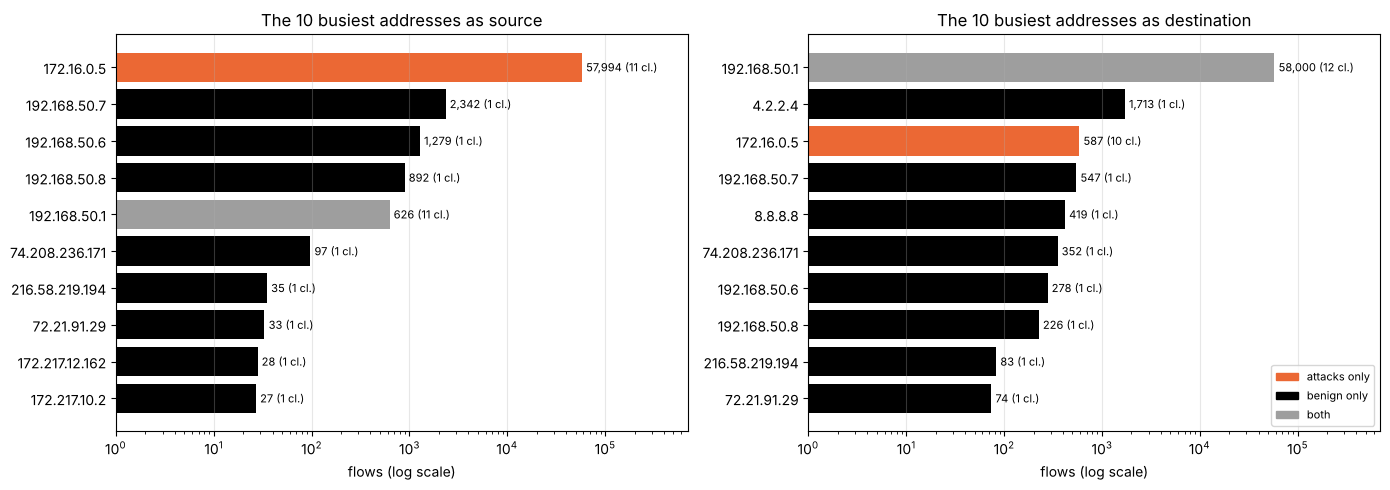

Source IP: 172.16.0.5 in 57,994 flows (90.3%); distinct per class: benign 215, attacks 1-2
Destination IP: 192.168.50.1 in 58,000 flows (90.3%); distinct per class: benign 244, attacks 1-2


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, col in zip(axes, ["Source IP", "Destination IP"]):
    top = df[col].value_counts().head(10)
    benign_share = df.loc[df[col].isin(top.index)].groupby(col)["label"].apply(lambda s: (s == "benign").mean())
    colors = ["black" if benign_share[ip] == 1 else ATTACK_COLOR if benign_share[ip] == 0 else "#9e9e9e"
              for ip in top.index]
    bars = ax.barh(top.index[::-1], top.values[::-1], color=colors[::-1])
    n_classes = df.loc[df[col].isin(top.index)].groupby(col)["label"].nunique()
    ax.bar_label(bars, labels=[f"{n:,} ({n_classes[ip]} cl.)" for ip, n in top.iloc[::-1].items()],
                 padding=3, fontsize=8)
    ax.set_xscale("log")
    ax.set_xlim(1, top.max() * 12)
    ax.set_xlabel("flows (log scale)")
    ax.set_title(f"The 10 busiest addresses as {col.split()[0].lower()}")
    ax.grid(axis="x", alpha=0.3)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in [ATTACK_COLOR, "black", "#9e9e9e"]]
axes[1].legend(handles, ["attacks only", "benign only", "both"], loc="lower right", fontsize=8)
show_figure(fig)

for col in ["Source IP", "Destination IP"]:
    per_class = df.groupby("label")[col].nunique()
    top_ip = df[col].value_counts()
    print(f"{col}: {top_ip.index[0]} in {top_ip.iloc[0]:,} flows ({top_ip.iloc[0] / len(df):.1%}); "
          f"distinct per class: benign {per_class['benign']}, "
          f"attacks {per_class.drop('benign').min()}-{per_class.drop('benign').max()}")

The traffic is extremely concentrated:

- **172.16.0.5** is the source of 57,994 flows and **192.168.50.1** the destination of 58,000, 90.3% each: the attacker of the testbed and its victim. The two addresses also appear in the opposite roles (626 and 587 flows): the attack flows recorded in the reverse direction;
- every other busy address carries only benign traffic: hosts of the internal network (192.168.50.6–8) and public servers, such as the DNS resolvers 4.2.2.4 and 8.8.8.8;
- every attack class uses at most 2 source and 2 destination IPs, the two ends of the same conversation, while benign traffic involves 215 sources and 244 destinations.

A model given the IP addresses would learn "172.16.0.5 → 192.168.50.1 means attack" instead of how the attacks behave: this is why the IPs are removed in step 1 of §7.

### 4.4 Transport protocols per class

`Protocol` is the IANA protocol number: 6 = TCP, 17 = UDP; the few flows with 0 are shown as "other".

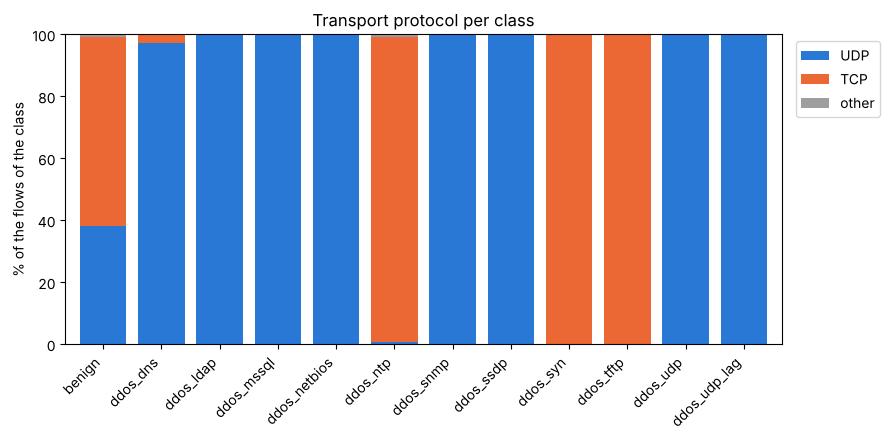

transport,TCP,UDP,other
label,,,
benign,61.0,38.2,0.7
ddos_dns,2.6,97.3,0.1
ddos_ldap,0.0,99.9,0.0
ddos_mssql,0.0,100.0,0.0
ddos_netbios,0.0,100.0,0.0
ddos_ntp,98.7,0.6,0.7
ddos_snmp,0.0,100.0,0.0
ddos_ssdp,0.1,99.9,0.0
ddos_syn,100.0,0.0,0.0


In [18]:
proto = pd.crosstab(df["label"], TRANSPORT, normalize="index").reindex(LABELS) * 100
fig, ax = plt.subplots(figsize=(9, 4.5))
proto[["UDP", "TCP", "other"]].plot(kind="bar", stacked=True, ax=ax, width=0.8,
                                    color={"UDP": "#2a78d6", "TCP": "#eb6834", "other": "#9e9e9e"})
ax.set_ylabel("% of the flows of the class")
ax.set_xlabel("")
ax.set_title("Transport protocol per class")
ax.legend(title="", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.xticks(rotation=45, ha="right")
show_figure(fig)
display(proto.round(1))

Most attack classes are almost pure UDP (from 97.3% for `ddos_dns` to 100%). `ddos_syn` is entirely TCP, as expected for a SYN flood, and benign traffic is mixed (61.0% TCP, 38.2% UDP).

Two classes do not match their name. NTP and TFTP amplification attacks run over UDP, yet `ddos_ntp` is 98.7% TCP and `ddos_tftp` 99.9% TCP, and §5.2 shows that neither class contains a single flow on the NTP (123) or TFTP (69) port. These labels seem to reflect the capture in which the flows were recorded (§6.1) rather than their content, a point worth discussing in the report.

### 4.5 When each class occurs

A timeline with one dot per flow and one row per class, then the exact time window of each class.

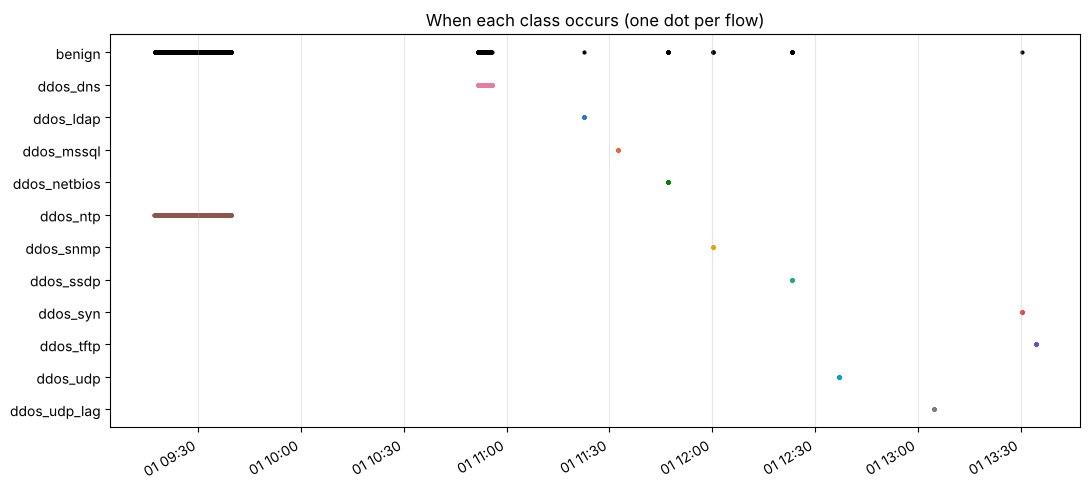

,min,max,flows,duration
label,,,,
ddos_ntp,09:17:11,09:39:32,986,00:22:21.714565
benign,09:17:12,13:30:30,5658,04:13:18.107533
ddos_dns,10:51:39,10:55:44,5369,00:04:04.863597
ddos_ldap,11:22:40,11:22:41,5928,00:00:01.689571
ddos_mssql,11:32:32,11:32:34,5911,00:00:01.770705
ddos_netbios,11:47:08,11:47:09,5830,00:00:00.843774
ddos_snmp,12:00:13,12:00:14,5984,00:00:00.803852
ddos_ssdp,12:23:13,12:23:14,5970,00:00:00.718002
ddos_udp,12:36:57,12:36:58,5876,00:00:00.792066


In [19]:
fig, ax = plt.subplots(figsize=(11, 5))
for i, lab in enumerate(LABELS):
    ts = df.loc[df["label"] == lab, "Timestamp"]
    ax.scatter(ts, np.full(len(ts), i), s=4, color=CLASS_COLORS[lab])
ax.set_yticks(range(len(LABELS)))
ax.set_yticklabels(LABELS)
ax.invert_yaxis()
ax.set_title("When each class occurs (one dot per flow)")
ax.grid(axis="x", alpha=0.3)
fig.autofmt_xdate()
show_figure(fig)

windows = df.groupby("label")["Timestamp"].agg(["min", "max", "size"]).sort_values("min")
windows["duration"] = (windows["max"] - windows["min"]).astype(str).str.replace("0 days ", "")
display(windows.assign(min=windows["min"].dt.strftime("%H:%M:%S"),
                       max=windows["max"].dt.strftime("%H:%M:%S")).rename(columns={"size": "flows"}))

Each class occupies its own moment of the day, and the attack windows never overlap: `ddos_ntp` from 09:17 to 09:39, then DNS (10:51–10:55), LDAP, MSSQL, NetBIOS, SNMP, SSDP, UDP, UDP-lag and SYN, with TFTP last at 13:34. Apart from NTP (22 min) and DNS (4 min), every attack lasts less than 2 seconds: in the timeline it is a single dot, a thin slice of a flood (§6.1). Benign flows are not spread over the day either: most of them fall in the NTP window, some in the DNS window, and a few isolated ones at the time of the other attacks.

This has two consequences:

- the timestamp alone identifies the class almost perfectly, so it cannot be a feature (§7.1);
- a split of the data by time would put entire classes only in the training set or only in the test set, which matters for the split of point 2.1b of the assignment.

### 4.6 Services in benign traffic

The service is inferred from the lower of the two ports of the flow, looked up in a small table of well-known ports.

In [20]:
SERVICES = {53: "DNS", 80: "HTTP", 443: "HTTPS", 465: "SMTPS", 21: "FTP", 22: "SSH",
            67: "DHCP", 123: "NTP", 137: "NetBIOS", 138: "NetBIOS"}
benign = df[~IS_ATTACK]
service = benign[["Source Port", "Destination Port"]].min(axis=1).map(SERVICES).fillna("other")
services = pd.crosstab(service.rename("service"), TRANSPORT[~IS_ATTACK])
display(services.loc[services.sum(axis=1).sort_values(ascending=False).index])

transport,TCP,UDP,other
service,,,
HTTPS,2312,0,0
DNS,0,2132,0
HTTP,1098,0,0
other,0,18,40
SMTPS,32,0,0
DHCP,0,8,0
FTP,7,0,0
SSH,5,0,0
NTP,0,3,0


Benign traffic is ordinary client activity: HTTPS (2,312 flows) and HTTP (1,098) over TCP, DNS over UDP (2,132), and a few flows of mail (SMTPS), DHCP, FTP, SSH, NTP and NetBIOS. The "other" row holds the 40 benign flows with protocol 0 and 18 UDP flows on ports outside the table.

## 5. Ground-truth level

Here the 12 classes are compared with each other:

1. a summary table per class (IPs, ports, protocol, medians);
2. the ports: in which range of port numbers each class falls, and which ports recur;
3. the distribution of the key features: boxplots and ECDFs;
4. median and IQR per class;
5. TCP flags per class;
6. the "fingerprint" of each class;
7. benign traffic against all the attacks together;
8. the answers to the two questions of point 1.1.

Most features span several orders of magnitude, so the plots use a logarithmic scale after adding 1 (to keep the zeros). None of the key features is among the corrupted columns of §6.

In [21]:
KEY_FEATURES = ["Flow Duration", "Total Fwd Packets", "Total Backward Packets",
                "Total Length of Fwd Packets", "Packet Length Mean", "Flow Bytes/s",
                "Flow Packets/s", "Flow IAT Mean", "Init_Win_bytes_forward"]


def plot_ecdf_per_class(ax, feature):
    """ECDF of a feature (+1, log scale), one curve per class."""
    for lab in LABELS:
        x, y = ecdf(df.loc[df["label"] == lab, feature] + 1)
        ax.plot(x, y, label=lab, color=CLASS_COLORS[lab], ls=LINESTYLE[lab],
                lw=2.5 if lab == "benign" else 1.5)
    ax.set_xscale("log")
    ax.set_xlabel(f"{feature} (+1, log scale)")
    ax.set_ylabel("share of the flows of the class")
    ax.grid(alpha=0.3)

### 5.1 Per-class summary

Number of flows, distinct IPs and ports, share of UDP flows and the medians of duration (µs), forward and backward packets and mean packet length (bytes).

In [22]:
per_class_summary = df.groupby("label").agg(
    flows=("label", "size"),
    src_ips=("Source IP", "nunique"),
    dst_ips=("Destination IP", "nunique"),
    src_ports=("Source Port", "nunique"),
    dst_ports=("Destination Port", "nunique"),
    pct_udp=("Protocol", lambda s: (s == 17).mean() * 100),
    median_duration=("Flow Duration", "median"),
    median_fwd_pkts=("Total Fwd Packets", "median"),
    median_bwd_pkts=("Total Backward Packets", "median"),
    median_pkt_len=("Packet Length Mean", "median"),
).reindex(LABELS).round(1)
display(per_class_summary)

,flows,src_ips,dst_ips,src_ports,dst_ports,pct_udp,median_duration,median_fwd_pkts,median_bwd_pkts,median_pkt_len
label,,,,,,,,,,
benign,5658,215,244,2725,893,38.2,20822.0,2.0,2.0,44.2
ddos_dns,5369,2,2,553,4879,97.3,28301.0,200.0,0.0,440.0
ddos_ldap,5928,2,2,368,5693,99.9,1.0,2.0,0.0,1472.0
ddos_mssql,5911,2,2,521,5619,100.0,1.0,2.0,0.0,1472.0
ddos_netbios,5830,2,2,4901,5528,100.0,1.0,2.0,0.0,483.0
ddos_ntp,986,2,2,349,341,0.6,210.5,1.0,2.0,0.0
ddos_snmp,5984,2,2,511,5704,100.0,1.0,2.0,0.0,229.0
ddos_ssdp,5970,2,2,515,5686,99.9,2.0,2.0,0.0,1472.0
ddos_syn,5480,1,1,5274,4927,0.0,51.0,2.0,0.0,0.0


The per-class table already separates several groups:

- **benign** is the only class with many hosts (215 sources, 244 destinations); together with `ddos_ntp`, it is also the only one with backward packets (median 2);
- **`ddos_ldap`, `ddos_mssql` and `ddos_ssdp`** look alike: 1–2 µs flows of 2 packets of 1,472 bytes. `ddos_snmp` and `ddos_netbios` are similar, with smaller packets (229 and 483 bytes);
- **`ddos_dns`** has longer flows (median 28 ms) of 200 forward packets of 440 bytes; **`ddos_udp`** long flows (105 ms) of 4 packets;
- **`ddos_syn` and `ddos_tftp`** are TCP flows without payload (median packet length 0), differing mainly in duration (51 µs against 1 µs);
- **every attack class uses at most 2 source and 2 destination IPs**: the two ends of the same conversation (§4.3).

### 5.2 Ports

A port number is a label, not a quantity, so instead of plotting the raw numbers the cell groups them into the three ranges defined by IANA:

- **well-known**, below 1,024: the standard services (53 DNS, 80 HTTP, 443 HTTPS, ...);
- **registered**, from 1,024 to 49,151: applications;
- **dynamic**, from 49,152: temporary ports chosen by the operating system for the client side of a connection.

For each class the bars give the share of its flows in each range, for the source and for the destination port. The last bar is a reference: the shares expected if the port were drawn at random over the 65,536 possible values (1.6% well-known, 73.4% registered, 25.0% dynamic).

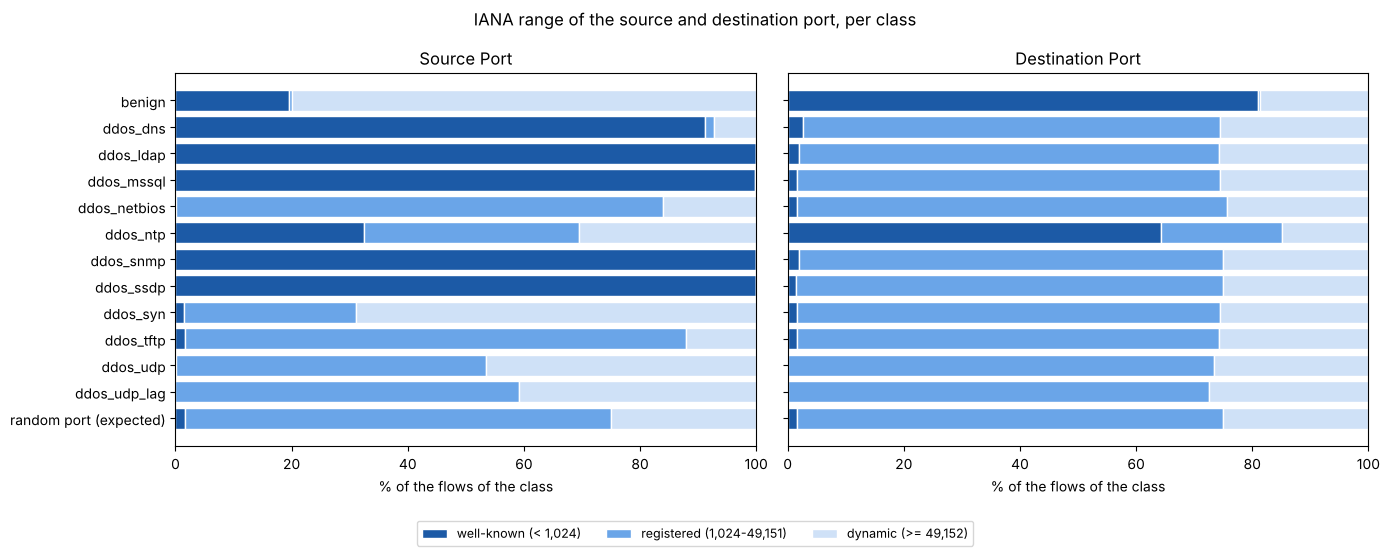

Source Port                    Destination Port                   
range                   well_known registered dynamic       well_known registered dynamic
label                                                                                    
benign                        19.6        0.4    80.0             81.0        0.3    18.7
ddos_dns                      91.1        1.6     7.3              2.6       71.9    25.5
ddos_ldap                    100.0        0.0     0.0              1.9       72.3    25.8
ddos_mssql                    99.8        0.1     0.1              1.6       72.8    25.5
ddos_netbios                   0.0       84.0    16.0              1.6       74.0    24.4
ddos_ntp                      32.5       37.0    30.5             64.3       20.9    14.8
ddos_snmp                    100.0        0.0     0.0              2.0       73.0    25.0
ddos_ssdp                     99.9        0.0     0.0              1.4       73.6    25.0
ddos_syn                       1.5       29.5    68.9              1.5       72.9    25.5
ddos_tftp                      1.6       86.3    12.1              1.6       72.8    25.6
ddos_udp                       0.1       53.4    46.5              0.1       73.4    26.6
ddos_udp_lag                   0.0       59.1    40.9              0.0       72.6    27.4
random port (expected)         1.6       73.4    25.0              1.6       73.4    25.0

In [23]:
RANGE_NAMES = {"well_known": "well-known (< 1,024)", "registered": "registered (1,024-49,151)",
               "dynamic": "dynamic (>= 49,152)"}


def port_range(port):
    """IANA range of a port number."""
    return np.select([port < 1024, port < 49152], ["well_known", "registered"], "dynamic")


uniform = pd.Series({"well_known": 1024, "registered": 48128, "dynamic": 16384}) / 65536 * 100
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
all_shares = {}
for ax, col in zip(axes, ["Source Port", "Destination Port"]):
    ranges = pd.Series(port_range(df[col].to_numpy()), index=df.index, name="range")
    shares = (pd.crosstab(df["label"], ranges, normalize="index") * 100).reindex(
        index=LABELS, columns=list(RANGE_NAMES), fill_value=0)
    shares.loc["random port (expected)"] = uniform
    all_shares[col] = shares
    left = np.zeros(len(shares))
    for rng, color in zip(RANGE_NAMES, ["#1c5aa6", "#6aa5e8", "#cfe1f7"]):
        ax.barh(shares.index, shares[rng], left=left, color=color, label=RANGE_NAMES[rng],
                edgecolor="white", linewidth=1)
        left += shares[rng].to_numpy()
    ax.set_title(col)
    ax.set_xlabel("% of the flows of the class")
    ax.set_xlim(0, 100)
axes[0].invert_yaxis()
handles, names = axes[0].get_legend_handles_labels()
fig.legend(handles, names, loc="lower center", ncol=3, fontsize=9)
fig.suptitle("IANA range of the source and destination port, per class")
fig.tight_layout(rect=[0, 0.07, 1, 1])
show_figure(fig, tight=False)
display(pd.concat(all_shares, axis=1).round(1))

Source and destination ports tell different stories.

**Destination port (right).** Every attack class except `ddos_ntp` has almost exactly the shares of a random port: 71.9–74.0% registered and 24.4–27.4% dynamic, against the expected 73.4% and 25.0%, and at most 2.6% well-known (practically 0 for `ddos_udp` and `ddos_udp_lag`, whose tools never pick a port below 1,024). The attacks hit random ports of the victim. Benign traffic is the opposite: 81.0% of its flows go to a well-known port, i.e. to a service (DNS, HTTP, HTTPS, §4.6). `ddos_ntp` is in between, with 64.3%.

**Source port (left).**

- `ddos_ldap`, `ddos_mssql`, `ddos_snmp` and `ddos_ssdp` send (almost) only from well-known ports (99.8–100%), `ddos_dns` from 91.1%: the reflected answers come from fixed low ports;
- the floods and `ddos_netbios` use registered and dynamic ports, in proportions that differ from class to class and from the random reference;
- benign traffic uses dynamic ports in 80.0% of the flows (the temporary ports of the clients) and well-known ports in 19.6% (replies from servers).

Which ports recur? For each class: the number of distinct ports and the most frequent one with its share of the flows, on both sides.

In [24]:
def top_port(s):
    """Most frequent port and its share (ties: the lowest port first)."""
    vc = s.value_counts().sort_index().sort_values(ascending=False, kind="stable")
    return f"{vc.index[0]} ({vc.iloc[0] / len(s):.0%})"


ports = df.groupby("label").agg(**{
    "source: distinct": ("Source Port", "nunique"),
    "source: most frequent": ("Source Port", top_port),
    "destination: distinct": ("Destination Port", "nunique"),
    "destination: most frequent": ("Destination Port", top_port),
}).reindex(LABELS)
display(ports)

,source: distinct,source: most frequent,destination: distinct,destination: most frequent
label,,,,
benign,2725,443 (13%),893,53 (38%)
ddos_dns,553,634 (77%),4879,80 (1%)
ddos_ldap,368,900 (94%),5693,659 (0%)
ddos_mssql,521,900 (18%),5619,9077 (0%)
ddos_netbios,4901,61850 (16%),5528,3641 (0%)
ddos_ntp,349,80 (25%),341,80 (50%)
ddos_snmp,511,648 (17%),5704,11565 (0%)
ddos_ssdp,515,672 (17%),5686,2489 (0%)
ddos_syn,5274,62555 (0%),4927,7512 (0%)


The most frequent ports confirm the ranges:

- **reflection classes**: a few hundred source ports (368–553), with a dominant low port: 900 for 94% of `ddos_ldap` and 18% of `ddos_mssql`, 634 for 77% of `ddos_dns`, 648 for 17% of `ddos_snmp`, 672 for 17% of `ddos_ssdp`. On the destination side thousands of ports, none with even 1% of the flows;
- **floods and `ddos_netbios`**: about 5,000 distinct source ports and no recurring one, except 61850 for 16% of `ddos_netbios`;
- **`ddos_ntp`**: port 80 on both sides (25% as source, 50% as destination), i.e. web traffic in both directions;
- **benign**: 53 (DNS) is the most frequent destination (38%), 443 the most frequent source (13%, replies from HTTPS servers).

Do the reflection attacks use the standard port of the service they are named after, on either side of the flow?

In [25]:
SERVICE_PORTS = {"ddos_dns": [53], "ddos_ldap": [389], "ddos_mssql": [1434],
                 "ddos_netbios": [137, 138, 139], "ddos_ntp": [123], "ddos_snmp": [161, 162],
                 "ddos_ssdp": [1900], "ddos_tftp": [69]}
service_use = pd.DataFrame([{
    "class": lab,
    "service port(s)": ", ".join(map(str, p)),
    "flows using it": int((df.loc[df["label"] == lab, "Source Port"].isin(p)
                           | df.loc[df["label"] == lab, "Destination Port"].isin(p)).sum()),
    "flows": int((df["label"] == lab).sum()),
    "transport": ", ".join(f"{t} {n}" for t, n in TRANSPORT[df["label"] == lab].value_counts().items()),
} for lab, p in SERVICE_PORTS.items()]).set_index("class")
display(service_use)

,service port(s),flows using it,flows,transport
class,,,,
ddos_dns,53,0,5369,"UDP 5223, TCP 142, other 4"
ddos_ldap,389,1,5928,"UDP 5925, TCP 2, other 1"
ddos_mssql,1434,0,5911,"UDP 5909, other 1, TCP 1"
ddos_netbios,"137, 138, 139",0,5830,"UDP 5829, other 1"
ddos_ntp,123,0,986,"TCP 973, other 7, UDP 6"
ddos_snmp,"161, 162",0,5984,UDP 5984
ddos_ssdp,1900,0,5970,"UDP 5966, TCP 3, other 1"
ddos_tftp,69,0,5261,"TCP 5257, UDP 3, other 1"


No flow of any reflection class uses the port of its service, on either side; a single `ddos_ldap` flow out of 5,928 is the only exception. The ports in the data are therefore choices of the attack tools in this testbed, not protocol semantics. For `ddos_ntp` and `ddos_tftp` the mismatch goes further: they are TCP flows (973 of 986 and 5,257 of 5,261) and never touch ports 123 or 69, so their content does not match their name (§4.4, §6.7).

### 5.3 Distribution of the key features

**Boxplots.** Each box spans the central half of the flows of a class, from the first quartile Q1 (25% of the flows are below it) to the third quartile Q3 (75% below); the line inside the box is the median. The whiskers extend to the most extreme flows within 1.5 box heights; the flows beyond them (outliers) are hidden to keep the plots readable. The y axis is logarithmic after adding 1.

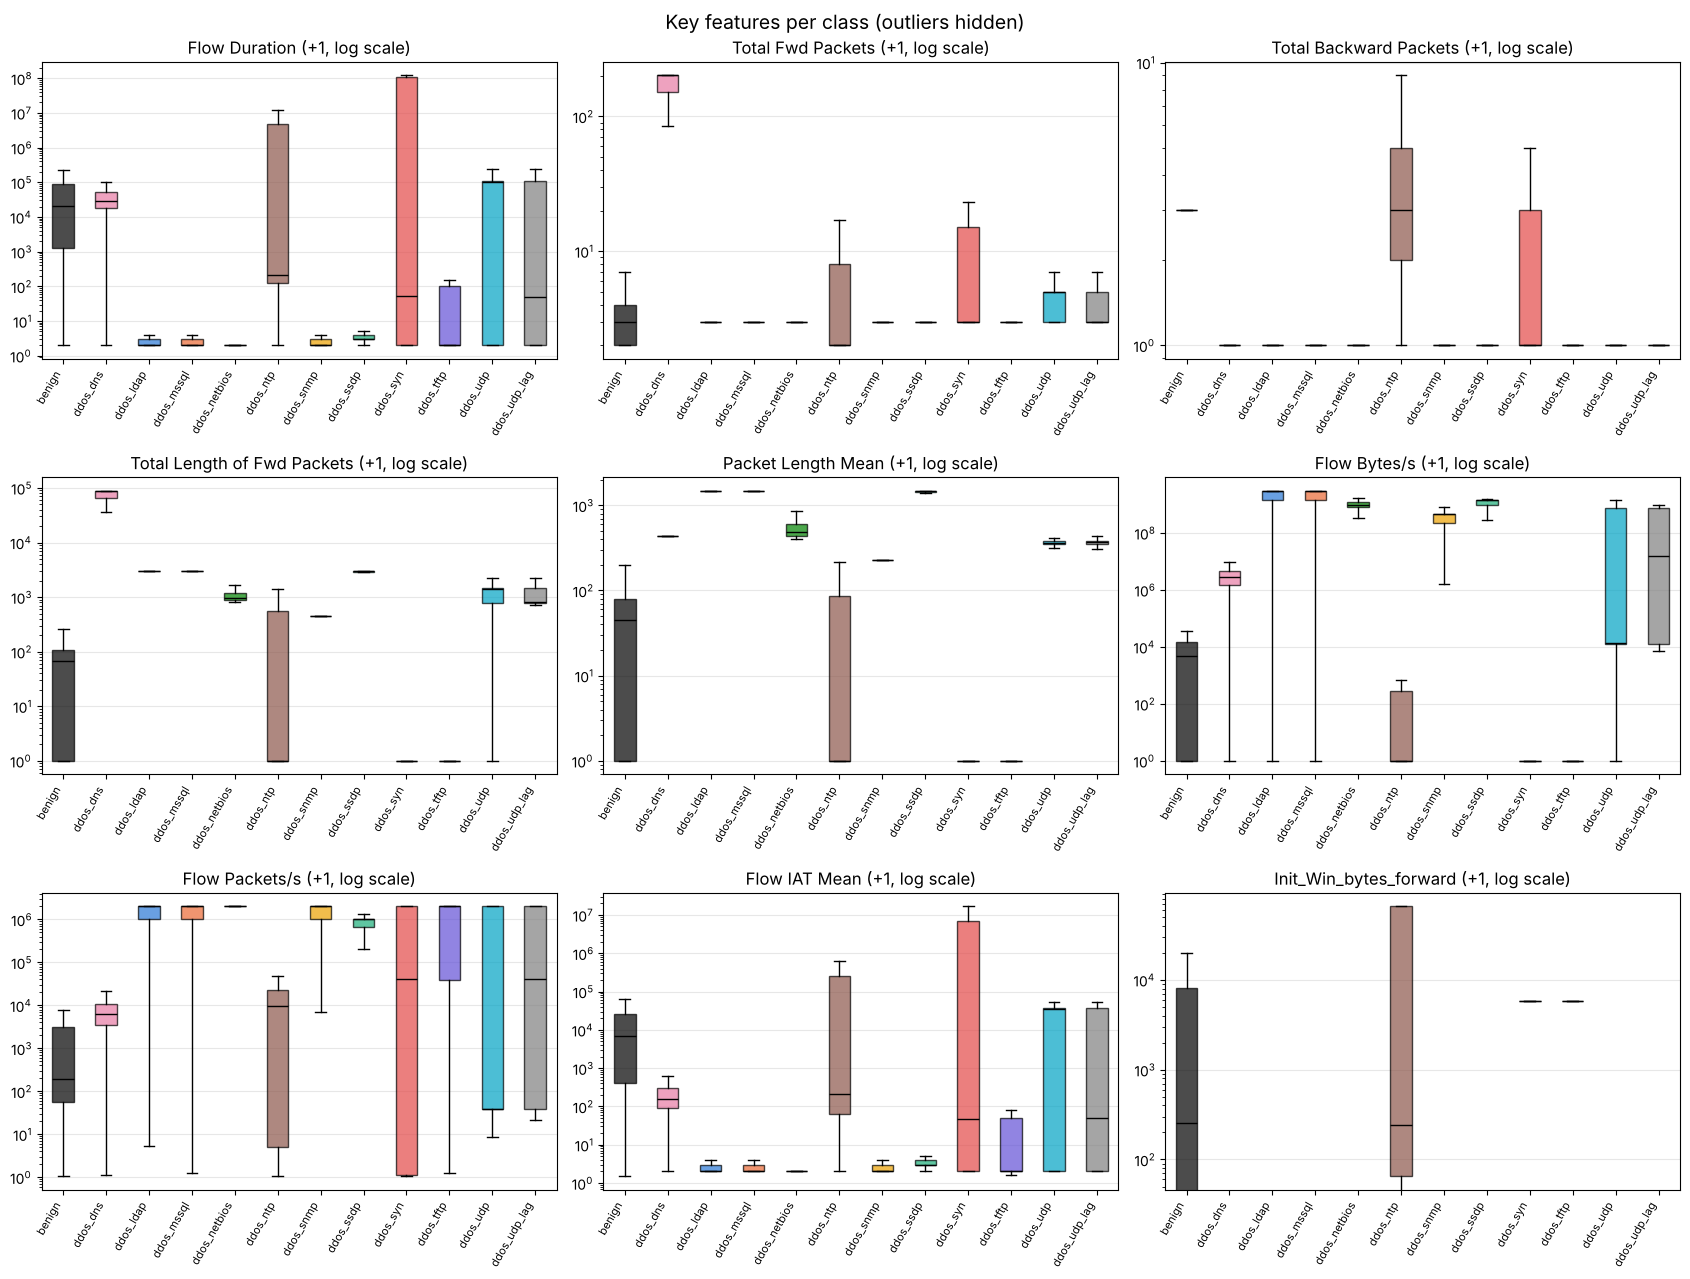

In [26]:
fig, axes = plt.subplots(3, 3, figsize=(17, 13))
for ax, feat in zip(axes.ravel(), KEY_FEATURES):
    data = [df.loc[df["label"] == l, feat] + 1 for l in LABELS]
    bp = ax.boxplot(data, showfliers=False, patch_artist=True, medianprops={"color": "black"})
    for patch, l in zip(bp["boxes"], LABELS):
        patch.set_facecolor(CLASS_COLORS[l])
        patch.set_alpha(0.7)
    ax.set_yscale("log")
    ax.set_xticks(range(1, len(LABELS) + 1))
    ax.set_xticklabels(LABELS, rotation=60, ha="right", fontsize=8)
    ax.set_title(feat + " (+1, log scale)")
    ax.grid(axis="y", alpha=0.3)
fig.suptitle("Key features per class (outliers hidden)", fontsize=14)
show_figure(fig)

Some features separate classes on their own:

- **`Flow Duration`**: the boxes of `ddos_ldap`, `ddos_mssql`, `ddos_netbios`, `ddos_snmp` and `ddos_ssdp` sit at 1–2 µs, those of benign traffic and `ddos_dns` at milliseconds or more;
- **`Total Fwd Packets`**: `ddos_dns` collapses on 200 packets, most reflections on 2;
- **`Total Backward Packets`**: only benign and `ddos_ntp` have a box above 0;
- **`Packet Length Mean`** and **`Total Length of Fwd Packets`** order the UDP classes by packet size (229 B SNMP, 440 B DNS, 483 B NetBIOS, 1,472 B LDAP, MSSQL and SSDP), while `ddos_syn` and `ddos_tftp` carry no payload;
- **`Flow Bytes/s`**: benign stays around 10⁴ B/s, the volumetric attacks reach 10⁸–10⁹ B/s;
- **`Init_Win_bytes_forward`**: only the TCP classes have a window; for UDP the value is −1, which becomes 0 after adding 1 (§6.6). `ddos_syn` and `ddos_tftp` have 5,840 in almost every flow.

Many boxes collapse to a single line: almost every flow of the class has the same value. These classes are easy to tell from the others but hard to tell from each other. Benign, `ddos_ntp`, `ddos_syn`, `ddos_udp` and `ddos_udp_lag` have wide boxes instead.

**ECDF.** A boxplot shows only five numbers per class. The **empirical cumulative distribution function** (ECDF) shows the whole distribution: for each value *x* on the horizontal axis, the curve gives the share of the flows of the class that are smaller than or equal to *x*. How to read it:

- the curve always goes from 0 (left) to 1 (right); where it rises steeply, many flows have values in that interval;
- a **vertical jump** means that many flows have exactly the same value (a jump of 0.8 at *x* = 2: 80% of the flows have value 2);
- the median is the *x* where the curve crosses 0.5, Q1 and Q3 where it crosses 0.25 and 0.75;
- a curve **to the left** of another means a class with smaller values; two curves that **coincide** are classes that the feature cannot separate.

Four features, one curve per class (benign thick black; solid and dashed lines alternate to help tell neighbouring curves apart).

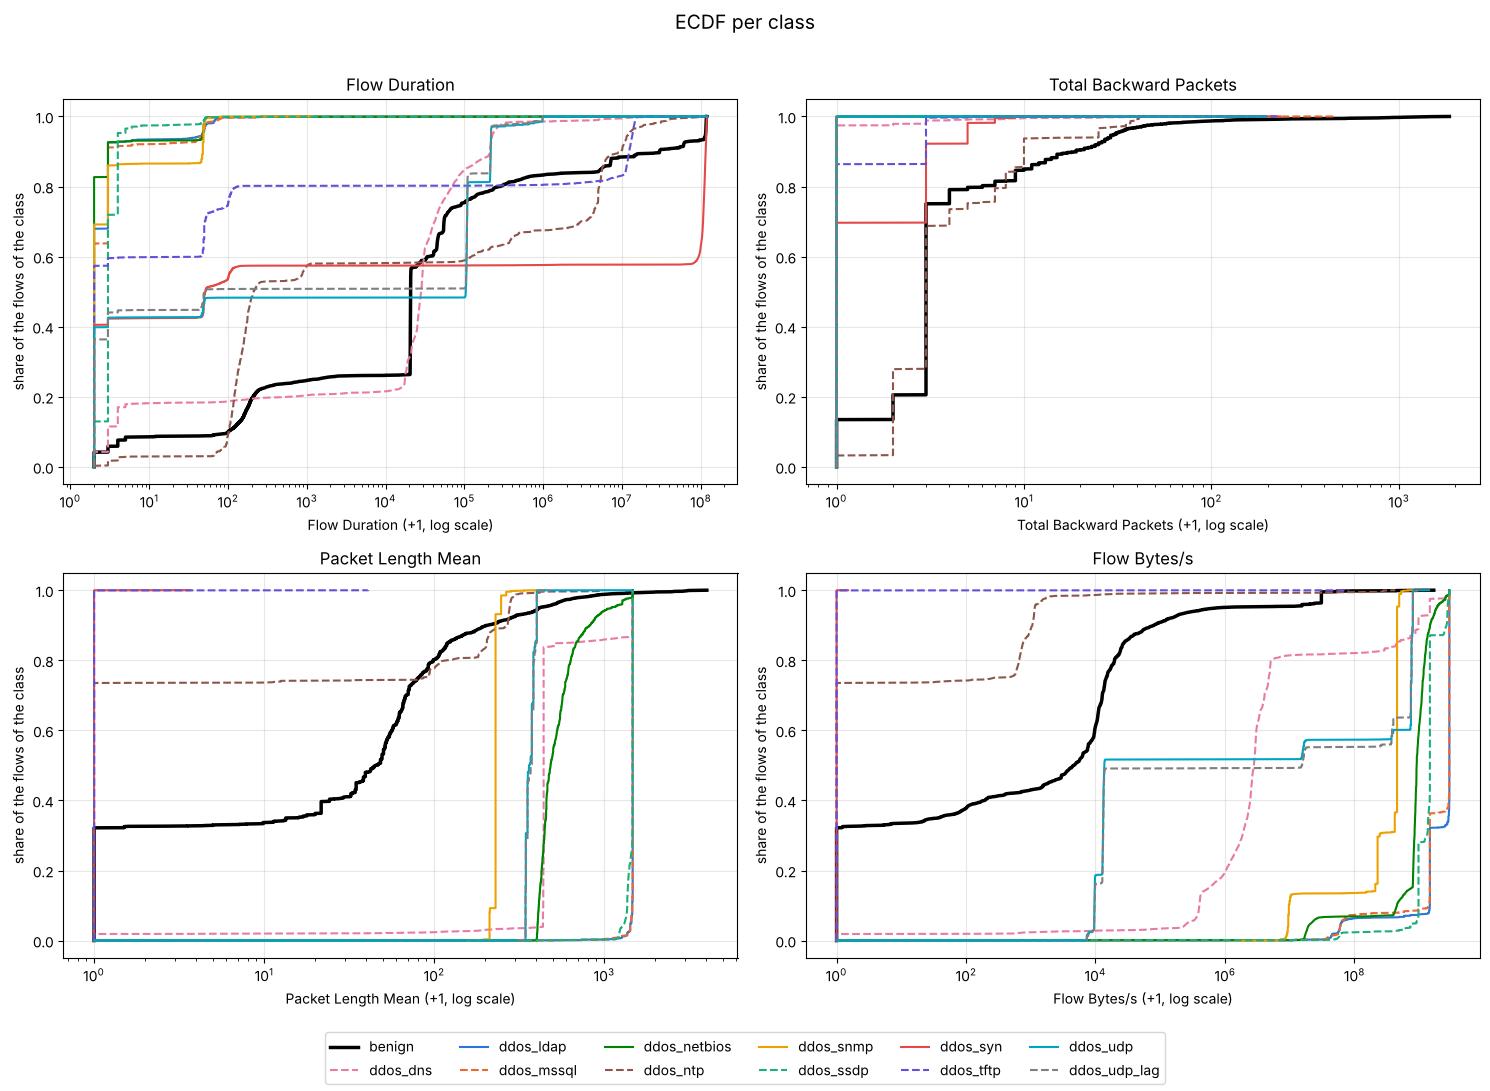

In [27]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
for ax, feat in zip(axes.ravel(), ["Flow Duration", "Total Backward Packets", "Packet Length Mean", "Flow Bytes/s"]):
    plot_ecdf_per_class(ax, feat)
    ax.set_title(feat)
handles, names = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, names, loc="lower center", ncol=6, fontsize=10)
fig.suptitle("ECDF per class", fontsize=14)
fig.tight_layout(rect=[0, 0.06, 1, 0.97])
show_figure(fig, tight=False)

- **`Flow Duration`**: five classes (`ddos_ldap`, `ddos_mssql`, `ddos_netbios`, `ddos_snmp`, `ddos_ssdp`) jump to between 0.7 and 0.95 within the first 2–3 µs and reach 1 by about 50 µs: almost all their flows are a few microseconds long. Benign and `ddos_dns` rise mostly between 10⁴ and 10⁵ µs (10–100 ms). `ddos_syn` is bimodal: its curve stops at about 0.58 for a long stretch and jumps again near 10⁸ µs, a group of flows lasting about 100 s.
- **`Total Backward Packets`**: the reflection curves start at (almost) 1 at the left edge: no backward packet at all. Benign is the opposite: only about 14% of its flows have no answer, and the big jump is at 2 backward packets. `ddos_ntp` behaves like benign, while about 30% of the `ddos_syn` flows and 13% of the `ddos_tftp` flows have some answers.
- **`Packet Length Mean`**: the vertical jumps are the packet sizes of the attacks: `ddos_snmp` at 229 bytes, `ddos_udp` and `ddos_udp_lag` around 360, `ddos_dns` at 440, while `ddos_ldap`, `ddos_mssql` and `ddos_ssdp` jump at the same place (1,472 bytes); `ddos_syn` and `ddos_tftp` are entirely at 0, `ddos_ntp` for about 73%.
- **`Flow Bytes/s`**: benign traffic rises between 10³ and 10⁵ B/s (after about 32% of flows at 0, without payload); the reflection attacks sit far to the right, near 10⁹ B/s, and `ddos_udp`/`ddos_udp_lag` are split in two groups, around 10⁴ and 10⁹ B/s.

### 5.4 Median and IQR per class

The plots of §5.3 can be summarised in numbers. For each class and each feature the table gives:

- the **median**: half of the flows of the class are below it, half above; it is the value of a "typical" flow;
- the **IQR** (interquartile range) = Q3 − Q1, the width of the central half of the class: a small IQR means flows that are all alike, a large one a varied class.

In the boxplots the median is the line inside the box and the IQR is the height of the box. With distributions this skewed, median and IQR describe a class much better than mean and standard deviation, which are dragged by a few extreme flows.

The five features are those named by the assignment: duration, number of forward packets, mean size of the forward packets, byte rate and mean inter-arrival time. Each cell reads *median [IQR]*; durations and IATs are in µs, sizes in bytes.

In [28]:
IQR_FEATURES = ["Flow Duration", "Total Fwd Packets", "Fwd Packet Length Mean",
                "Flow Bytes/s", "Flow IAT Mean"]
quartiles = df.groupby("label")[IQR_FEATURES].quantile([0.25, 0.5, 0.75]).unstack()
median = quartiles.xs(0.5, axis=1, level=1).reindex(LABELS)
iqr = (quartiles.xs(0.75, axis=1, level=1) - quartiles.xs(0.25, axis=1, level=1)).reindex(LABELS)


def readable(x):
    """Short numbers: no decimals above 100, scientific notation from 10^6."""
    if abs(x) >= 1e6:
        return f"{x:.1e}"
    if abs(x) >= 100:
        return f"{x:,.0f}"
    return f"{x:.1f}".rstrip("0").rstrip(".")


table = pd.DataFrame({f: [f"{readable(m)} [{readable(q)}]" for m, q in zip(median[f], iqr[f])]
                      for f in IQR_FEATURES}, index=pd.Index(LABELS, name="class"))
display(table)
print("Classes with IQR = 0 (the central half of the flows has exactly one value):")
for f in IQR_FEATURES:
    print(f"  {f:24s} {', '.join(iqr.index[iqr[f] == 0]) or '-'}")
mean_vs_median = df.loc[~IS_ATTACK, "Flow Duration"].mean() / df.loc[~IS_ATTACK, "Flow Duration"].median()
print(f"Benign Flow Duration: mean / median = {mean_vs_median:.0f}")

,Flow Duration,Total Fwd Packets,Fwd Packet Length Mean,Flow Bytes/s,Flow IAT Mean
class,,,,,
benign,"20,822 [90,102]",2 [2],31 [45],"4,633 [14,605]","6,927 [25,919]"
ddos_dns,"28,301 [33,648]",200 [50],440 [0],2.8e+06 [3.3e+06],157 [207]
ddos_ldap,1 [1],2 [0],"1,472 [0]",2.9e+09 [1.5e+09],1 [1]
ddos_mssql,1 [1],2 [0],"1,472 [0]",2.9e+09 [1.5e+09],1 [1]
ddos_netbios,1 [0],2 [0],483 [166],9.2e+08 [3.3e+08],1 [0]
ddos_ntp,210 [4.8e+06],1 [6],0 [58.3],0 [272],"208 [262,304]"
ddos_snmp,1 [1],2 [0],229 [0],4.6e+08 [2.3e+08],1 [1]
ddos_ssdp,2 [1],2 [0],"1,472 [24]",1.5e+09 [4.9e+08],2 [1]
ddos_syn,51 [1.1e+08],2 [12],0 [0],0 [0],47 [6.9e+06]


Classes with IQR = 0 (the central half of the flows has exactly one value):
  Flow Duration            ddos_netbios
  Total Fwd Packets        ddos_ldap, ddos_mssql, ddos_netbios, ddos_snmp, ddos_ssdp, ddos_tftp
  Fwd Packet Length Mean   ddos_dns, ddos_ldap, ddos_mssql, ddos_snmp, ddos_syn, ddos_tftp
  Flow Bytes/s             ddos_syn, ddos_tftp
  Flow IAT Mean            ddos_netbios
Benign Flow Duration: mean / median = 494


The table summarises in numbers what the plots showed:

- **benign** is the only class that is varied on every feature: a typical flow lasts 21 ms with an IQR of 90 ms, carries packets of 31 bytes on average and moves about 4,600 B/s. Its mean duration is about 500 times the median, which is why the median is the right summary here;
- **`ddos_ldap` and `ddos_mssql` have exactly the same row**: flows of 1 µs, 2 packets of 1,472 bytes, about 2.9·10⁹ B/s, with an IQR of 0 or 1 everywhere. On these five features the two classes cannot be told apart; `ddos_ssdp` differs only by one microsecond and a little more spread in the packet size;
- **`ddos_netbios` and `ddos_snmp`** have the same short, two-packet flows, but different packet sizes (483 and 229 bytes), which separate them from each other and from the 1,472-byte group;
- **`ddos_dns`** is unmistakable: 200 forward packets of 440 bytes in 28 ms;
- **`ddos_syn` and `ddos_tftp`** carry no payload at all (size 0, rate 0, IQR 0) and differ only in duration;
- **`ddos_udp` and `ddos_udp_lag`** share the same packet size (367 and 371 bytes, both with IQR 33.5); `ddos_udp` lasts longer in its typical flow, but the IQRs of about 109 ms show that the two classes cover the same range of durations;
- **`ddos_ntp`** has a median packet size of 0 and an enormous IQR in duration (4.8·10⁶ µs): it is a mixture of very different flows.

Six classes have IQR 0 for the number of forward packets, and six for the packet size: the central half of their flows has *exactly* the same value. This is the signature of traffic generated by a tool, and it is what makes those classes easy to recognise as attacks, and hard to tell apart from each other.

### 5.5 TCP flags per class

Mean of each flag column per class; since the flags are 0/1 here, the mean is the fraction of flows with the flag set. Only the flags that are not constant are shown (§3.4).

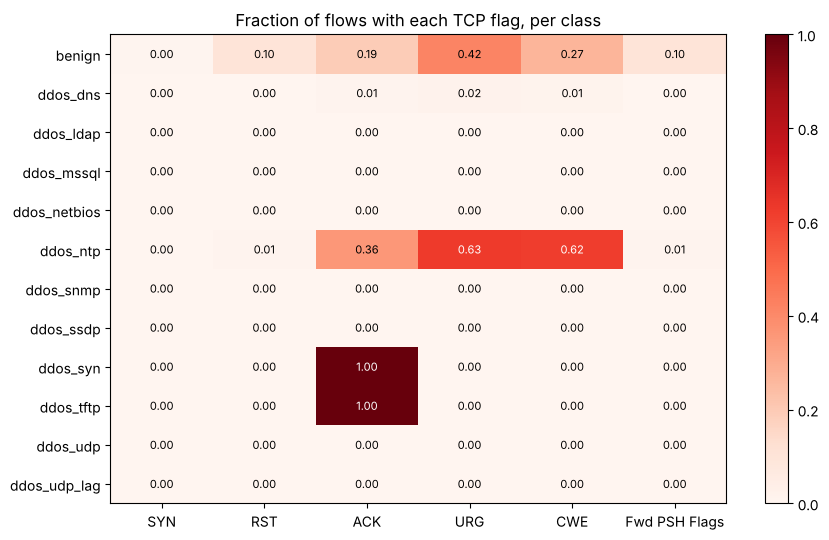

Flows with SYN Flag Count > 0: 38 in the whole dataset, 0 in ddos_syn


In [29]:
FLAGS = ["SYN Flag Count", "RST Flag Count", "ACK Flag Count", "URG Flag Count", "CWE Flag Count", "Fwd PSH Flags"]
flags = df.groupby("label")[FLAGS].mean().reindex(LABELS)
fig, ax = plt.subplots(figsize=(9, 5.5))
im = ax.imshow(flags.values, cmap="Reds", aspect="auto", vmin=0, vmax=1)
ax.set_xticks(range(len(FLAGS)))
ax.set_xticklabels([f.replace(" Flag Count", "") for f in FLAGS])
ax.set_yticks(range(len(LABELS)))
ax.set_yticklabels(LABELS)
for i in range(flags.shape[0]):
    for j in range(flags.shape[1]):
        v = flags.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8, color="white" if v > 0.6 else "black")
ax.set_title("Fraction of flows with each TCP flag, per class")
fig.colorbar(im, ax=ax)
show_figure(fig)
print(f"Flows with SYN Flag Count > 0: {(df['SYN Flag Count'] > 0).sum()} in the whole dataset, "
      f"{(df.loc[df['label'] == 'ddos_syn', 'SYN Flag Count'] > 0).sum()} in ddos_syn")

- **SYN** is practically never set, not even in `ddos_syn` (38 flows in the whole dataset, none of them `ddos_syn`). Instead, the SYN flood shows up as ACK = 1.00, exactly like `ddos_tftp`. The flag counters therefore do not follow TCP semantics: they are features produced by the tool, to be read as such.
- **RST and Fwd PSH** have the same value in every class (0.10 for benign, 0.01 for `ddos_ntp`), as expected, since the two columns are identical (§3.5).
- **URG and CWE** are set only in benign (0.42 and 0.27), `ddos_ntp` (0.63 and 0.62) and a few `ddos_dns` flows.
- **The UDP classes** are at 0, as expected.

### 5.6 Class fingerprint

For each class, the median of 14 features. The medians are log-transformed and then rescaled column by column from 0 (the lowest class, blue) to 1 (the highest, red), so that features with very different units can be shown together: each column compares the classes on one feature.

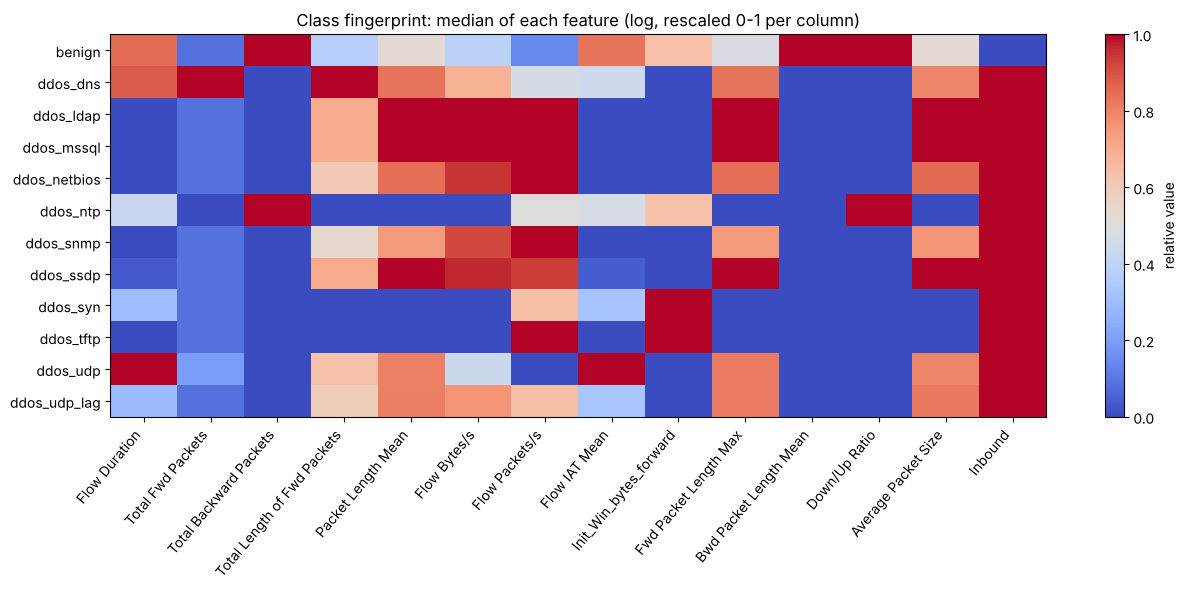

In [30]:
FINGER = KEY_FEATURES + ["Fwd Packet Length Max", "Bwd Packet Length Mean",
                         "Down/Up Ratio", "Average Packet Size", "Inbound"]
med = np.log1p(df.groupby("label")[FINGER].median().reindex(LABELS).clip(lower=0))
norm = (med - med.min()) / (med.max() - med.min()).replace(0, 1)
fig, ax = plt.subplots(figsize=(13, 6))
im = ax.imshow(norm.values, cmap="coolwarm", aspect="auto")
ax.set_xticks(range(len(FINGER)))
ax.set_xticklabels(FINGER, rotation=50, ha="right")
ax.set_yticks(range(len(LABELS)))
ax.set_yticklabels(LABELS)
ax.set_title("Class fingerprint: median of each feature (log, rescaled 0-1 per column)")
fig.colorbar(im, ax=ax, label="relative value")
show_figure(fig)

Reading the heatmap by rows:

- **benign** is the only class with a high `Bwd Packet Length Mean` and the only one with a median `Inbound` of 0; together with `ddos_ntp`, it is the only one with backward packets and a non-zero `Down/Up Ratio`;
- **`ddos_ldap` and `ddos_mssql`** have practically identical rows, and `ddos_ssdp` is very close (short flows, large packets, very high rates);
- **`ddos_syn` and `ddos_tftp`** are also similar: TCP, no payload, high `Init_Win_bytes_forward`.

These groups of similar rows are where a classifier is most likely to confuse one attack with another.

### 5.7 Benign against all the attacks

The same ECDFs as in §5.3, with only two curves: benign traffic and all the attacks together.

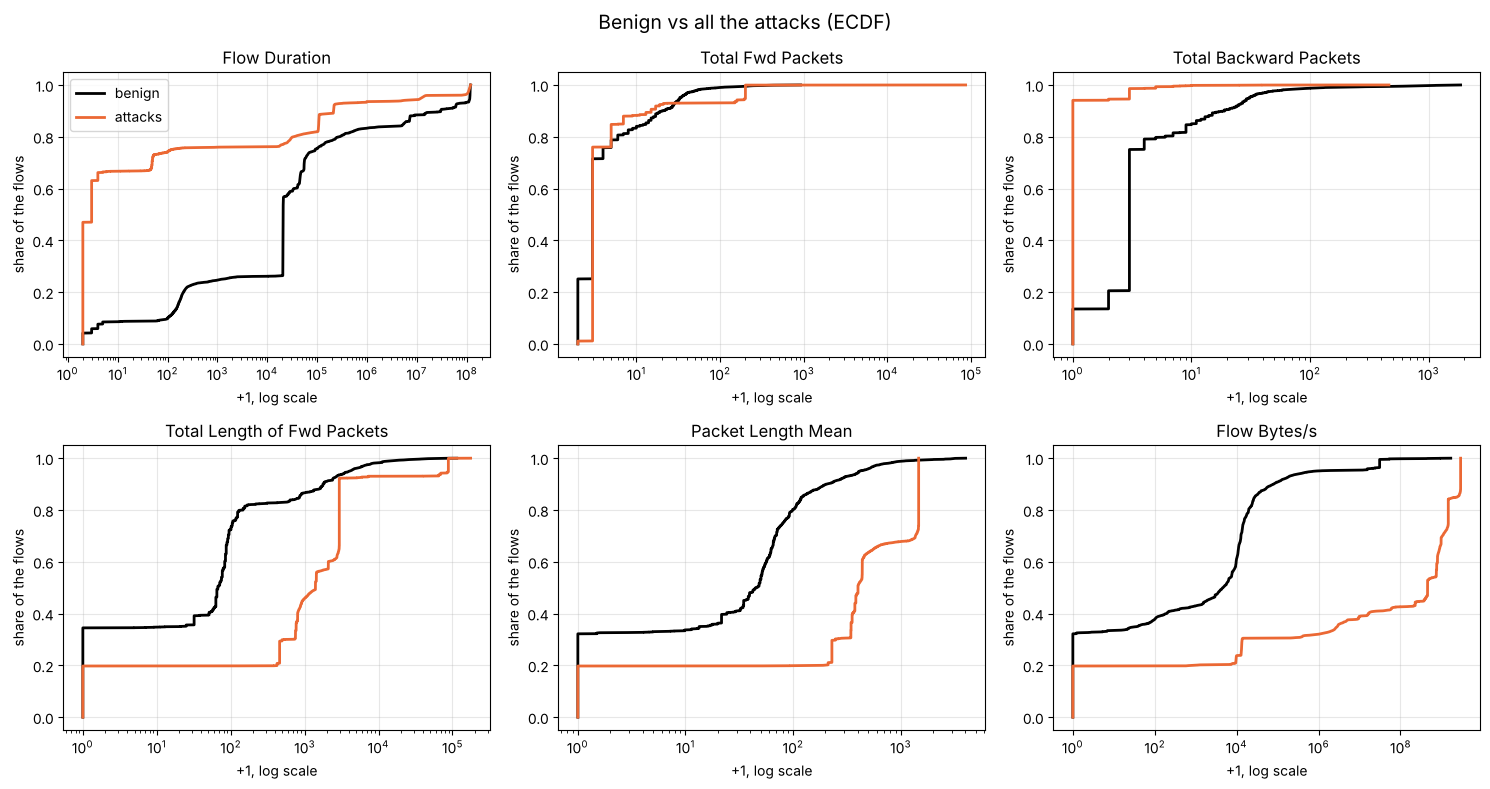

In [31]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, feat in zip(axes.ravel(), KEY_FEATURES[:6]):
    for mask, name, c in [(~IS_ATTACK, "benign", BENIGN_COLOR), (IS_ATTACK, "attacks", ATTACK_COLOR)]:
        x, y = ecdf(df.loc[mask, feat] + 1)
        ax.plot(x, y, label=name, color=c, lw=2)
    ax.set_xscale("log")
    ax.set_title(feat)
    ax.set_xlabel("+1, log scale")
    ax.set_ylabel("share of the flows")
    ax.grid(alpha=0.3)
axes[0, 0].legend()
fig.suptitle("Benign vs all the attacks (ECDF)", fontsize=14)
show_figure(fig)

Taken together, the attacks differ from benign traffic on almost every feature:

- **duration:** most attack flows are a few microseconds long, while most benign flows last from tens of milliseconds upward;
- **backward packets:** more than 90% of attack flows have none, against a minority of benign flows;
- **packet size and rate:** apart from the payload-free SYN and TFTP flows, attack packets are larger (from about 230 bytes up to 1,472), and the attack rates reach 10⁸–10⁹ B/s, against about 10⁴ for benign.

Only `Total Fwd Packets` is similar for the two groups. Telling benign from attack looks easy on this dataset; telling the attacks apart is the harder part (§5.6).

### 5.8 Answers to the questions of point 1.1

The assignment closes point 1.1 with two questions. The answers collect the evidence of §4 and §5; the PCA of §13 confirms them from a different angle.

**1. Can benign traffic be told apart from the attacks?** Yes, and clearly, on almost every feature:

- **duration:** a typical benign flow lasts 21 ms, while six attack classes have a median of 1–2 µs (§5.4);
- **backward packets:** benign flows usually get an answer (median 2 backward packets), while most attack flows have none; only `ddos_ntp` behaves like benign here (§5.1);
- **size and rate:** benign packets are small (31 bytes on average) and the rate is about 10⁴ B/s; the LDAP, MSSQL, NetBIOS, SNMP and SSDP reflections send packets of 229–1,472 bytes at 10⁸–10⁹ B/s (§5.3, §5.4);
- **ports and direction:** most benign flows go to a well-known service port, the attacks to random ports (§5.2); most benign flows have `Inbound` = 0, most attack flows 1 (§7.5).

The exceptions are `ddos_ntp`, which has answers, HTTP requests and destination ports 80 and 22 like benign traffic (§5.2, §6.7), and the benign flows without payload, which resemble `ddos_syn` and `ddos_tftp`.

**2. Which attacks are easy to separate, and which overlap?**

- **Easy:** `ddos_dns` (200 packets of 440 bytes), `ddos_snmp` (229-byte packets), `ddos_netbios` (483 bytes), and `ddos_syn` against the UDP classes (TCP, ACK flag, long flows).
- **Overlapping:**
  - `ddos_ldap`, `ddos_mssql` and `ddos_ssdp`: three UDP reflections with 1,472-byte packets, flows of 1–2 µs and the same rates (§5.4, §5.6). `ddos_ldap` and `ddos_mssql` are practically indistinguishable;
  - `ddos_syn` and `ddos_tftp`: TCP flows without payload, with the same ACK flag and the same initial window (§5.3, §5.5);
  - `ddos_udp` and `ddos_udp_lag`: the same packet size and the same range of durations (§5.4);
  - `ddos_ntp` and benign traffic, as said above.

These groups are where the classifiers of Section 2 will make their mistakes. §8.3 confirms it from another angle: after the cleaning, hundreds of `ddos_ldap`/`ddos_mssql` flows and about a hundred `ddos_syn`/`ddos_tftp` flows are identical feature by feature.

## 6. Anomalous values

This section documents, with numbers, the problems found in the values of the dataset. The decisions are taken in §7–§8, the table anticipates them:

| § | Topic | Decision |
|---|---|---|
| 6.1 | the unnamed index column | not a column: nothing to remove |
| 6.2–6.4 | negative values in `Fwd Header Length` and `min_seg_size_forward` | both columns removed (§7.3) |
| 6.5 | the single negative value of `Bwd Header Length` | the column turns out to be redundant (§7.4) |
| 6.6 | `Init_Win_bytes_forward/backward = −1` | kept: −1 means "not available" (§10.3) |
| 6.7 | `SimillarHTTP`, a text column | turned into a 0/1 column (§8) |

### 6.1 What the unnamed index column tells us

§2.4 showed that the first field of every row is an unnamed index, which pandas uses as row index. Its values run from 0 to 65,999 with gaps: the cell counts the rows of each class in blocks of 6,000 consecutive ids.

In [32]:
ids = df.index
print(f"Index values from {ids.min()} to {ids.max()}: {ids.max() + 1:,} possible ids, "
      f"{len(ids):,} rows, so {ids.max() + 1 - len(ids):,} ids are missing")
print("Increasing and without repetitions:", ids.is_monotonic_increasing and ids.is_unique)

blocks = pd.crosstab(ids // 6000, df["label"]).reindex(columns=LABELS, fill_value=0)
blocks.index = [f"{6000 * b:,}-{6000 * b + 5999:,}" for b in blocks.index]
blocks.index.name = "index ids"
blocks["rows"] = blocks[LABELS].sum(axis=1)
blocks["missing ids"] = 6000 - blocks["rows"]
display(blocks)

Index values from 0 to 65999: 66,000 possible ids, 64,239 rows, so 1,761 ids are missing
Increasing and without repetitions: True


label,benign,ddos_dns,ddos_ldap,ddos_mssql,ddos_netbios,ddos_ntp,ddos_snmp,ddos_ssdp,ddos_syn,ddos_tftp,ddos_udp,ddos_udp_lag,rows,missing ids
index ids,,,,,,,,,,,,,,
"0-5,999",615,5369,0,0,0,0,0,0,0,0,0,0,5984,16
"6,000-11,999",1,0,5928,0,0,0,0,0,0,0,0,0,5929,71
"12,000-17,999",0,0,0,5911,0,0,0,0,0,0,0,0,5911,89
"18,000-23,999",9,0,0,0,5830,0,0,0,0,0,0,0,5839,161
"24,000-29,999",4999,0,0,0,0,986,0,0,0,0,0,0,5985,15
"30,000-35,999",3,0,0,0,0,0,5984,0,0,0,0,0,5987,13
"36,000-41,999",30,0,0,0,0,0,0,5970,0,0,0,0,6000,0
"42,000-47,999",0,0,0,0,0,0,0,0,0,0,5876,0,5876,124
"48,000-53,999",1,0,0,0,0,0,0,0,5480,0,0,0,5481,519


The 66,000 possible ids form 11 blocks of 6,000, one per attack, in the order DNS, LDAP, MSSQL, NetBIOS, NTP, SNMP, SSDP, UDP, SYN, TFTP, UDP-lag. Each block holds a single attack class plus some benign flows; 1,761 ids are missing, mostly in the SYN (519) and TFTP (739) blocks.

The most likely reading: the file was built by taking 6,000 consecutive flows from each of the 11 attack captures of CIC-DDoS2019, which also contain normal traffic, and then deleting some rows (probably those with undefined values, since no flow lasts 0 µs, §3.3). This explains three facts seen so far:

- `ddos_ntp` is small because 4,999 of the 5,985 flows of its block are benign: the NTP capture provides 88% of all benign flows;
- the attacks last less than 2 seconds (§4.5): 6,000 consecutive flows of a flood are a very short slice of time;
- benign flows concentrate in the NTP and DNS windows (§4.5).

The index is not a feature and is not kept, but it tells something important about the data: the benign class is not a sample of a whole day of normal traffic, it is mostly the background traffic of one capture.

### 6.2 Negative values: overview

Counts, durations, lengths, rates and flag counts cannot be negative. The table lists every numeric column with at least one negative value.

In [33]:
neg = (numeric < 0).sum()
neg = neg[neg > 0]
display(pd.DataFrame({
    "negative values": neg,
    "% of flows": (100 * neg / len(df)).round(2),
    "min": numeric[neg.index].min(),
    "distinct negative values": [numeric.loc[numeric[c] < 0, c].nunique() for c in neg.index],
}))

,negative values,% of flows,min,distinct negative values
Fwd Header Length,23581,36.71,-212543795000,349
Bwd Header Length,1,0.00,-2125437950,1
Fwd Header Length.1,23581,36.71,-212543795000,349
Init_Win_bytes_forward,48928,76.17,-1,1
Init_Win_bytes_backward,58018,90.32,-1,1
min_seg_size_forward,23587,36.72,-1062718975,2


Six columns have negative values:

- **a special value** in `Init_Win_bytes_forward` and `Init_Win_bytes_backward`: always −1, in 76.2% and 90.3% of the flows (§6.6);
- **impossible values** in the other four: `Fwd Header Length` and its copy `Fwd Header Length.1` (23,581 flows, 349 distinct negative values, minimum −2.1·10¹¹), `min_seg_size_forward` (23,587 flows, only two negative values) and `Bwd Header Length` (one flow).

### 6.3 `Fwd Header Length` and `min_seg_size_forward`

`Fwd Header Length` is the total size, in bytes, of the headers of the forward packets; `min_seg_size_forward` is the smallest forward segment size. How many rows have a negative value in each, how much do the two sets overlap, and in which classes are they?

In [34]:
fhl_neg = df["Fwd Header Length"] < 0
mss_neg = df["min_seg_size_forward"] < 0
bad = fhl_neg | mss_neg                       # rows with at least one negative value

overlap = pd.Series({
    "Fwd Header Length < 0": fhl_neg.sum(),
    "min_seg_size_forward < 0": mss_neg.sum(),
    "both": (fhl_neg & mss_neg).sum(),
    "only min_seg_size_forward": (~fhl_neg & mss_neg).sum(),
    "at least one (affected rows)": bad.sum(),
}).to_frame("flows")
overlap["% of the dataset"] = (100 * overlap["flows"] / len(df)).round(2)
display(overlap)
print("Transport protocol of the affected rows:", TRANSPORT[bad].value_counts().to_dict(),
      f"- UDP flows in the dataset: {(TRANSPORT == 'UDP').sum():,}")

affected = pd.DataFrame({"flows": df["label"].value_counts(),
                         "affected": df.loc[bad, "label"].value_counts()}).reindex(LABELS).fillna(0).astype(int)
affected["% of the class"] = (100 * affected["affected"] / affected["flows"]).round(1)
affected["flows left if the rows were dropped"] = affected["flows"] - affected["affected"]
display(affected)

,flows,% of the dataset
Fwd Header Length < 0,23581,36.71
min_seg_size_forward < 0,23587,36.72
both,23581,36.71
only min_seg_size_forward,6,0.01
at least one (affected rows),23587,36.72


Transport protocol of the affected rows: {'UDP': 23587} - UDP flows in the dataset: 48,870


,flows,affected,% of the class,flows left if the rows were dropped
label,,,,
benign,5658,1,0.0,5657
ddos_dns,5369,813,15.1,4556
ddos_ldap,5928,2859,48.2,3069
ddos_mssql,5911,1673,28.3,4238
ddos_netbios,5830,897,15.4,4933
ddos_ntp,986,0,0.0,986
ddos_snmp,5984,4615,77.1,1369
ddos_ssdp,5970,868,14.5,5102
ddos_syn,5480,0,0.0,5480


The two sets almost coincide: every row with a negative `Fwd Header Length` also has a negative `min_seg_size_forward`, and only 6 rows have the second without the first. Together they are 23,587 flows, 36.7% of the dataset, all UDP, but less than half of the 48,870 UDP flows. The affected rows are far from random:

- **fully affected:** every flow of `ddos_udp_lag` and all but one of `ddos_udp`;
- **largely affected:** 77.1% of `ddos_snmp` and 48.2% of `ddos_ldap`;
- **partly affected:** between 14.5% and 28.3% of `ddos_dns`, `ddos_mssql`, `ddos_netbios` and `ddos_ssdp`;
- **not affected:** the TCP classes (`ddos_ntp`, `ddos_syn`, `ddos_tftp`), and benign apart from a single flow.

So the problem is not simply "UDP": the 2,132 benign DNS flows of §4.6 are UDP too, yet only one benign flow is hit. The corruption follows the attack captures, not the protocol.

Where do the values come from? `Fwd Header Length` is a sum over the forward packets, so dividing it by `Total Fwd Packets` gives the average value recorded per packet.

In [35]:
garbage = df["min_seg_size_forward"].min()            # the most negative value recorded
per_packet = df.loc[fhl_neg, "Fwd Header Length"] / df.loc[fhl_neg, "Total Fwd Packets"]
pattern = pd.Series(np.select([per_packet == -1, per_packet == garbage],
                              ["-1 for every packet", f"{garbage:,} for every packet"],
                              default="mix of the two, or of invalid and valid packets"),
                    index=per_packet.index)
display(pattern.value_counts().rename_axis("Fwd Header Length / Total Fwd Packets").to_frame("flows"))
display(df.loc[mss_neg, "min_seg_size_forward"].value_counts()
        .rename_axis("negative min_seg_size_forward").to_frame("flows"))

,flows
Fwd Header Length / Total Fwd Packets,
-1 for every packet,21061
"-1,062,718,975 for every packet",2159
"mix of the two, or of invalid and valid packets",361


,flows
negative min_seg_size_forward,
-1,21068
-1062718975,2519


The values are not random overflows:

- **21,061 rows:** `Fwd Header Length` is exactly minus the number of forward packets, so −1 was recorded as the header length of every packet and then summed;
- **2,159 rows:** every packet contributed −1,062,718,975. The same number is the `min_seg_size_forward` of 2,519 rows and appears in the single negative `Bwd Header Length` (§6.5);
- **the remaining 361 rows** mix the two values, or mix them with valid packets.

`min_seg_size_forward`, the minimum over the same packets, accordingly takes only the values −1 and −1,062,718,975. In short, for some UDP packets the extractor recorded an invalid header length (−1 or a constant garbage number), which then propagated into the flow totals.

### 6.4 Drop the rows or drop the columns?

The last column of the per-class table above shows what dropping the 23,587 rows would cost. The alternative, keeping the two columns, has a different cost: a negative value would work as an almost perfect "this is an attack" rule. How good would that rule be?

In [36]:
print("Rule 'negative Fwd Header Length or min_seg_size_forward => attack':")
print(f"  precision {IS_ATTACK[bad].mean():.4%}  ({(~IS_ATTACK[bad]).sum()} benign flow among {bad.sum():,})")
print(f"  it fires on {bad[IS_ATTACK].mean():.1%} of the attack flows ({bad[IS_ATTACK].sum():,} of {IS_ATTACK.sum():,})")

Rule 'negative Fwd Header Length or min_seg_size_forward => attack':
  precision 99.9958%  (1 benign flow among 23,587)
  it fires on 40.3% of the attack flows (23,586 of 58,581)


Both options have a cost, but the costs are not comparable:

- **dropping the 23,587 rows** would remove 36.7% of the dataset and practically delete two classes: `ddos_udp_lag` would keep 0 flows and `ddos_udp` 1. Most of `ddos_snmp` would go too (1,369 left of 5,984);
- **keeping the columns** would hand the model a shortcut. A negative value means "attack" with 99.996% precision (1 benign flow among 23,587), and the rule fires on 40.3% of all attack flows. A model would learn the extractor's bug and would fail on data where the bug is absent or different.

Dropping the two columns sacrifices the forward header length (§6.5 shows that no other column carries it), but keeps all the flows and removes the shortcut. This is step 3 of §7.

### 6.5 `Bwd Header Length`, and how the invalid values distort the correlations

`Bwd Header Length`, the backward counterpart of `Fwd Header Length`, has a single negative value.

In [37]:
bhl_neg = df["Bwd Header Length"] < 0
display(df.loc[bhl_neg, ["label", "Protocol", "Total Fwd Packets", "Total Backward Packets",
                         "Fwd Header Length", "Bwd Header Length", "min_seg_size_forward"]])
print("Bwd Header Length / Total Backward Packets =",
      f"{(df.loc[bhl_neg, 'Bwd Header Length'] / df.loc[bhl_neg, 'Total Backward Packets']).iloc[0]:,.0f}")

,label,Protocol,Total Fwd Packets,Total Backward Packets,Fwd Header Length,Bwd Header Length,min_seg_size_forward
21205,benign,17,2,2,28,-2125437950,14


Bwd Header Length / Total Backward Packets = -1,062,718,975


A single flow, benign and UDP, with 2 backward packets: the value is exactly 2 × −1,062,718,975, the same invalid per-packet value as in §6.3. Its forward columns are valid (28 and 14), so this row is not among the 23,587 of §6.3.

Such values also distort every statistic computed on the raw data, correlation included. The next cell measures it: for each of the three columns, the highest |correlation| with the other numeric measurements, first on all the rows and then only on the rows where the column is not negative.

In [38]:
measurements = numeric.drop(columns=CONSTANT + list(COPIES) + ["Source Port", "Destination Port", "Protocol"])
rows = []
for col in ["Fwd Header Length", "min_seg_size_forward", "Bwd Header Length"]:
    others = measurements.drop(columns=col)
    valid = measurements[col] >= 0
    with np.errstate(all="ignore"), warnings.catch_warnings():
        warnings.simplefilter("ignore")        # columns constant on the subset give NaN
        r_all = others.corrwith(measurements[col]).abs()
        r_valid = others[valid].corrwith(measurements.loc[valid, col]).abs()
    rows.append({"column": col,
                 "best |r|, all rows": f"{r_all.max():.3f}  ({r_all.idxmax()})",
                 "valid rows": f"{valid.sum():,}",
                 "best |r|, valid rows only": f"{r_valid.max():.3f}  ({r_valid.idxmax()})"})
show_left(pd.DataFrame(rows).set_index("column"))

,"best |r|, all rows",valid rows,"best |r|, valid rows only"
column,,,
Fwd Header Length,0.484 (min_seg_size_forward),"40,658",0.383 (act_data_pkt_fwd)
min_seg_size_forward,0.484 (Fwd Header Length),"40,652",0.236 (Average Packet Size)
Bwd Header Length,0.013 (Inbound),"64,238",0.993 (Total Backward Packets)


The invalid values distort the correlations in two different ways:

- **`Fwd Header Length` and `min_seg_size_forward`** correlate mostly with each other (0.484), because their invalid values occur in the same flows. On their valid rows the best correlations drop to 0.383 and 0.236: they are not redundant with any other column, so removing them does lose information that exists nowhere else (the price accepted in §6.4).
- **`Bwd Header Length`** is the striking case. A single value of −2.1·10⁹ makes it look unrelated to everything (best |r| 0.013). On the other 64,238 rows its correlation with `Total Backward Packets` is 0.993: the column is redundant, which an analysis of the raw data could not see. This is why step 4 of §7 measures the correlations on the rows without impossible values.

### 6.6 `Init_Win_bytes_forward` and `Init_Win_bytes_backward` = −1

The initial TCP window of each direction. CICFlowMeter writes −1 when there is no value to report.

In [39]:
for c in ["Init_Win_bytes_forward", "Init_Win_bytes_backward"]:
    minus_one = df[c] == -1
    print(f"{c} = -1 in {minus_one.sum():,} flows ({minus_one.mean():.1%}); "
          f"other negative values: {((df[c] < 0) & ~minus_one).sum()}")
    display(pd.crosstab(TRANSPORT, minus_one.rename(f"{c} = -1")))

tcp_no_bwd_win = (TRANSPORT == "TCP") & (df["Init_Win_bytes_backward"] == -1)
print(f"TCP flows with Init_Win_bytes_backward = -1: {tcp_no_bwd_win.sum():,}, "
      f"of which with no backward packets: {(df.loc[tcp_no_bwd_win, 'Total Backward Packets'] == 0).sum():,}")

Init_Win_bytes_forward = -1 in 48,928 flows (76.2%); other negative values: 0


Init_Win_bytes_forward = -1,False,True
transport,,
TCP,15311,0
UDP,0,48870
other,0,58


Init_Win_bytes_backward = -1 in 58,018 flows (90.3%); other negative values: 0


Init_Win_bytes_backward = -1,False,True
transport,,
TCP,6221,9090
UDP,0,48870
other,0,58


TCP flows with Init_Win_bytes_backward = -1: 9,090, of which with no backward packets: 9,090


`Init_Win_bytes_forward` is −1 in exactly the 48,870 UDP flows and the 58 protocol-0 flows, and never in a TCP flow. `Init_Win_bytes_backward` is −1 in the same flows plus 9,090 TCP flows, all of which have no backward packet.

So −1 means "no TCP window to report": either the protocol has none, or the other side never answered. It is a legitimate value and is kept. It is, however, a category hidden in a numeric column: tree-based models handle it naturally, while models based on distances or linear combinations would treat it as "one byte less than 0". §10.3 splits it into an indicator and a real window size.

### 6.7 `SimillarHTTP`

According to the description of the dataset, this column measures how similar the flow is to HTTP. In practice it contains `0` or, for a few flows, the URL of an HTTP request. With the default reading options pandas guesses the type of each column on blocks of rows, so this column can come out with mixed types; `low_memory=False`, used by `read_raw_csv()` and `load_dataset()`, makes it read the whole column at once.

In [40]:
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    default_read = pd.read_csv(DATA_CSV)                 # default options (low_memory=True)
for w in caught:
    print(f"{w.category.__name__}: {w.message}")
default_read.columns = default_read.columns.str.strip()


def python_types(s):
    return s.map(lambda v: type(v).__name__).value_counts().to_dict()


display(pd.DataFrame({
    "pandas dtype": [str(default_read["SimillarHTTP"].dtype), str(df["SimillarHTTP"].dtype)],
    "Python types of the values": [python_types(default_read["SimillarHTTP"]),
                                   python_types(df["SimillarHTTP"])],
}, index=["read_csv(path)  (default)", "read_csv(path, low_memory=False)"]))
del default_read

,pandas dtype,Python types of the values
read_csv(path) (default),object,"{'str': 40960, 'int': 23279}"
"read_csv(path, low_memory=False)",str,{'str': 64239}


With the default options the blocks that contain only `0` become integers and the others text, so the column ends up with 23,279 integers and 40,960 strings, and pandas emits a `DtypeWarning`. With `low_memory=False`, the option used throughout this notebook, all 64,239 values are strings. The next cell looks at the content: how many values are `0`, in which classes the others appear, and which URLs are the most frequent.

In [41]:
is_zero = df["SimillarHTTP"].astype(str).str.strip() == "0"
print(f"'0': {is_zero.sum():,} flows ({is_zero.mean():.2%}); any other value: {(~is_zero).sum()} flows, "
      f"{df.loc[~is_zero, 'SimillarHTTP'].nunique()} distinct strings")
http_per_class = pd.DataFrame({
    "flows": df["label"].value_counts(),
    "with an HTTP request": df.loc[~is_zero, "label"].value_counts(),
}).reindex(LABELS).fillna(0).astype(int)
http_per_class["%"] = (100 * http_per_class["with an HTTP request"] / http_per_class["flows"]).round(1)
display(http_per_class)
display(df.loc[~is_zero, "SimillarHTTP"].value_counts()
        .sort_index().sort_values(ascending=False, kind="stable")      # ties in alphabetical order
        .head(7).to_frame("flows"))

'0': 63,761 flows (99.26%); any other value: 478 flows, 186 distinct strings


,flows,with an HTTP request,%
label,,,
benign,5658,282,5.0
ddos_dns,5369,18,0.3
ddos_ldap,5928,0,0.0
ddos_mssql,5911,1,0.0
ddos_netbios,5830,0,0.0
ddos_ntp,986,177,18.0
ddos_snmp,5984,0,0.0
ddos_ssdp,5970,0,0.0
ddos_syn,5480,0,0.0


,flows
SimillarHTTP,
205.174.165.72/c.php,151
ocsp.digicert.com/,25
ocsp.pki.goog/GTSGIAG3,24
205.174.165.72/c.php?ip=10.148.118.37,12
205.174.165.72null,8
detectportal.firefox.com/success.txt,6
drmokhberi.ca/favicon.ico,6


`SimillarHTTP` is `0` in 99.26% of the flows. The other 478 flows contain one of 186 URLs: certificate checks (OCSP), Firefox's connectivity check and, most often, requests to `205.174.165.72/c.php`. These strings are specific to the experiment and useless as such, but the presence of a request is informative: it occurs in 282 benign flows (5.0%) and 177 `ddos_ntp` flows (18.0%), and almost nowhere else. So the column is kept as a 0/1 indicator, "the flow contains an HTTP request" (§7.2, §8). That 18% of a class named after an NTP attack contains HTTP requests is another sign, after §4.4, that `ddos_ntp` is not NTP traffic.

# Section 1.2 – Pre-processing

Point 1.2 turns the findings of 1.1 into decisions, in this order:

1. **which columns to keep, and why** (§7): the 87 columns go through a five-step funnel;
2. **the cleaning** (§8): the decisions are applied and the dataset is saved as `data/ddos_pulito.csv`;
3. **correlation on the cleaned data** (§9): Pearson and Spearman, to see what redundancy is left;
4. **encoding** (§10): how the categorical columns, the special values and the label are given to a model;
5. **log transform and scaling** (§11): how the numeric features are brought to comparable scales;
6. **the pipeline** (§12): encoding and scaling in a single object, to be fitted on the training data only;
7. **PCA** (§13): how much the data can be compressed, what the first components mean, and when PCA is worth using.

## 7. Which columns to keep: a five-step funnel

The 87 columns are filtered in five steps, from the most obvious decisions to the ones that need judgement. Each step removes only columns for which the evidence is clear, and passes the others to the next step:

| Step | What is removed | Criterion |
|---|---|---|
| 1 | **identifiers** | they say *who* and *when*, not *how* the traffic behaves: a model would learn the addresses and the times of this experiment instead of the attacks |
| 2 | **certainly useless** columns | constant (§3.4), exact copies of another column (§3.5), almost constant without information |
| 3 | **corrupted** columns | impossible values that would act as a shortcut (§6.3–§6.4) |
| 4 | **redundant** columns | \|correlation\| > 0.95 with a column that is kept: of each group of near-copies only the most useful for DDoS detection stays |
| 5 | **review** of what is left | every remaining column, one by one: kept as it is, kept with a special encoding, or removed |

The function `remove()` records, for every removed column, the step and the reason, and prints how many columns are left. At the end of the section (§7.6) the records give the funnel chart and the full list of the removed columns.

In [42]:
REMOVED = {}        # column -> (step, reason), filled step by step


def remove(step, reasons):
    """Record the columns removed at a step (reasons: {column: reason}); return the columns left."""
    REMOVED.update({c: (step, why) for c, why in reasons.items()})
    left = [c for c in df.columns if c not in REMOVED]
    print(f"Step {step}: {len(reasons)} columns removed -> {len(left)} columns left (label included)")
    return left

### 7.1 Step 1 – identifiers

Four columns identify the flow rather than describe it:

- **`Flow ID`** is the other identifiers pasted together; the cell checks it;
- **`Source IP` and `Destination IP`**: one address sends and one receives about 90% of the flows, and every attack class uses at most two addresses per side (§4.3). A model given the IPs would learn "172.16.0.5 → 192.168.50.1 means attack";
- **`Timestamp`**: each class has its own time window (§4.5), so the time alone would give the class away.

The other three identifiers, `Source Port`, `Destination Port` and `Protocol`, also carry information on how the traffic behaves, so they are not removed blindly: they are reviewed in step 5.

`Timestamp`, `Source IP` and `Destination IP` are removed from the **features**, but they are saved next to the cleaned data as *service columns*, because Section 2 needs them (§8.4).

In [43]:
five_ids = [df[c].astype(str) for c in ["Source IP", "Destination IP", "Source Port", "Destination Port", "Protocol"]]
forward_id = five_ids[0] + "-" + five_ids[1] + "-" + five_ids[2] + "-" + five_ids[3] + "-" + five_ids[4]
reverse_id = five_ids[1] + "-" + five_ids[0] + "-" + five_ids[3] + "-" + five_ids[2] + "-" + five_ids[4]
print(f"Flow ID = 'srcIP-dstIP-srcPort-dstPort-protocol': {(df['Flow ID'] == forward_id).mean():.1%} of the rows; "
      f"same with source and destination swapped: {(df['Flow ID'] == reverse_id).mean():.1%}")

src_share = df["Source IP"].value_counts(normalize=True)
dst_share = df["Destination IP"].value_counts(normalize=True)
left = remove(1, {
    "Flow ID": "the five other identifiers pasted together (§7.1)",
    "Source IP": f"{src_share.index[0]} sends {src_share.iloc[0]:.1%} of the flows; "
                 "at most 2 source IPs per attack class (§4.3)",
    "Destination IP": f"{dst_share.index[0]} receives {dst_share.iloc[0]:.1%} of the flows; "
                      "at most 2 destination IPs per attack class (§4.3)",
    "Timestamp": "every class has its own time window: the time gives the class away (§4.5)",
})

Flow ID = 'srcIP-dstIP-srcPort-dstPort-protocol': 96.7% of the rows; same with source and destination swapped: 3.3%
Step 1: 4 columns removed -> 83 columns left (label included)


`Flow ID` is built from the five identifiers in every row (in 3.3% of the rows with source and destination swapped), so it contains nothing new. 83 columns are left.

### 7.2 Step 2 – certainly useless columns

Three kinds of columns, in increasing order of judgement:

1. **constant columns**: the 12 columns of §3.4, always 0;
2. **exact copies**: the 6 columns of §3.5; the original stays (for now);
3. **almost constant columns**: one value in at least 99% of the rows. These are not automatically useless: a feature that is rare but concentrated in a few classes can be very informative. So the cell lists them with the classes of their rare values, and each one is decided on its own.

`SimillarHTTP` is counted as 0/1 (an HTTP request or not), the form in which it is kept (§6.7).

In [44]:
left = remove(2, {c: f"constant: always {df[c].iloc[0]} (§3.4)" for c in CONSTANT})
left = remove(2, {c: f"exact copy of {original} (§3.5)" for c, original in COPIES.items()})

HTTP_REQUEST = (~is_zero).astype(int)          # SimillarHTTP as 0/1 (§6.7)
near_constant = []
for c in [c for c in left if c != "label"]:
    values = HTTP_REQUEST if c == "SimillarHTTP" else df[c]
    top = values.value_counts()
    if top.iloc[0] / len(values) >= 0.99:
        rare = df.loc[values != top.index[0], "label"].value_counts()
        near_constant.append({"column": c, "most frequent value": top.index[0],
                              "share": f"{top.iloc[0] / len(values):.2%}",
                              "other values (flows)": len(values) - top.iloc[0],
                              "classes of the other values": ", ".join(f"{k} {n}" for k, n in rare.head(4).items())})
show_left(pd.DataFrame(near_constant).set_index("column"))

Step 2: 12 columns removed -> 71 columns left (label included)
Step 2: 6 columns removed -> 65 columns left (label included)


,most frequent value,share,other values (flows),classes of the other values
column,,,,
Fwd PSH Flags,0,99.09%,587,"benign 571, ddos_ntp 9, ddos_dns 5, ddos_ldap 1"
SYN Flag Count,0,99.94%,38,"benign 28, ddos_dns 6, ddos_ssdp 2, ddos_ldap 1"
SimillarHTTP,0,99.26%,478,"benign 282, ddos_ntp 177, ddos_dns 18, ddos_mssql 1"


Three columns are almost constant, and their rare values tell different stories:

- **`Fwd PSH Flags`** is non-zero in 587 flows, 571 of them benign: a rare value, but almost a benign marker. **Kept.**
- **`SimillarHTTP`**: 478 HTTP requests, 282 in benign flows and 177 in `ddos_ntp` (§6.7). **Kept**, as 0/1.
- **`SYN Flag Count`** is non-zero in only 38 flows, and **never** in `ddos_syn` (§5.5): the class named after the SYN flag never has it. It carries practically no information, and its name would mislead anyone reading the results. **Removed.**

In [45]:
syn_rows = int((df["SYN Flag Count"] != 0).sum())
left = remove(2, {"SYN Flag Count": f"almost constant: non-zero in {syn_rows} flows, never in ddos_syn (§5.5)"})

Step 2: 1 columns removed -> 64 columns left (label included)


19 columns removed in this step, 64 left.

### 7.3 Step 3 – corrupted columns

`Fwd Header Length` and `min_seg_size_forward` contain impossible negative values in 23,587 flows (36.7%), all of them attacks but one. Dropping those rows would delete `ddos_udp` and `ddos_udp_lag`; keeping the columns would give the models a 99.996%-precise shortcut "negative header ⇒ attack" (§6.3–§6.4). The columns are removed.

`Bwd Header Length` has a single invalid value (§6.5): one wrong row is not a reason to discard a column, so it goes to step 4, where it turns out to be redundant anyway.

In [46]:
left = remove(3, {
    "Fwd Header Length": f"impossible negative values in {fhl_neg.sum():,} flows, "
                         f"{(~IS_ATTACK[fhl_neg]).sum()} benign: a shortcut to 'attack' (§6.3-§6.4)",
    "min_seg_size_forward": f"impossible negative values in {mss_neg.sum():,} flows, "
                            f"{(~IS_ATTACK[mss_neg]).sum()} benign: a shortcut to 'attack' (§6.3-§6.4)",
})

Step 3: 2 columns removed -> 62 columns left (label included)


### 7.4 Step 4 – redundant columns

Two columns are **redundant** when one can be predicted almost perfectly from the other: keeping both adds no information, only noise and weight for the models. The criterion is the absolute Pearson correlation |r| > 0.95, computed:

- on the numeric measurements left after step 3 (the label, `SimillarHTTP` and the three identifiers of step 5 are excluded);
- on the rows **without impossible values**: the single invalid value of `Bwd Header Length` would otherwise hide its redundancy (§6.5). The −1 of the TCP windows are legitimate and stay.

Pairs above the threshold chain into **families**: if A ≈ B and B ≈ C, then A, B and C are one family, even if A and C are a bit less correlated. The cell finds the pairs and groups them into families.

In [47]:
CANDIDATES = [c for c in left if c not in ["label", "SimillarHTTP", "Source Port", "Destination Port", "Protocol"]]
valid_rows = df["Bwd Header Length"] >= 0                # the only impossible value left (§6.5)
corr = df.loc[valid_rows, CANDIDATES].corr().abs()
pairs = [(a, b) for i, a in enumerate(CANDIDATES) for b in CANDIDATES[i + 1:] if corr.loc[a, b] > 0.95]

families = []                                            # each family: a set of columns
for a, b in pairs:
    joined = [f for f in families if a in f or b in f]   # families already containing a or b
    families = [f for f in families if f not in joined] + [set().union({a, b}, *joined)]
families = sorted((sorted(f, key=CANDIDATES.index) for f in families), key=lambda f: CANDIDATES.index(f[0]))

print(f"{len(CANDIDATES)} columns compared on {valid_rows.sum():,} rows: {len(pairs)} pairs with |r| > 0.95, "
      f"{len(families)} families, {sum(len(f) for f in families)} columns involved")

57 columns compared on 64,238 rows: 43 pairs with |r| > 0.95, 10 families, 33 columns involved


**Which column of a family is kept?** The choice is not random. Four rules, in this order:

1. **the whole flow before a single direction**: `Flow IAT …` rather than `Fwd IAT …`, `Flow Packets/s` rather than `Fwd Packets/s`. Most flows have no backward packets, so the forward statistics repeat those of the flow; the flow-level ones stay meaningful when there are answers;
2. **a basic quantity before a derived one**: `Flow Duration` (measured) rather than `Fwd IAT Total` (the same number in most flows); `Total Backward Packets` rather than the backward bytes or header length, which are essentially packets × size;
3. **a central value before the spread and the extremes**, because it describes the typical packet or pause: `Idle Mean` rather than `Idle Max`/`Idle Min`, `Bwd IAT Mean` rather than `Bwd IAT Std`;
4. **the most useful for DDoS detection when the rules disagree**: for the forward packet size, `Fwd Packet Length Max` is kept, since the size of the largest packet is what identifies an amplification attack (1,472 bytes), and the mean can be recomputed from the kept columns (total bytes / packets).

Several columns of the same family can be kept, when they are *not* above 0.95 with each other: the largest family links `Flow IAT Mean`, `Std` and `Max` and `Idle Mean` only through the forward copies, so the four flow-level columns stay and the forward ones go.

`KEEP` lists the columns kept in the families, with the rule applied. A column of a family is removed when it has |r| > 0.95 with at least one column of `KEEP`; the table shows, for each family, what stays and what goes.

In [48]:
KEEP = {
    "Flow Duration": "rule 2: measured duration (Fwd IAT Total repeats it)",
    "Total Backward Packets": "rule 2: basic count (bytes and header length are ~ packets x size)",
    "Total Length of Fwd Packets": "rule 2: basic total (act_data_pkt_fwd counts the same packets)",
    "Fwd Packet Length Max": "rule 4: size of the largest packet, the signature of amplification",
    "Bwd Packet Length Mean": "rules 2-3: basic mean (Avg Bwd Segment Size is a copy)",
    "Bwd Packet Length Std": "rule 1: per-direction spread (Packet Length Std mixes the directions)",
    "Flow Packets/s": "rule 1: whole flow",
    "Flow IAT Mean": "rule 1: whole flow",
    "Flow IAT Std": "rule 1: whole flow",
    "Flow IAT Max": "rule 1: whole flow",
    "Idle Mean": "rule 3: central value",
    "Flow IAT Min": "rule 1: whole flow",
    "Bwd IAT Mean": "rule 3: central value",
}
keep = list(KEEP)
redundant = {c: (corr.loc[c, keep].idxmax(), corr.loc[c, keep].max())
             for c in CANDIDATES if c not in KEEP and (corr.loc[c, keep] > 0.95).any()}

family_table = pd.DataFrame([{
    "family": i,
    "kept": ", ".join(c for c in fam if c in KEEP),
    "why": "; ".join(dict.fromkeys(KEEP[c] for c in fam if c in KEEP)),      # each rule once
    "removed (|r| with the closest kept column)": "; ".join(
        f"{c} ({redundant[c][1]:.3f} with {redundant[c][0]})" for c in fam if c in redundant),
} for i, fam in enumerate(families, 1)]).set_index("family")
show_left(family_table)

kept_corr = corr.loc[keep, keep].where(~np.eye(len(keep), dtype=bool))
print(f"Columns removed as redundant: {len(redundant)}; every family member is either kept or removed: "
      f"{all(c in KEEP or c in redundant for f in families for c in f)}")
print(f"Highest |r| between two kept columns: {kept_corr.max().max():.3f} "
      f"({kept_corr.max().idxmax()} - {kept_corr[kept_corr.max().idxmax()].idxmax()})")

,kept,why,removed (|r| with the closest kept column)
family,,,
1,Flow Duration,rule 2: measured duration (Fwd IAT Total repeats it),Fwd IAT Total (1.000 with Flow Duration)
2,Total Backward Packets,rule 2: basic count (bytes and header length are ~ packets x size),Total Length of Bwd Packets (0.952 with Total Backward Packets); Bwd Header Length (0.993 with Total Backward Packets)
3,Total Length of Fwd Packets,rule 2: basic total (act_data_pkt_fwd counts the same packets),act_data_pkt_fwd (0.997 with Total Length of Fwd Packets)
4,Fwd Packet Length Max,"rule 4: size of the largest packet, the signature of amplification",Fwd Packet Length Min (0.961 with Fwd Packet Length Max); Fwd Packet Length Mean (0.974 with Fwd Packet Length Max); Min Packet Length (0.961 with Fwd Packet Length Max); Packet Length Mean (0.970 with Fwd Packet Length Max); Average Packet Size (0.968 with Fwd Packet Length Max); Avg Fwd Segment Size (0.974 with Fwd Packet Length Max)
5,Bwd Packet Length Mean,rules 2-3: basic mean (Avg Bwd Segment Size is a copy),Avg Bwd Segment Size (1.000 with Bwd Packet Length Mean)
6,Bwd Packet Length Std,rule 1: per-direction spread (Packet Length Std mixes the directions),Packet Length Std (0.976 with Bwd Packet Length Std)
7,Flow Packets/s,rule 1: whole flow,Fwd Packets/s (1.000 with Flow Packets/s)
8,"Flow IAT Mean, Flow IAT Std, Flow IAT Max, Idle Mean",rule 1: whole flow; rule 3: central value,Fwd IAT Mean (0.986 with Flow IAT Mean); Fwd IAT Std (0.992 with Flow IAT Std); Fwd IAT Max (0.998 with Flow IAT Max); Idle Max (0.986 with Flow IAT Max); Idle Min (0.966 with Idle Mean)
9,Flow IAT Min,rule 1: whole flow,Fwd IAT Min (0.999 with Flow IAT Min)


Columns removed as redundant: 20; every family member is either kept or removed: True
Highest |r| between two kept columns: 0.949 (Flow IAT Mean - Flow IAT Std)


Step 4 finds 43 pairs above 0.95, which chain into 10 families of 33 columns. For each family the table shows the columns kept, the rule that chose them, and the columns removed with their correlation to the closest kept column:

- **forward copies of the flow statistics** (families 1, 7, 8, 9): `Fwd IAT …` and `Fwd Packets/s` correlate 0.986–1.000 with the flow-level versions, because most flows have no backward packets;
- **packet-size measures** (family 4): seven columns that, in flows of identical packets, are almost the same number (0.961–0.974 with `Fwd Packet Length Max`);
- **backward volume** (family 2): bytes and header length of the replies follow the number of backward packets (0.952 and 0.993); for `Bwd Header Length` this is the redundancy hidden by its single invalid value (§6.5);
- **idle times** (family 8): `Idle Max` and `Idle Min` follow `Flow IAT Max` and `Idle Mean` (0.986 and 0.966).

20 columns are removed. The kept columns are not redundant with each other: their highest correlation is 0.949, between `Flow IAT Mean` and `Flow IAT Std`, just below the threshold. Both stay, since 0.95 is the line drawn for the whole funnel; §9 and §17 come back to this group.

**Exact formulas.** Several removed columns are not just correlated with a kept one: they can be recomputed from the kept columns. The cell checks a few formulas row by row (relative tolerance 10⁻⁶), which shows that removing them loses nothing.

In [49]:
FORMULAS = [
    ("Fwd Packet Length Mean", "Total Length of Fwd Packets / Total Fwd Packets",
     df["Total Length of Fwd Packets"] / df["Total Fwd Packets"]),
    ("Total Length of Bwd Packets", "Bwd Packet Length Mean x Total Backward Packets",
     df["Bwd Packet Length Mean"] * df["Total Backward Packets"]),
    ("Avg Bwd Segment Size", "Bwd Packet Length Mean", df["Bwd Packet Length Mean"]),
    ("Fwd Packets/s", "Flow Packets/s - Bwd Packets/s", df["Flow Packets/s"] - df["Bwd Packets/s"]),
    ("Fwd IAT Total", "Flow Duration", df["Flow Duration"]),
    ("Packet Length Variance", "Packet Length Std ^ 2", df["Packet Length Std"] ** 2),
]
show_left(pd.DataFrame([{"removed column": col, "= formula": formula,
                         "% of rows where it holds": round(100 * np.isclose(df[col], value, rtol=1e-6, atol=1e-9).mean(), 2)}
                        for col, formula, value in FORMULAS]).set_index("removed column"))

,= formula,% of rows where it holds
removed column,,
Fwd Packet Length Mean,Total Length of Fwd Packets / Total Fwd Packets,100.00
Total Length of Bwd Packets,Bwd Packet Length Mean x Total Backward Packets,100.00
Avg Bwd Segment Size,Bwd Packet Length Mean,100.00
Fwd Packets/s,Flow Packets/s - Bwd Packets/s,100.00
Fwd IAT Total,Flow Duration,91.08
Packet Length Variance,Packet Length Std ^ 2,100.00


Five of the six formulas hold in every row: `Fwd Packet Length Mean`, `Total Length of Bwd Packets`, `Avg Bwd Segment Size` and `Fwd Packets/s` can be recomputed exactly from kept columns, so removing them loses nothing at all. `Fwd IAT Total` equals `Flow Duration` in 91.08% of the rows; it differs when a backward packet comes after the last forward one. `Packet Length Variance` is exactly the square of `Packet Length Std`, a removed column: the next cell deals with it.

In [50]:
plv_partner = corr.loc["Packet Length Variance", keep + [c for c in CANDIDATES if c not in KEEP and c not in redundant]]
plv_partner = plv_partner.drop("Packet Length Variance")
left = remove(4, {c: f"|r| = {r:.3f} with {k} (kept)" for c, (k, r) in redundant.items()})
left = remove(4, {"Packet Length Variance": f"= Packet Length Std squared, which is redundant; "
                                            f"best kept partner {plv_partner.idxmax()} ({plv_partner.max():.3f})"})

Step 4: 20 columns removed -> 42 columns left (label included)
Step 4: 1 columns removed -> 41 columns left (label included)


`Packet Length Variance` is the only removed column that is not above 0.95 with any kept column: its best kept partner is `Bwd Packet Length Max`, at 0.876. It is removed anyway, because it is a pure derivation (the square of `Packet Length Std`), and the spread of the packet sizes survives in the forward and backward standard deviations, which are kept. Step 4 removes 21 columns in total; 41 are left (40 plus the label).

### 7.5 Step 5 – review of the remaining columns

After four steps, 40 columns (plus the label) are left. Here each of them is looked at individually, by family, with the decision and the reason. The decisions are of four kinds:

- **keep**: the column is a measurement that describes how the traffic behaves;
- **keep, with an encoding**: the information is useful but the raw values are not suitable for a model (a port number, a code, a special value): §10 explains the encoding;
- **keep, with a switch**: the column is useful but may be a shortcut; Section 2 must test the models with and without it;
- **remove**: the column would let the model memorise the experiment.

The table is written by hand; the `assert` checks that it covers exactly the columns left.

In [51]:
REVIEW = {
    # identifiers
    "Source Port": ("remove", "port chosen by the tools or the OS: random in the floods, fixed per tool in the reflections (§5.2); discussed below"),
    "Destination Port": ("keep, as 3 IANA ranges (one-hot)", "a service port for most benign flows, a random port for the attacks (§5.2); the raw number would be memorised"),
    "Protocol": ("keep, one-hot", "separates the TCP classes (ddos_syn, ddos_tftp, ddos_ntp) from the UDP ones (§4.4); a code, not a quantity"),
    # duration and volume
    "Flow Duration": ("keep", "the most separating feature: 1-2 µs for the reflections, milliseconds or more for benign traffic (§5.3)"),
    "Total Fwd Packets": ("keep", "200 packets for ddos_dns, 2 for most reflections (§5.4)"),
    "Total Backward Packets": ("keep", "whether the other side answers: almost only benign and ddos_ntp (§5.1)"),
    "Total Length of Fwd Packets": ("keep", "bytes sent by the source; kept for its family in step 4"),
    "Down/Up Ratio": ("keep", "replies vs requests: median 1 for benign and ddos_ntp, 0 for the other classes (§5.6)"),
    # packet size
    "Fwd Packet Length Max": ("keep", "packet size of the attack: 229 B SNMP, 440 B DNS, 483 B NetBIOS, 1,472 B LDAP/MSSQL/SSDP (§5.4)"),
    "Fwd Packet Length Std": ("keep", "spread of the forward packet sizes: 0 when all the packets are equal (86% of the flows); ddos_udp is the only class with a non-zero median"),
    "Bwd Packet Length Max": ("keep", "size of the replies: non-zero almost only in benign and ddos_ntp"),
    "Bwd Packet Length Min": ("keep", "size of the replies (smallest)"),
    "Bwd Packet Length Mean": ("keep", "size of the replies (typical); kept for its family in step 4"),
    "Bwd Packet Length Std": ("keep", "spread of the reply sizes; kept for its family in step 4"),
    "Max Packet Length": ("keep", "largest packet in either direction; |r| below 0.95 with Fwd Packet Length Max (§9 compares them again)"),
    # rates
    "Flow Bytes/s": ("keep", "intensity: up to 10^9 B/s for the volumetric attacks, about 10^4 for benign traffic (§5.3)"),
    "Flow Packets/s": ("keep", "packets per second of the whole flow; kept for its family in step 4"),
    "Bwd Packets/s": ("keep", "rate of the replies"),
    # inter-arrival times
    "Flow IAT Mean": ("keep", "typical gap between packets: microseconds in a flood, milliseconds in normal traffic"),
    "Flow IAT Std": ("keep", "regularity of the gaps: tools send at a constant pace"),
    "Flow IAT Max": ("keep", "longest gap: the pauses of interactive traffic"),
    "Flow IAT Min": ("keep", "shortest gap: bursts"),
    "Bwd IAT Total": ("keep", "timing of the replies (absent in most attacks)"),
    "Bwd IAT Mean": ("keep", "timing of the replies; kept for its family in step 4"),
    "Bwd IAT Max": ("keep", "timing of the replies"),
    "Bwd IAT Min": ("keep", "timing of the replies"),
    # TCP flags and windows
    "Fwd PSH Flags": ("keep", "rare (587 flows) but almost only benign (step 2)"),
    "ACK Flag Count": ("keep", "1 in every ddos_syn and ddos_tftp flow (§5.5)"),
    "URG Flag Count": ("keep", "set in 42% of the benign and 63% of the ddos_ntp flows, never in the floods (§5.5)"),
    "CWE Flag Count": ("keep", "set in 27% of the benign and 62% of the ddos_ntp flows (§5.5)"),
    "Init_Win_bytes_forward": ("keep, -1 -> indicator", "initial TCP window: 5,840 in ddos_syn and ddos_tftp; -1 means 'no window' (§6.6, §10.3)"),
    "Init_Win_bytes_backward": ("keep, -1 -> indicator", "window of the answering side; -1 when there is no answer or no TCP (§6.6, §10.3)"),
    # activity and idle
    "Active Mean": ("keep", "activity before a pause: non-zero in 42% of the ddos_syn flows and 11% of the benign ones, almost never in the reflections"),
    "Active Std": ("keep", "activity periods (spread)"),
    "Active Max": ("keep", "activity periods (longest)"),
    "Active Min": ("keep", "activity periods (shortest)"),
    "Idle Mean": ("keep", "length of the pauses; kept for its family in step 4"),
    "Idle Std": ("keep", "regularity of the pauses"),
    # content and direction
    "SimillarHTTP": ("keep, as 0/1", "an HTTP request: 5% of the benign and 18% of the ddos_ntp flows, almost never elsewhere (§6.7)"),
    "Inbound": ("keep, with a switch", "direction of the flow, derived from the IPs: possible shortcut; discussed below"),
}
assert sorted(REVIEW) == sorted(c for c in left if c != "label"), "the review does not match the columns left"

review = pd.DataFrame([{"column": c, "family": FAMILY_OF[c], "decision": d, "why": why}
                       for c, (d, why) in REVIEW.items()]).set_index("column")
show_left(review)
print(review["decision"].value_counts().to_string())

,family,decision,why
column,,,
Source Port,identifiers,remove,"port chosen by the tools or the OS: random in the floods, fixed per tool in the reflections (§5.2); discussed below"
Destination Port,identifiers,"keep, as 3 IANA ranges (one-hot)","a service port for most benign flows, a random port for the attacks (§5.2); the raw number would be memorised"
Protocol,identifiers,"keep, one-hot","separates the TCP classes (ddos_syn, ddos_tftp, ddos_ntp) from the UDP ones (§4.4); a code, not a quantity"
Flow Duration,duration,keep,"the most separating feature: 1-2 µs for the reflections, milliseconds or more for benign traffic (§5.3)"
Total Fwd Packets,volume,keep,"200 packets for ddos_dns, 2 for most reflections (§5.4)"
Total Backward Packets,volume,keep,whether the other side answers: almost only benign and ddos_ntp (§5.1)
Total Length of Fwd Packets,volume,keep,bytes sent by the source; kept for its family in step 4
Down/Up Ratio,volume,keep,"replies vs requests: median 1 for benign and ddos_ntp, 0 for the other classes (§5.6)"
Fwd Packet Length Max,packet size,keep,"packet size of the attack: 229 B SNMP, 440 B DNS, 483 B NetBIOS, 1,472 B LDAP/MSSQL/SSDP (§5.4)"


decision
keep                                33
keep, -1 -> indicator                2
remove                               1
keep, as 3 IANA ranges (one-hot)     1
keep, one-hot                        1
keep, as 0/1                         1
keep, with a switch                  1


Of the 40 columns, 33 are kept as they are, 6 are kept with a special encoding or a switch, and one is removed. The two that need a discussion are `Source Port` and `Inbound`.

#### `Source Port`: removed

`Source Port` is the port from which the flow was sent. The evidence of §5.2 points both ways.

**Against keeping it**

- It is mostly an arbitrary number. In `ddos_netbios`, `ddos_syn`, `ddos_tftp`, `ddos_udp` and `ddos_udp_lag` it is practically random, and in benign traffic it is usually a temporary port chosen by the operating system.
- Where it is not random, it reflects the configuration of the attack tools, not the protocol: 900 for 94% of `ddos_ldap`, 634 for 77% of `ddos_dns`, and no reflection class uses the port of its service. A model could memorise these values exactly as it would memorise the IPs, and they would not carry over to another capture.
- A port is a label, not a quantity: used as a number, it invites splits on arbitrary ranges.

**For keeping it**

- It keeps flows distinguishable: without it, many more rows become exact duplicates, and more flows appear with identical features but different labels (§8.3 measures it).
- Part of its information is genuine: a low source port in benign traffic marks a reply from a server (443, 80).

**Decision: removed.** The assignment lists it among the identifiers, and the main argument for keeping it, the extra separation, is exactly what makes it dangerous: the classes it separates are separated by the settings of the tools of this experiment. The price is measured in §8.3.

In [52]:
left = remove(5, {"Source Port": "set by the tools or the OS, not by the behaviour of the flow: would be memorised (§5.2, §7.5)"})

Step 5: 1 columns removed -> 40 columns left (label included)


#### `Inbound`: kept, with a switch

According to the description of the dataset, `Inbound` tells whether the flow is directed towards the monitored network (1) or leaves it (0). It looks like a behavioural feature, but it is not measured on the packets: CICFlowMeter derives it from the IP addresses. The cell checks this, and shows how the column is distributed among the classes.

In [53]:
victim = dst_share.index[0]
display(pd.crosstab((df["Destination IP"] == victim).map({True: f"{victim} (victim)", False: "any other address"})
                    .rename("destination"), df["Inbound"]))
display((df.groupby("label")["Inbound"].mean().reindex(LABELS) * 100).round(1)
        .rename("% of flows with Inbound = 1").to_frame().T)

Inbound,0,1
destination,,
192.168.50.1 (victim),0,58000
any other address,5167,1072


label,benign,ddos_dns,ddos_ldap,ddos_mssql,ddos_netbios,ddos_ntp,ddos_snmp,ddos_ssdp,ddos_syn,ddos_tftp,ddos_udp,ddos_udp_lag
% of flows with Inbound = 1,19.1,95.2,99.9,100.0,100.0,68.0,100.0,100.0,100.0,100.0,100.0,100.0


**`Inbound` is derived from the IP addresses.** All the 58,000 flows sent to the victim (192.168.50.1) have `Inbound` = 1; among the flows towards any other address, 5,167 have 0 and 1,072 have 1. The column is almost a yes/no version of "is the destination the victim's network?".

As a consequence it can work as a shortcut: only 19.1% of the benign flows have `Inbound` = 1, against 95–100% of every attack class except `ddos_ntp` (68%). A model can use it to separate benign traffic from the attacks without looking at how the flows behave.

**Why it is not simply removed, like the IPs.** Unlike an IP address, the direction of a flow with respect to the protected network exists on any network: a real detector always knows whether a flow is entering or leaving. That a DDoS is directed towards the victim is a genuine characteristic of the attack, not an accident of this testbed. The column is half shortcut and half legitimate feature, and only the models can tell how much they depend on it.

**Decision: kept, with a switch.** `REMOVE_INBOUND = False` below. In Section 2 the same model should be trained twice, with `Inbound` and without it (set the switch to True and rerun the notebook):

- if the results barely change, the model has learned the behaviour of the traffic;
- if they drop sharply, the model was leaning on the direction, and this is worth reporting.

The same comparison is worth doing for `Destination Port`, which is kept only as three ranges.

In [54]:
REMOVE_INBOUND = False        # True: Inbound is removed as well
if REMOVE_INBOUND:
    left = remove(5, {"Inbound": "derived from the IP addresses: possible shortcut (§7.5)"})
print(f"Inbound among the columns kept: {'Inbound' in left}")

Inbound among the columns kept: True


### 7.6 The funnel at a glance

The chart shows how many columns survive each step; the table lists all the removed columns with their step and reason, as recorded by `remove()`.

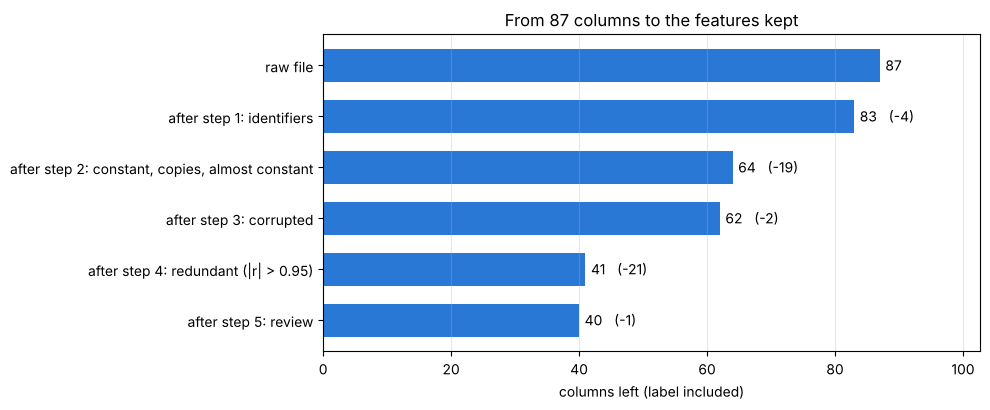

,step,family,reason
column,,,
Flow ID,1,identifiers,the five other identifiers pasted together (§7.1)
Source IP,1,identifiers,172.16.0.5 sends 90.3% of the flows; at most 2 source IPs per attack class (§4.3)
Destination IP,1,identifiers,192.168.50.1 receives 90.3% of the flows; at most 2 destination IPs per attack class (§4.3)
Timestamp,1,identifiers,every class has its own time window: the time gives the class away (§4.5)
Bwd PSH Flags,2,TCP flags,constant: always 0 (§3.4)
Fwd URG Flags,2,TCP flags,constant: always 0 (§3.4)
Bwd URG Flags,2,TCP flags,constant: always 0 (§3.4)
FIN Flag Count,2,TCP flags,constant: always 0 (§3.4)
PSH Flag Count,2,TCP flags,constant: always 0 (§3.4)


In [55]:
STEP_NAMES = {1: "identifiers", 2: "constant, copies, almost constant", 3: "corrupted",
              4: "redundant (|r| > 0.95)", 5: "review"}
removed_per_step = pd.Series([step for step, _ in REMOVED.values()]).value_counts().reindex(STEP_NAMES, fill_value=0)
stages = ["raw file"] + [f"after step {s}: {n}" for s, n in STEP_NAMES.items()]
columns_left = [df.shape[1]] + list(df.shape[1] - removed_per_step.cumsum())

fig, ax = plt.subplots(figsize=(10, 4.2))
bars = ax.barh(stages[::-1], columns_left[::-1], color="#2a78d6", height=0.65)
ax.bar_label(bars, labels=[f"{n}" + (f"   (-{r})" if r else "")
                           for n, r in zip(columns_left[::-1], ([0] + list(removed_per_step))[::-1])],
             padding=4, fontsize=10)
ax.set_xlim(0, df.shape[1] * 1.18)
ax.set_xlabel("columns left (label included)")
ax.set_title("From 87 columns to the features kept")
ax.grid(axis="x", alpha=0.3)
show_figure(fig)

removed_table = pd.DataFrame([{"column": c, "step": s, "family": FAMILY_OF[c], "reason": why}
                              for c, (s, why) in REMOVED.items()]).set_index("column")
show_left(removed_table)

From 87 columns to 40 (39 features and the label) in five steps:

- **step 1** removes the 4 identifiers;
- **step 2** is the largest cut: 12 constant columns, 6 copies and `SYN Flag Count`, 19 columns without information;
- **step 3** removes the 2 corrupted columns;
- **step 4** removes 21 redundant columns, about a quarter of the file: CICFlowMeter computes many statistics in several nearly equivalent versions;
- **step 5** removes `Source Port`; `Inbound` stays, as set by the switch.

The table lists the 47 removed columns (4 + 19 + 2 + 21 + 1), each with its step and evidence: it is the reference for the report.

Finally, the configuration used by the cleaning of §8:

- `REMOVE`: the removed columns, as recorded by the funnel;
- `SERVICE_COLUMNS`: the three identifiers saved next to the cleaned data for Section 2 (not features);
- `MINUS_ONE_ALLOWED`: the two columns where −1 is a legitimate value (§6.6).

In [56]:
REMOVE = list(REMOVED)
SERVICE_COLUMNS = ["Timestamp", "Source IP", "Destination IP"]
MINUS_ONE_ALLOWED = ["Init_Win_bytes_forward", "Init_Win_bytes_backward"]
print(f"{len(REMOVE)} columns removed | Inbound removed: {REMOVE_INBOUND} | "
      f"features kept: {len(left) - 1} + label")

47 columns removed | Inbound removed: False | features kept: 39 + label


## 8. Cleaning

The function `clean_dataset()` applies the decisions of §6–§7 to the raw file:

1. it removes the columns of the funnel, except the service columns (`Timestamp`, `Source IP`, `Destination IP`), which are kept aside for Section 2;
2. if `Bwd Header Length` were kept, it would drop the row with its negative value (§6.5); since the column is removed, the row stays, because its other values are valid;
3. it turns `SimillarHTTP` into a 0/1 column: 1 if the flow contains an HTTP request (§6.7);
4. it removes duplicate rows, which could otherwise end up in both the training and the test set and make a model look better than it is. Duplicates are searched on the features and the label only: the service columns differ in almost every row, so including them would hide every duplicate.

Its `assert` statements stop the notebook if any missing, infinite, negative (apart from `Init_Win_bytes_* = −1`) or non-numeric value is left among the features. The checks are repeated one by one in §8.2, so that their results are visible.

### 8.1 The cleaning function

In [57]:
def clean_dataset(raw, remove=None):
    """Apply the cleaning decisions to the raw dataset and check the result.
    remove: the columns to drop (default: REMOVE, the list of §7).
    Returns the service columns first, then the features and the label."""
    remove = REMOVE if remove is None else remove
    ddos = raw.copy()
    ddos.columns = ddos.columns.str.strip()
    if INDEX_COL in ddos.columns:                  # unnamed index column, if any (§2.4)
        ddos = ddos.drop(columns=INDEX_COL)

    # 1. the columns of the funnel (the warning reveals typos), service columns aside
    missing = [c for c in remove if c not in ddos.columns]
    if missing:
        print("WARNING - columns not found:", missing)
    service = [c for c in SERVICE_COLUMNS if c in ddos.columns]
    ddos = ddos.drop(columns=[c for c in remove if c not in service], errors="ignore")

    # 2. the negative Bwd Header Length (§6.5), only if the column is kept
    if "Bwd Header Length" in ddos.columns:
        ddos = ddos[ddos["Bwd Header Length"] >= 0]

    # 3. SimillarHTTP: 1 if the flow contains an HTTP request, 0 otherwise (§6.7)
    ddos["SimillarHTTP"] = (ddos["SimillarHTTP"].astype(str).str.strip() != "0").astype(int)

    # 4. duplicate rows, searched on the features and the label only
    features_and_label = [c for c in ddos.columns if c not in service]
    ddos = ddos[~ddos.duplicated(subset=features_and_label)]
    ddos = ddos[service + features_and_label].reset_index(drop=True)

    # checks on the features
    features = ddos[[c for c in features_and_label if c != "label"]]
    numeric = features.select_dtypes("number")
    assert features.isna().sum().sum() == 0, "There are still missing values"
    assert not np.isinf(numeric).values.any(), "There are infinite values"
    negative = (numeric.drop(columns=MINUS_ONE_ALLOWED, errors="ignore") < 0).sum()
    negative = negative[negative > 0]
    assert negative.empty, f"Unexpected negative values:\n{negative}"
    non_numeric = [c for c in features.columns if c not in numeric.columns]
    assert not non_numeric, f"Non-numeric columns: {non_numeric}"
    return ddos


ddos = clean_dataset(raw)
FEATURES = [c for c in ddos.columns if c not in SERVICE_COLUMNS + ["label"]]
print(f"Cleaned dataset: {len(ddos):,} rows x {ddos.shape[1]} columns = "
      f"{len(SERVICE_COLUMNS)} service columns + {len(FEATURES)} features + label")

Cleaned dataset: 63,268 rows x 43 columns = 3 service columns + 39 features + label


The cleaned dataset has 63,268 rows and 43 columns: the 3 service columns, 39 features and the label. The `assert` statements inside the function passed.

### 8.2 Checks

In [58]:
features = ddos[FEATURES]
numeric_features = features.select_dtypes("number")
checks = pd.DataFrame([
    ("rows", f"{len(ddos):,}", f"{len(df):,} raw rows - {len(df) - len(ddos):,} removed"),
    ("columns", ddos.shape[1], f"{len(SERVICE_COLUMNS)} service + {len(FEATURES)} features + label"),
    ("'Unnamed: 0' among the columns", INDEX_COL in ddos.columns, "must be False"),
    ("removed columns still among the features", sum(c in FEATURES for c in REMOVE), "must be 0"),
    ("missing values (NaN) in the features", int(features.isna().sum().sum()), "must be 0"),
    ("infinite values", int(np.isinf(numeric_features).values.sum()), "must be 0"),
    ("negative values outside Init_Win_bytes_*",
     int((numeric_features.drop(columns=MINUS_ONE_ALLOWED, errors="ignore") < 0).sum().sum()), "must be 0"),
    ("Init_Win_bytes_forward / _backward = -1 (kept on purpose)",
     " / ".join(f"{(ddos[c] == -1).sum():,}" for c in MINUS_ONE_ALLOWED), "'not available' (§6.6)"),
    ("non-numeric features", [c for c in FEATURES if c not in numeric_features.columns], "must be empty"),
    ("duplicate rows (features + label)", int(ddos[FEATURES + ["label"]].duplicated().sum()), "must be 0"),
    ("constant features", [c for c in FEATURES if ddos[c].nunique() <= 1], "must be empty"),
    ("values of SimillarHTTP", sorted(ddos["SimillarHTTP"].unique().tolist()), "0/1 (§6.7)"),
    ("Source Port among the features", "Source Port" in FEATURES, "removed (§7.5)"),
    ("Inbound among the features", "Inbound" in FEATURES, f"REMOVE_INBOUND = {REMOVE_INBOUND} (§7.5)"),
], columns=["check", "result", "expected / note"]).set_index("check")
show_left(checks)

sizes = pd.DataFrame({"before": df["label"].value_counts(),
                      "after": ddos["label"].value_counts()}).reindex(LABELS)
sizes["removed"] = sizes["before"] - sizes["after"]
sizes["% removed"] = (100 * sizes["removed"] / sizes["before"]).round(1)
display(sizes)

,result,expected / note
check,,
rows,"63,268","64,239 raw rows - 971 removed"
columns,43,3 service + 39 features + label
'Unnamed: 0' among the columns,False,must be False
removed columns still among the features,0,must be 0
missing values (NaN) in the features,0,must be 0
infinite values,0,must be 0
negative values outside Init_Win_bytes_*,0,must be 0
Init_Win_bytes_forward / _backward = -1 (kept on purpose),"48,511 / 57,103",'not available' (§6.6)
non-numeric features,[],must be empty


,before,after,removed,% removed
label,,,,
benign,5658,5478,180,3.2
ddos_dns,5369,5367,2,0.0
ddos_ldap,5928,5836,92,1.6
ddos_mssql,5911,5796,115,1.9
ddos_netbios,5830,5829,1,0.0
ddos_ntp,986,941,45,4.6
ddos_snmp,5984,5874,110,1.8
ddos_ssdp,5970,5896,74,1.2
ddos_syn,5480,5329,151,2.8


All the checks pass:

- **rows:** 971 of the 64,239 raw rows are removed, all of them duplicates. The benign flow with the negative `Bwd Header Length` (§6.5) is not among them: the column is removed, and the rest of the row is valid;
- **features:** no missing, infinite or non-numeric value, no constant column, no duplicate row. The only negative values are the −1 of the two `Init_Win_bytes` columns (48,511 and 57,103 flows), kept on purpose and handled in §10.3;
- **decisions:** `Source Port` is gone, `Inbound` is kept as set by the switch.

The duplicates are not spread evenly. They hit the classes made of very regular flows: `ddos_tftp` loses 193 flows (3.7%), `ddos_syn` 151, `ddos_mssql` 115, `ddos_snmp` 110, `ddos_ldap` 92. `ddos_ntp` loses 45 flows, 4.6%, the largest share, and goes down to 941 flows. Benign traffic loses 180 flows (3.2%): almost all are short HTTPS attempts, two packets towards port 443 with no answer, repeated identically by the same hosts. `ddos_udp` loses none.

### 8.3 Duplicates and ambiguous rows

Removing columns makes some flows identical: two flows that differed only in an identifier now have the same values everywhere. Some of them even carry *different* labels: the same feature vector appears once as one attack and once as another. No model can classify both correctly, so these **ambiguous rows** set a ceiling on the accuracy that Section 2 can reach.

The cell counts the ambiguous rows per class and measures the price of removing `Source Port`, by repeating the cleaning with `Source Port` kept.

In [59]:
def ambiguous_rows(frame):
    """Rows whose feature values also appear, identical, with another label."""
    cols = [c for c in frame.columns if c not in SERVICE_COLUMNS + ["label"]]
    return frame.groupby(cols, dropna=False)["label"].transform("nunique") > 1


with_source_port = clean_dataset(raw, remove=[c for c in REMOVE if c != "Source Port"])
display(pd.DataFrame({
    "with Source Port": [len(raw) - len(with_source_port), int(ambiguous_rows(with_source_port).sum())],
    "without Source Port (chosen)": [len(raw) - len(ddos), int(ambiguous_rows(ddos).sum())],
}, index=["rows removed as duplicates", "ambiguous rows"]))

amb = ambiguous_rows(ddos)
ambiguous_per_class = pd.DataFrame({
    "flows": ddos["label"].value_counts(),
    "ambiguous": ddos.loc[amb, "label"].value_counts(),
}).reindex(LABELS).fillna(0).astype(int)
ambiguous_per_class["% of the class"] = (100 * ambiguous_per_class["ambiguous"] / ambiguous_per_class["flows"]).round(1)
display(ambiguous_per_class)

groups = ddos[amb].groupby(FEATURES, dropna=False)["label"].agg(lambda s: " + ".join(sorted(set(s))))
display(groups.value_counts().rename_axis("classes sharing identical features").to_frame("groups of identical flows"))

,with Source Port,without Source Port (chosen)
rows removed as duplicates,2,971
ambiguous rows,92,1032


,flows,ambiguous,% of the class
label,,,
benign,5478,0,0.0
ddos_dns,5367,38,0.7
ddos_ldap,5836,300,5.1
ddos_mssql,5796,289,5.0
ddos_netbios,5829,11,0.2
ddos_ntp,941,6,0.6
ddos_snmp,5874,0,0.0
ddos_ssdp,5896,139,2.4
ddos_syn,5329,101,1.9


,groups of identical flows
classes sharing identical features,
ddos_ldap + ddos_mssql,219
ddos_syn + ddos_tftp,101
ddos_ldap + ddos_ssdp,65
ddos_mssql + ddos_ssdp,57
ddos_udp + ddos_udp_lag,23
ddos_dns + ddos_ssdp,13
ddos_dns + ddos_ldap,9
ddos_dns + ddos_mssql,8
ddos_dns + ddos_ntp,6


**The price of removing `Source Port`.** With the port, the cleaning would remove only 2 duplicates and leave 92 ambiguous rows; without it, 971 and 1,032. The port was what distinguished these flows, but, as §7.5 explains, it distinguished them through the settings of the tools.

**Where the ambiguous rows are.** They are 1,032 of 63,268 flows (1.6%), and they follow exactly the overlaps of §5.8:

- `ddos_ldap` and `ddos_mssql` share 219 groups of identical flows, and each of them shares another 57–65 with `ddos_ssdp`. About 5% of the flows of each of the two classes are ambiguous;
- `ddos_syn` and `ddos_tftp` share 101 groups;
- `ddos_udp` and `ddos_udp_lag` share 23;
- benign traffic and `ddos_snmp` have none.

Whatever the model, it cannot classify every member of these groups correctly, because a group contains the same flow with different labels. The confusion matrices of Section 2 should show errors concentrated on these pairs.

### 8.4 Saving the cleaned dataset

The cleaned dataset is written to `data/ddos_pulito.csv`, without an index column, and read back to check that nothing changed. Its columns are:

- the three **service columns** `Timestamp`, `Source IP`, `Destination IP`. They are **not features** and must be dropped before training any model, but Section 2 needs them: `Timestamp` for the split of the data by time (point 2.1b), the IPs to study where the misclassified flows come from (point 2.3);
- the 39 features;
- the `label`.

The encoding and the scaling of §10–§12 are **not** applied to the saved file: they must be fitted on the training set of Section 2 (§12).

In [60]:
ddos.to_csv(CLEAN_CSV, index=False)
reread = pd.read_csv(CLEAN_CSV)
same = reread.shape == ddos.shape and all(
    np.allclose(reread[c], ddos[c]) if c in FEATURES else reread[c].astype(str).equals(ddos[c].astype(str))
    for c in ddos.columns)
print(f"Saved {CLEAN_CSV.name}: {reread.shape[0]:,} rows x {reread.shape[1]} columns, "
      f"same values as in memory: {same}")
print("First columns:", reread.columns[:5].tolist(), "...", "last:", reread.columns[-1])
print(f"\nFor the models:  X = data.drop(columns={SERVICE_COLUMNS + ['label']})   y = data['label']")

Saved ddos_pulito.csv: 63,268 rows x 43 columns, same values as in memory: True
First columns: ['Timestamp', 'Source IP', 'Destination IP', 'Destination Port', 'Protocol'] ... last: label

For the models:  X = data.drop(columns=['Timestamp', 'Source IP', 'Destination IP', 'label'])   y = data['label']


The file has 63,268 rows and 43 columns and, read back, the same values as the DataFrame in memory. The first three columns are the service columns, the last is the label. Section 2 can start from it with `pd.read_csv("data/ddos_pulito.csv")`, remembering the line printed above: the service columns and the label are not features.

## 9. Correlation on the cleaned data: Pearson and Spearman

Step 4 of §7 removed one column of every pair with Pearson |r| > 0.95. Two questions remain: how much redundancy is left among the kept features, and whether Pearson is the right tool for these data.

- **Pearson** measures how well two columns lie on a *straight line*. It is computed on the values themselves, so a few huge values can dominate it, and a strong but curved relation gets a low score.
- **Spearman** replaces every value with its *rank* (1 for the smallest, 2 for the next, ...) and then computes Pearson on the ranks. It measures whether two columns grow together, in any monotone way, and it is not affected by extreme values. The assignment suggests it because these features are heavy-tailed.

The comparison uses the numeric features of the cleaned dataset, without `Destination Port` and `Protocol`, which are categories (§10).

### 9.1 Pairs above the threshold

For each pair above 0.95 with Spearman, the table also gives Pearson and two columns that explain where the high value comes from: the share of flows where both features are 0, and Spearman recomputed only on the flows where both are non-zero.

In [61]:
CORR_FEATURES = [c for c in FEATURES if c not in ["Destination Port", "Protocol"]]
pearson = ddos[CORR_FEATURES].corr(method="pearson")
spearman = ddos[CORR_FEATURES].corr(method="spearman")


def pairs_above(corr, threshold=0.95):
    """Pairs of the upper triangle with |corr| above the threshold, strongest first."""
    upper = corr.abs().where(np.triu(np.ones(corr.shape), k=1).astype(bool))
    pairs = upper.stack().dropna()           # .dropna(): pandas >= 3 keeps the NaN of the lower half
    return pairs[pairs > threshold].sort_values(ascending=False)


strong_pearson = pairs_above(pearson)
strong_spearman = pairs_above(spearman)
print(f"Features compared: {len(CORR_FEATURES)} -> {len(CORR_FEATURES) * (len(CORR_FEATURES) - 1) // 2:,} pairs")
print(f"Pairs with |r| > 0.95: Pearson {len(strong_pearson)}, Spearman {len(strong_spearman)}")

rows = []
for (a, b), rho in strong_spearman.items():
    both_zero = (ddos[a] == 0) & (ddos[b] == 0)
    both_nonzero = (ddos[a] != 0) & (ddos[b] != 0)
    rho_nonzero = (ddos.loc[both_nonzero, a].corr(ddos.loc[both_nonzero, b], method="spearman")
                   if both_nonzero.sum() >= 30 else np.nan)
    rows.append({"feature 1": a, "feature 2": b, "Spearman": round(rho, 3),
                 "Pearson": round(abs(pearson.loc[a, b]), 3),
                 "% rows where both are 0": round(100 * both_zero.mean(), 1),
                 "Spearman where both are non-zero": round(abs(rho_nonzero), 3)})
spearman_pairs = pd.DataFrame(rows)
display(spearman_pairs)

Features compared: 37 -> 666 pairs
Pairs with |r| > 0.95: Pearson 0, Spearman 21


,feature 1,feature 2,Spearman,Pearson,% rows where both are 0,Spearman where both are non-zero
0,Bwd IAT Total,Bwd IAT Max,1.000,0.853,88.3,0.995
1,Bwd IAT Mean,Bwd IAT Max,1.000,0.852,88.3,0.995
2,Active Mean,Active Max,1.000,0.827,93.9,0.953
3,Bwd IAT Total,Bwd IAT Mean,1.000,0.629,88.3,0.984
4,Bwd Packet Length Max,Bwd Packet Length Mean,1.000,0.838,94.5,0.910
5,Active Mean,Active Min,1.000,0.900,93.9,0.682
6,Active Max,Active Min,1.000,0.568,93.9,0.585
7,Flow Packets/s,Flow IAT Mean,0.999,0.271,0.0,0.999
8,Flow Duration,Flow IAT Max,0.998,0.893,0.0,0.998
9,Flow Packets/s,Flow IAT Max,0.998,0.267,0.0,0.998


**Pearson finds nothing, Spearman finds 21 pairs.** Among the 37 numeric features (666 pairs), no pair is above 0.95 for Pearson: step 4 took care of the linear redundancy. The last two columns of the table separate the Spearman pairs into two kinds:

- **Real redundancy (11 pairs).** The two features grow together even on the flows where both are non-zero (Spearman between 0.95 and 0.999):
  - the timing of the flow: `Flow Duration`, `Flow IAT Mean`, `Flow IAT Max` and `Flow Packets/s`, all at 0.996–0.999. They measure the same thing in different ways: a flow of n packets lasts roughly n − 1 inter-arrival times, and its packet rate is roughly packets / duration. Pearson sees much less here because the relations are curved, and the one with `Flow Packets/s` is *inverse*;
  - the timing of the replies, `Bwd IAT Total`, `Bwd IAT Mean` and `Bwd IAT Max` (0.98–0.995);
  - `Active Mean` and `Active Max` (0.953), and `Fwd Packet Length Max` and `Max Packet Length` (0.985).
- **Agreement on zeros (10 pairs).** The two features are both 0 in 87–95% of the flows: flows without backward packets have no backward statistics, and flows without pauses have no activity or idle time. Spearman gives all those zeros the same rank, so the two columns look perfectly related. On the flows where both are non-zero the relation is much weaker, from 0.910 down to almost nothing (0.304 for `Total Backward Packets` and `Bwd Packets/s`).

### 9.2 Two examples

One pair of each kind, on a logarithmic scale (+1), one dot per flow:

- **left**, `Flow Duration` and `Flow Packets/s`: a genuine relation, strong but curved and inverse (longer flows send fewer packets per second);
- **right**, `Total Backward Packets` and `Bwd Packets/s`: most flows sit on a single point, (0, 0), the flows without answers. The big circle marks that point, and its label gives how many flows it contains.

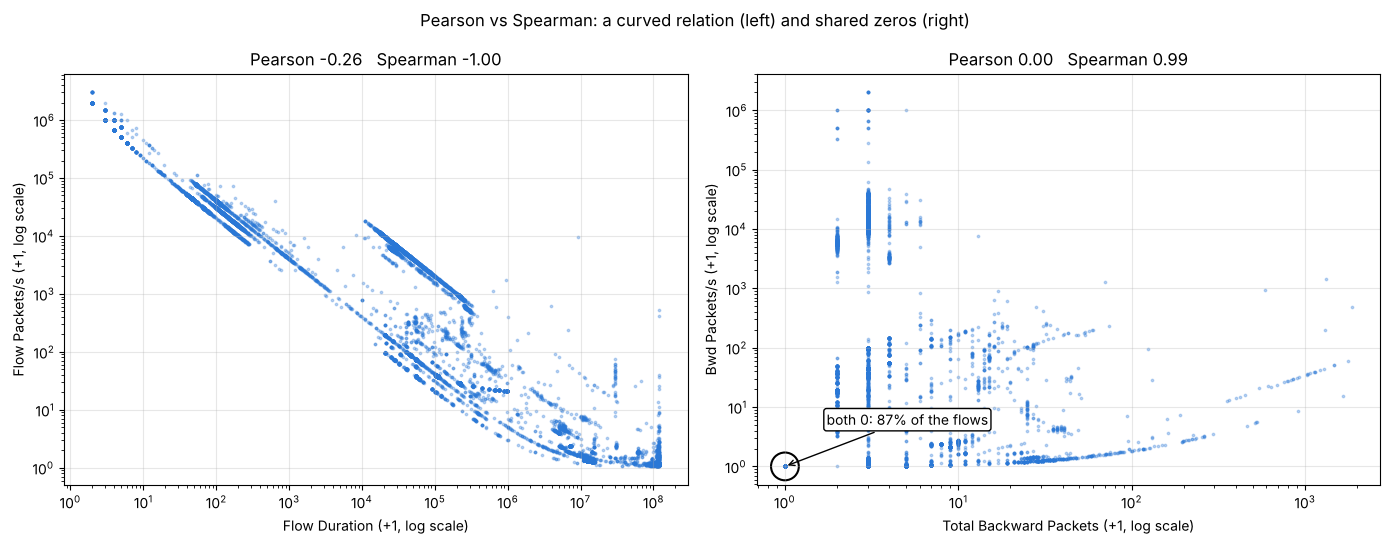

In [62]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, (a, b) in zip(axes, [("Flow Duration", "Flow Packets/s"), ("Total Backward Packets", "Bwd Packets/s")]):
    ax.scatter(ddos[a] + 1, ddos[b] + 1, s=3, alpha=0.3, color="#2a78d6")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(f"{a} (+1, log scale)")
    ax.set_ylabel(f"{b} (+1, log scale)")
    ax.set_title(f"Pearson {pearson.loc[a, b]:.2f}   Spearman {spearman.loc[a, b]:.2f}")
    ax.grid(alpha=0.3)
    both_zero = ((ddos[a] == 0) & (ddos[b] == 0)).mean()
    if both_zero > 0.5:
        ax.scatter([1], [1], s=400, facecolors="none", edgecolors="black", lw=1.5)
        ax.annotate(f"both 0: {both_zero:.0%} of the flows", (1, 1), xytext=(30, 30),
                    textcoords="offset points", fontsize=10, arrowprops=dict(arrowstyle="->"),
                    bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="black"))
fig.suptitle("Pearson vs Spearman: a curved relation (left) and shared zeros (right)")
show_figure(fig)

- **Left:** the flows lie on bands that fall from top left to bottom right: the longer the flow, the fewer packets per second. The relation is almost perfectly monotone (Spearman −1.00), but on the raw values it is a hyperbola, not a straight line, so Pearson gives only −0.26.
- **Right:** 87% of the flows sit on the single point (0, 0), circled. Spearman gives all of them the same rank, and that alone produces 0.99. The other flows show no clear relation: vertical stripes of flows with 2–3 backward packets at very different rates (Pearson 0.00, and Spearman only 0.304 on the flows where both are non-zero, §9.1).

The first kind of pair is a real redundancy that Pearson misses; the second is an artefact of Spearman.

### 9.3 Decision

**No further column is removed on the basis of Spearman.** Three reasons:

1. **Ten of the 21 pairs are an effect of the zeros**, not a redundancy: removing one of their columns would lose information about the minority of flows where the two features differ.
2. **For the 11 genuine pairs, the redundancy is harmless for the main models.** Decision trees and random forests pick one feature per split and ignore its near-copies. Models based on distances will work on the PCA components (§13), which absorb the redundancy by construction.
3. **The removal criterion stays consistent.** It was fixed in step 4 (Pearson above 0.95 on the raw values, one column per group). Changing it now, with a measure that overstates the relations on these data, would make the list harder to justify.

If a model of Section 2 needs fewer inputs, the natural candidates are those of the first group: one between `Flow Duration` and `Flow IAT Max`, one between `Flow IAT Mean` and `Flow Packets/s`, `Bwd IAT Total` and `Bwd IAT Max`, and `Max Packet Length`. The residual correlation of §17 confirms this list on the final matrix.

## 10. Encoding

A model only receives numbers, and it treats them as quantities: it assumes that 17 is larger than 6 and that the distance between 6 and 17 means something. This is true for durations, sizes and rates, but not for every column. This section decides how each kind of column is presented:

| Kind of column | Columns | Encoding |
|---|---|---|
| categories | `Protocol`, `Destination Port` | one-hot (§10.1–§10.2) |
| numbers with a special value | `Init_Win_bytes_forward/backward` (−1 = not available) | indicator + value (§10.3) |
| yes/no columns | flags, `SimillarHTTP`, `Inbound` | kept as 0/1 (§10.4) |
| the target | `label` | integers 0–11 (§10.5) |
| everything else | durations, sizes, counts, rates | log + scaling (§11) |

### 10.1 `Protocol`: one-hot

`Protocol` holds the IANA number of the transport protocol: 6 = TCP, 17 = UDP, and 0 for the few flows without a transport protocol. These numbers are names, not quantities: UDP is not "almost three times TCP". **One-hot encoding** replaces the column with one 0/1 column per value (`Protocol_0`, `Protocol_6`, `Protocol_17`), so that each protocol is a separate yes/no feature and no order is implied.

In [63]:
display(ddos["Protocol"].map({6: "6 (TCP)", 17: "17 (UDP)", 0: "0 (other)"})
        .value_counts().rename_axis("Protocol").to_frame("flows"))

,flows
Protocol,
17 (UDP),48453
6 (TCP),14757
0 (other),58


After the cleaning, 48,453 UDP flows, 14,757 TCP flows and 58 flows with protocol 0: three one-hot columns.

### 10.2 `Destination Port`: three ranges, then one-hot

A port is also a name: port 900 is not "close" to port 901. One-hot encoding the raw values is not an option either: with thousands of distinct ports it would create thousands of columns, and a model would memorise the ports of this experiment, the same shortcut that led to removing `Source Port` (§7.5).

The middle way is to replace the port with its IANA range (well-known, registered, dynamic, §5.2) and one-hot encode the range: three columns. §5.2 showed that this keeps the useful signal and drops the rest: most benign flows go to a well-known service port, while the destination ports of the attacks follow the shares expected from random ports, except for `ddos_ntp`. The function `port_range()` of §5.2 does the conversion.

### 10.3 `Init_Win_bytes_*`: an indicator for −1

In the two `Init_Win_bytes` columns, −1 does not mean "one byte less than 0": it means "no TCP window", either because the flow is not TCP or because the other side never answered (§6.6). Left as it is, the value would be a problem twice: models based on distances would treat it as a small number, and the logarithm of §11 is not defined for it (log(1 + (−1)) = log 0 = −∞).

The fix splits each column in two:

- a new 0/1 column, `..._missing`, which is 1 where the value was −1;
- the original column, where −1 becomes 0, so that it holds only real window sizes.

No information is lost, and each column now means one thing. The function `prepare_features()` does this together with the port ranges of §10.2. It learns nothing from the data, so it can be applied to any set of flows.

In [64]:
def prepare_features(X):
    """Stateless preparation: Destination Port -> IANA range, Init_Win -1 -> indicator + 0."""
    X = X.copy()
    if "Destination Port" in X.columns:
        X["Destination Port"] = port_range(X["Destination Port"].to_numpy())
    for col in MINUS_ONE_ALLOWED:
        if col in X.columns:
            X[f"{col}_missing"] = (X[col] == -1).astype(int)
            X[col] = X[col].clip(lower=0)
    return X


X = ddos[FEATURES]
X_prepared = prepare_features(X)
display(X_prepared["Destination Port"].value_counts().rename_axis("Destination Port range").to_frame("flows"))
indicators = [f"{c}_missing" for c in MINUS_ONE_ALLOWED]
display(pd.DataFrame({c: X_prepared[c].value_counts() for c in indicators}).rename_axis("value"))
display(pd.crosstab(ddos["Protocol"].map({6: "TCP", 17: "UDP", 0: "other"}).rename("protocol"),
                    X_prepared["Init_Win_bytes_forward_missing"]))
print("Minimum of the two window columns after the change:",
      {c: int(X_prepared[c].min()) for c in MINUS_ONE_ALLOWED})

,flows
Destination Port range,
registered,41708
dynamic,15760
well_known,5800


,Init_Win_bytes_forward_missing,Init_Win_bytes_backward_missing
value,,
1,48511,57103
0,14757,6165


Init_Win_bytes_forward_missing,0,1
protocol,,
TCP,14757,0
UDP,0,48453
other,0,58


Minimum of the two window columns after the change: {'Init_Win_bytes_forward': 0, 'Init_Win_bytes_backward': 0}


- **`Destination Port`** is now one of three words: 41,708 flows go to a registered port, 15,760 to a dynamic one and 5,800 to a well-known one;
- **forward window:** `Init_Win_bytes_forward_missing` is 1 for 48,511 flows, exactly the 48,453 UDP flows plus the 58 without a transport protocol, and 0 for every TCP flow;
- **backward window:** `Init_Win_bytes_backward_missing` is 1 for 57,103 flows: the same ones, plus the TCP flows whose destination never answered (§6.6);
- **window columns:** after the change both start at 0 and hold only real window sizes, so the logarithm of §11 is defined everywhere.

The forward indicator coincides with "not TCP" (§17 confirms it). It is kept anyway: on other data a TCP flow could lack a forward window, and the indicator would then carry its own information.

### 10.4 The yes/no columns

Some features already take only the values 0 and 1: the TCP flags that are left, `SimillarHTTP` (§6.7), `Inbound` (§7.5) and the two indicators of §10.3. For them 0/1 is already the right encoding, so they are passed to the model unchanged. The cell finds them automatically and splits the features into the three groups used by the pipeline of §12.

In [65]:
CATEGORICAL = [c for c in ["Protocol", "Destination Port"] if c in X_prepared.columns]
BINARY = [c for c in X_prepared.columns
          if c not in CATEGORICAL and set(X_prepared[c].unique()) <= {0, 1}]
CONTINUOUS = [c for c in X_prepared.columns if c not in CATEGORICAL + BINARY]
print(f"Categorical -> one-hot   ({len(CATEGORICAL)}): {CATEGORICAL}")
print(f"Binary -> unchanged      ({len(BINARY)}): {BINARY}")
print(f"Continuous -> log+scale ({len(CONTINUOUS)}): {CONTINUOUS}")

Categorical -> one-hot   (2): ['Protocol', 'Destination Port']
Binary -> unchanged      (8): ['Fwd PSH Flags', 'ACK Flag Count', 'URG Flag Count', 'CWE Flag Count', 'SimillarHTTP', 'Inbound', 'Init_Win_bytes_forward_missing', 'Init_Win_bytes_backward_missing']
Continuous -> log+scale (31): ['Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Max', 'Bwd IAT Min', 'Bwd Packets/s', 'Max Packet Length', 'Down/Up Ratio', 'Init_Win_bytes_forward', 'Init_Win_bytes_backward', 'Active Mean', 'Active Std', 'Active Max', 'Active Min', 'Idle Mean', 'Idle Std']


The 39 features become three groups: 2 categorical columns, 8 binary columns (6 yes/no features plus the 2 indicators of §10.3) and 31 continuous columns, which receive the log transform and the scaling of §11.

### 10.5 The label

The classifiers of scikit-learn want the classes as integers. `LabelEncoder` assigns 0, 1, 2, ... in alphabetical order and remembers the mapping, so that predictions can be translated back to names. One-hot encoding is not needed for the target.

In [66]:
label_encoder = LabelEncoder().fit(ddos["label"])
y = label_encoder.transform(ddos["label"])
display(pd.DataFrame({"code": range(len(label_encoder.classes_)), "flows": np.bincount(y)},
                     index=pd.Index(label_encoder.classes_, name="class")).T)

class,benign,ddos_dns,ddos_ldap,ddos_mssql,ddos_netbios,ddos_ntp,ddos_snmp,ddos_ssdp,ddos_syn,ddos_tftp,ddos_udp,ddos_udp_lag
code,0,1,2,3,4,5,6,7,8,9,10,11
flows,5478,5367,5836,5796,5829,941,5874,5896,5329,5068,5876,5978


## 11. Log transform and scaling

### 11.1 Why a logarithm first

Most continuous features span many orders of magnitude: a flow can last 1 µs or 120 s, and `Flow Bytes/s` goes from 0 to more than 10⁹. Such distributions are **heavy-tailed**: most values are small, a few are enormous. Two consequences:

- any scaling based on mean and standard deviation is dominated by the few enormous values, and squeezes all the others into a tiny interval near zero;
- models based on distances (KNN, SVM, k-means) and PCA see only the extreme flows.

The logarithm fixes this by turning *ratios* into *differences*: 10, 100 and 1,000 become equally spaced. `log1p(x) = log(1 + x)` is used instead of `log(x)` because many features are 0, and log1p(0) = 0. All the continuous features are non-negative after §8 and §10.3, so log1p is defined everywhere.

The table measures the effect with the **skewness**, a number that is 0 for a symmetric distribution and grows with the length of the right tail.

In [67]:
skew = pd.DataFrame({
    "median": X_prepared[CONTINUOUS].median(),
    "max": X_prepared[CONTINUOUS].max(),
    "skewness (raw)": X_prepared[CONTINUOUS].skew(),
    "skewness (after log1p)": np.log1p(X_prepared[CONTINUOUS]).skew(),
}).sort_values("skewness (raw)", ascending=False)
display(skew.round(2))
print(f"Median skewness: {skew['skewness (raw)'].median():.1f} raw, "
      f"{skew['skewness (after log1p)'].median():.1f} after log1p")

,median,max,skewness (raw),skewness (after log1p)
Total Fwd Packets,2.0,8.589400e+04,153.36,2.71
Active Std,0.0,2.853681e+07,135.63,8.10
Flow IAT Min,1.0,3.686411e+07,115.28,5.31
Active Max,0.0,6.783473e+07,99.36,6.81
Bwd Packets/s,0.0,2.000000e+06,53.47,3.82
Total Backward Packets,0.0,1.862000e+03,46.42,4.30
Active Mean,0.0,1.678654e+07,40.91,7.41
Bwd Packet Length Max,0.0,3.796000e+04,38.53,4.43
Active Min,0.0,8.349846e+06,34.94,9.26
Bwd IAT Min,0.0,2.580000e+02,30.12,4.40


Median skewness: 13.2 raw, 4.2 after log1p


**The logarithm reduces the skewness a lot.** The median skewness of the continuous features drops from 13.2 to 4.2. The extreme cases improve the most: `Total Fwd Packets` goes from 153.36 to 2.7, `Flow IAT Min` from 115.3 to 5.3.

**What remains skewed is the columns that are almost always 0**, such as `Active Min` (9.3) or `Active Mean` (7.4). The logarithm compresses large values, but it cannot spread out a spike of identical zeros: with 90% of the flows at 0, the remaining 10% always looks like a long tail. These columns are not a problem: most of their information is "zero or not", which the models read easily.

A few columns become slightly skewed to the left (`Max Packet Length` −1.18, `Fwd Packet Length Max` −1.14): their values are concentrated near the maximum, such as the 1,472-byte packets of the reflections. Skewness is only a summary: the histograms of §11.2 and §16 show the actual shapes.

### 11.2 An example: `Flow Bytes/s`

The same column at three stages: raw, after log1p, and after log1p and standardisation. The y axis counts the flows in each bar.

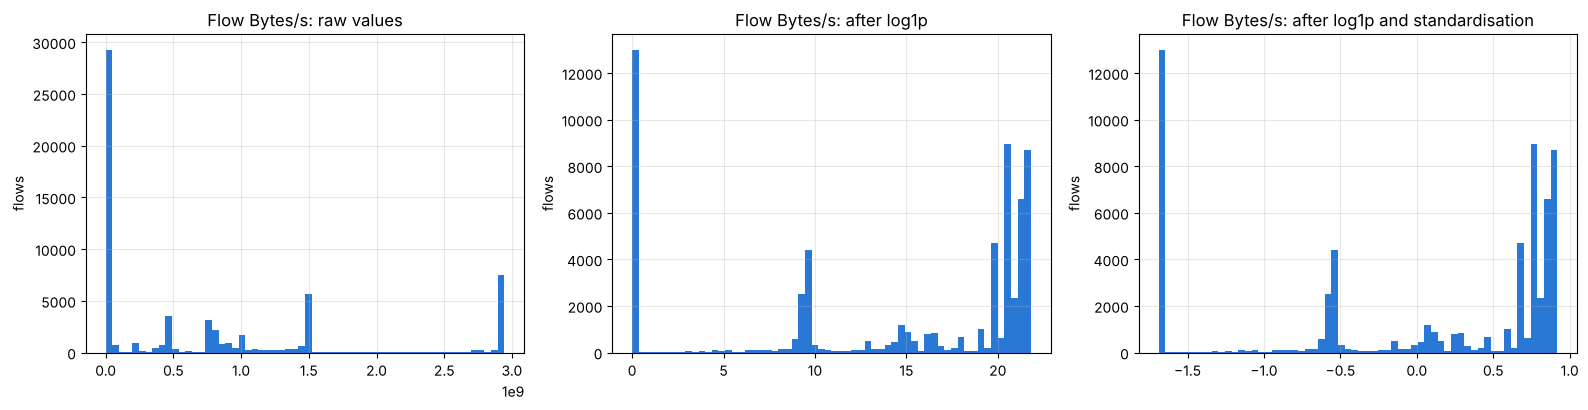

Raw: 46.3% of the flows fall in the first of the 60 bars
Flows with Flow Bytes/s = 0: 12,982 - {'ddos_syn': 5328, 'ddos_tftp': 5066, 'benign': 1799, 'ddos_ntp': 680}


In [68]:
example = X_prepared["Flow Bytes/s"]
logged = np.log1p(example)
standardised = (logged - logged.mean()) / logged.std()
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, values, title in [(axes[0], example, "raw values"),
                          (axes[1], logged, "after log1p"),
                          (axes[2], standardised, "after log1p and standardisation")]:
    ax.hist(values, bins=60, color="#2a78d6")
    ax.set_title(f"Flow Bytes/s: {title}")
    ax.set_ylabel("flows")
    ax.grid(alpha=0.3)
show_figure(fig)
print(f"Raw: {(example < example.max() / 60).mean():.1%} of the flows fall in the first of the 60 bars")
no_payload = ddos.loc[example == 0, "label"].value_counts()
print(f"Flows with Flow Bytes/s = 0: {int(no_payload.sum()):,} -", no_payload.head(4).to_dict())

- **Raw values (left):** the axis goes up to 3·10⁹, and 46.3% of the flows fall into the first bar. Almost everything that distinguishes benign traffic is hidden inside it.
- **After log1p (centre):** three groups become visible:
  - a spike at 0: the 12,982 flows that carry no payload, mostly `ddos_syn` and `ddos_tftp`, plus 1,799 benign and 680 `ddos_ntp` flows (printed below the figure);
  - a group around 10, i.e. about 2·10⁴ B/s, the rate of normal traffic;
  - a dense group between 20 and 22, i.e. 5·10⁸–3·10⁹ B/s, the volumetric attacks.
- **After standardisation (right):** the shape is identical. Standardising only shifts and stretches the axis, which now goes from about −1.7 to 0.9 with mean 0.

It is the logarithm that makes the information visible; the scaling only puts it on a common unit.

### 11.3 Which scaler

After the logarithm the features still have different ranges (the cell below prints a few), so they are brought to a common scale. Two scalers are common:

- **StandardScaler** subtracts the mean and divides by the standard deviation: every column ends up with mean 0 and standard deviation 1;
- **RobustScaler** subtracts the median and divides by the IQR (§5.4): it ignores the extreme values, which is useful when the data have outliers.

After the logarithm the outliers are no longer a problem, and RobustScaler has a weakness on these data: a column whose IQR is 0 cannot be divided by it, so scikit-learn leaves it unscaled. The cell counts how many continuous columns are in that situation.

In [69]:
logged_all = np.log1p(X_prepared[CONTINUOUS])
log_iqr = logged_all.quantile(0.75) - logged_all.quantile(0.25)
zero_iqr = log_iqr.index[log_iqr == 0].tolist()
print(f"Continuous columns with IQR = 0 after log1p: {len(zero_iqr)} of {len(CONTINUOUS)}")
print(zero_iqr)
print("Largest value after log1p:", {c: round(float(logged_all[c].max()), 1)
                                     for c in ["Flow Duration", "Flow Bytes/s", "Total Fwd Packets", "Down/Up Ratio"]})

Continuous columns with IQR = 0 after log1p: 21 of 31
['Total Fwd Packets', 'Total Backward Packets', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Max', 'Bwd IAT Min', 'Bwd Packets/s', 'Down/Up Ratio', 'Init_Win_bytes_forward', 'Init_Win_bytes_backward', 'Active Mean', 'Active Std', 'Active Max', 'Active Min', 'Idle Mean', 'Idle Std']
Largest value after log1p: {'Flow Duration': 18.6, 'Flow Bytes/s': 21.8, 'Total Fwd Packets': 11.4, 'Down/Up Ratio': 3.2}


**21 of the 31 continuous columns have IQR 0 after the logarithm.** Their central half is a single value, almost always 0: the backward statistics in flows without replies, the activity and idle times in flows without pauses, the number of packets in flows of exactly two packets. RobustScaler would leave these 21 columns in log units and scale the other 10, so the columns would end up on different scales again.

**StandardScaler has no such problem**, because the standard deviation of these columns is not 0, and after the logarithm there are no extreme values left to distort the mean and the standard deviation. It is therefore the scaler used. The ranges it equalises are those printed above: after log1p, `Flow Duration` reaches 18.6 and `Flow Bytes/s` 21.8, `Total Fwd Packets` 11.4, `Down/Up Ratio` only 3.2.

**Which models need scaling.** Scaling matters for every method that compares features through distances or weights: KNN, SVM, logistic regression, k-means, PCA. **Decision trees and random forests do not need it**: they split one feature at a time on a threshold ("duration < 52 µs"), and any monotone transformation (logarithm, scaling) only moves the threshold, without changing which flows end up on each side. The pipeline of §12 applies log and scaling anyway, so that one feature matrix serves every model; for the trees it is harmless.

## 12. The pre-processing pipeline

### 12.1 Building it

The steps of §10 and §11 are collected in a single scikit-learn object:

1. `prepare_features()` (§10.2–§10.3), wrapped in a `FunctionTransformer`;
2. a `ColumnTransformer`, which applies a different treatment to each group of §10.4:
   - continuous: log1p, then `StandardScaler`;
   - categorical: `OneHotEncoder` (with `handle_unknown="ignore"`, so that a value never seen during fitting gets all zeros instead of an error);
   - binary: `passthrough`, unchanged.

Putting everything in one object matters because of **data leakage**. `StandardScaler` *learns* a mean and a standard deviation, and `OneHotEncoder` learns the list of categories. If they learned them on the whole dataset, information from the test flows would leak into the training, and the test score would be optimistic. In Section 2 the pipeline must therefore be **fitted on the training set only** and then applied, unchanged, to the test set. The safest way is to put it in front of the model:

```python
model = Pipeline([("pre", preprocessor), ("clf", RandomForestClassifier())])
model.fit(X_train, y_train)          # the scaler learns from the training flows only
model.score(X_test, y_test)
```

This also works inside cross-validation, where the pipeline is refitted on each training fold. The diagram below is scikit-learn's own representation of the object; its boxes can be clicked to see the details.

In [70]:
preprocessor = Pipeline([
    ("prepare", FunctionTransformer(prepare_features)),
    ("columns", ColumnTransformer([
        ("continuous", Pipeline([
            ("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
            ("scale", StandardScaler()),
        ]), CONTINUOUS),
        ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL),
        ("binary", "passthrough", BINARY),
    ], verbose_feature_names_out=False)),
])
display(preprocessor)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prepare', ...), ('columns', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function pre...x7f959cbb13a0>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False
,"check_inverse check_inverse: bool, default=TrueWhether to check that or ``func`` followed by ``inverse_func`` leads tothe original inputs. It can be used for a sanity check, raising awarning when the condition is not fulfilled... versionadded:: 0.20",True
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_feature_names_out` method is only defined if`feature_names_out` is not None.See ``get_feature_names_out`` for more details... versionadded:: 1.1",None
,"kw_args kw_args: dict, default=NoneDictionary of 

### 12.2 Applying it

In this section the pipeline is fitted on **all** the flows: the goal here is to look at the data (the PCA of §13 and the description of §14–§17), not to evaluate a model, so there is no test set to protect. Section 2 must refit it on its own training set, as explained above.

To show what the models receive, the cell prints a typical flow of three different classes on a few columns of each kind, before (cleaned values) and after the pipeline.

In [71]:
X_matrix = preprocessor.fit_transform(X)
COLUMNS_OUT = list(preprocessor[-1].get_feature_names_out())
matrix = pd.DataFrame(X_matrix, columns=COLUMNS_OUT)
print(f"Feature matrix: {X_matrix.shape[0]:,} rows x {X_matrix.shape[1]} columns")
print(f"  continuous (log1p + standard scaling): {len(CONTINUOUS)}")
print(f"  one-hot: {sum(c.startswith(tuple(CATEGORICAL)) for c in COLUMNS_OUT)} "
      f"{[c for c in COLUMNS_OUT if c.startswith(tuple(CATEGORICAL))]}")
print(f"  binary (unchanged): {len(BINARY)}")

# a typical flow of three classes: the one with the duration closest to the median of its class (as in §3.1)
examples = [(ddos.loc[ddos["label"] == lab, "Flow Duration"]
             - ddos.loc[ddos["label"] == lab, "Flow Duration"].median()).abs().idxmin()
            for lab in ["benign", "ddos_ldap", "ddos_syn"]]
SHOW_IN = ["Flow Duration", "Total Backward Packets", "Fwd Packet Length Max", "Flow Bytes/s",
           "Init_Win_bytes_forward", "Protocol", "Destination Port", "Inbound"]
SHOW_OUT = ["Flow Duration", "Total Backward Packets", "Fwd Packet Length Max", "Flow Bytes/s",
            "Init_Win_bytes_forward", "Init_Win_bytes_forward_missing", "Protocol_6", "Protocol_17",
            "Destination Port_well_known", "Destination Port_registered", "Destination Port_dynamic", "Inbound"]
names = ddos.loc[examples, "label"].tolist()
display(ddos.loc[examples, SHOW_IN].astype(object).set_axis(names).T.rename_axis("cleaned values"))
display(matrix.loc[examples, SHOW_OUT].set_axis(names).T.round(3).rename_axis("after the pipeline"))

Feature matrix: 63,268 rows x 45 columns
  continuous (log1p + standard scaling): 31
  one-hot: 6 ['Protocol_0', 'Protocol_6', 'Protocol_17', 'Destination Port_dynamic', 'Destination Port_registered', 'Destination Port_well_known']
  binary (unchanged): 8


,benign,ddos_ldap,ddos_syn
cleaned values,,,
Flow Duration,20838,1,57
Total Backward Packets,2,0,2
Fwd Packet Length Max,42.0,1472.0,0.0
Flow Bytes/s,9597.850082,2944000000.0,0.0
Init_Win_bytes_forward,-1,-1,5840
Protocol,17,17,6
Destination Port,53,1808,13937
Inbound,0,1,1


,benign,ddos_ldap,ddos_syn
after the pipeline,,,
Flow Duration,0.955,-0.712,-0.105
Total Backward Packets,1.595,-0.330,1.595
Fwd Packet Length Max,-0.465,0.847,-1.861
Flow Bytes/s,-0.593,0.919,-1.690
Init_Win_bytes_forward,-0.541,-0.541,1.860
Init_Win_bytes_forward_missing,1.000,1.000,0.000
Protocol_6,0.000,0.000,1.000
Protocol_17,1.000,1.000,0.000
Destination Port_well_known,1.000,0.000,0.000


The feature matrix has 63,268 rows and 45 columns: 31 continuous columns after log1p and scaling, 6 one-hot columns (3 protocols, 3 port ranges) and 8 binary columns unchanged. The two tables show the same three flows before and after the pipeline:

- **continuous values** become a few units around 0: the 1-µs `ddos_ldap` flow has `Flow Duration` −0.712, below the average, the 21-ms benign flow 0.955, above it;
- **a raw 0 is no longer 0**: "no backward packets" becomes −0.330 for the `ddos_ldap` flow, and the empty packets of `ddos_syn` become −1.861 in `Fwd Packet Length Max`, the lowest value of the column;
- **the −1 window** of the two UDP flows becomes 0 and then −0.541, with `Init_Win_bytes_forward_missing` = 1; the 5,840-byte window of `ddos_syn` becomes 1.860;
- **categories become yes/no columns**: the benign flow is a DNS query, UDP (`Protocol_17` = 1) towards a well-known port (53); the other two go to registered ports.

## 13. PCA

### 13.1 What PCA does

The feature matrix has many columns, and §9 showed that several of them carry nearly the same information. **Principal Component Analysis** looks for new axes, the *principal components*, that summarise the data with fewer numbers:

- the first component (PC1) is the direction along which the flows differ the most;
- the second (PC2) is the direction of largest spread among those perpendicular to PC1, and so on;
- each component is a weighted sum of the original features; the weights are called **loadings** and say what the component "means".

The **explained variance** of a component is the share of the total spread of the data that it captures. PCA must come **after** scaling: otherwise the column with the largest numbers (for example a rate in bytes per second) would dominate PC1 only because of its unit of measure.

### 13.2 How many components

The bars give the variance explained by each component, the line the cumulative total; the dashed lines mark 90% and 95%.

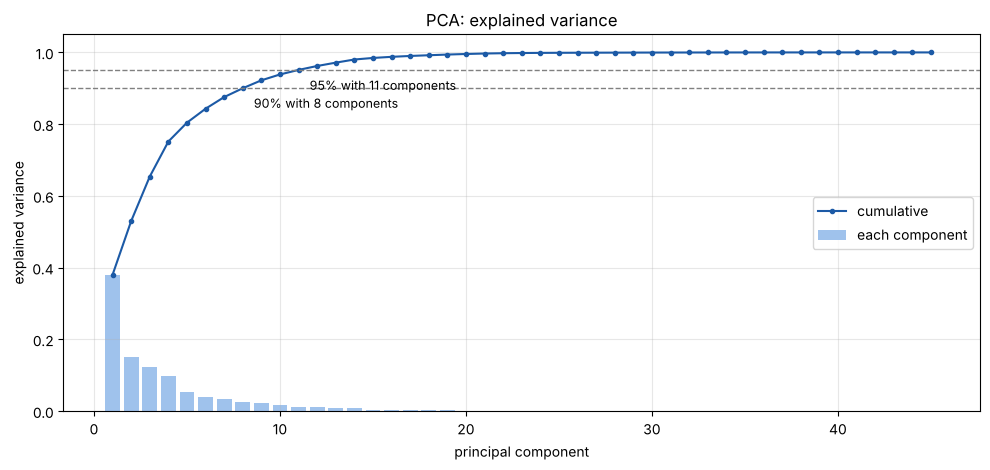

Components for 90% of the variance: 8 of 45; for 95%: 11
First five components: PC1 38.0%, PC2 15.0%, PC3 12.4%, PC4 9.8%, PC5 5.3%


In [72]:
pca = PCA().fit(X_matrix)
ratio = pca.explained_variance_ratio_
cumulative = np.cumsum(ratio)
n90 = int(np.searchsorted(cumulative, 0.90) + 1)
n95 = int(np.searchsorted(cumulative, 0.95) + 1)

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.bar(range(1, len(ratio) + 1), ratio, color="#9fc2ec", label="each component")
ax.plot(range(1, len(ratio) + 1), cumulative, marker="o", ms=3, color="#1c5aa6", label="cumulative")
for level, n in [(0.90, n90), (0.95, n95)]:
    ax.axhline(level, ls="--", color="grey", lw=1)
    ax.annotate(f"{level:.0%} with {n} components", (n, level), xytext=(8, -14),
                textcoords="offset points", fontsize=9)
ax.set_xlabel("principal component")
ax.set_ylabel("explained variance")
ax.set_title("PCA: explained variance")
ax.legend(loc="center right")
ax.grid(alpha=0.3)
show_figure(fig)
print(f"Components for 90% of the variance: {n90} of {X_matrix.shape[1]}; for 95%: {n95}")
print("First five components:", ", ".join(f"PC{i + 1} {r:.1%}" for i, r in enumerate(ratio[:5])))

**PCA compresses the 45 columns well:** 8 components keep 90% of the variance and 11 keep 95%. The first component alone explains 38.0%, the second 15.0%, then 12.4%, 9.8% and 5.3%; after the fifth, each component adds little.

This confirms what §9 found: many columns are partly redundant, and the information of the 45 columns lives in about ten directions. The two-dimensional picture of §13.3 shows 53% of the variance, so it is a faithful but incomplete view.

### 13.3 The flows on the first two components

Each dot is a flow, placed by its values of PC1 and PC2 and coloured by class; the class names are written at the median position of each class, so that the classes can be identified without relying on colour alone. Classes that form separate groups are easy to tell apart even with two numbers; classes that fall on top of each other will need more information, or will be confused. The right panel zooms on the dense region at the left of the first one, where most UDP reflection attacks lie.

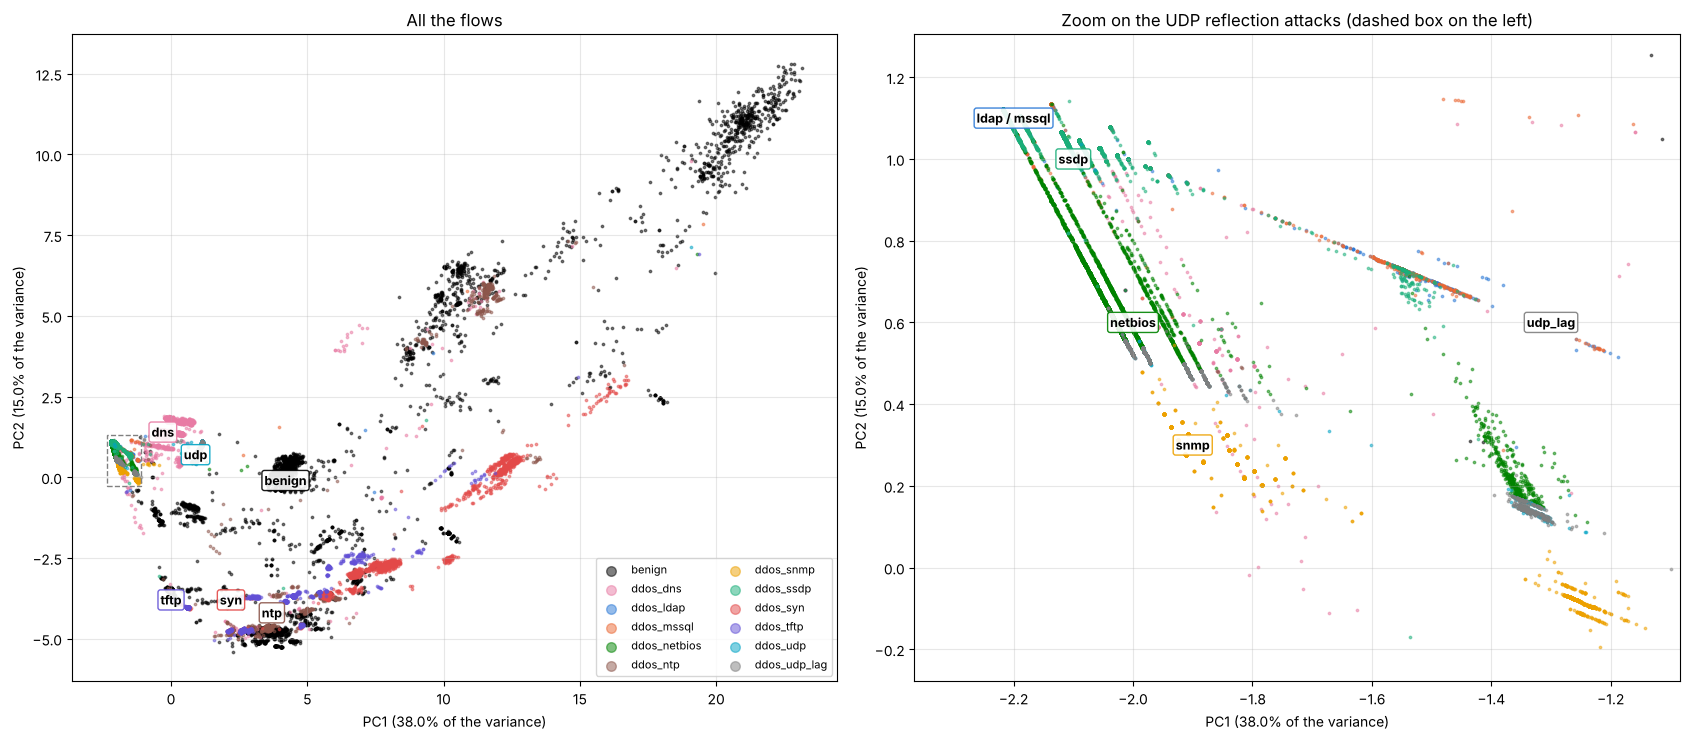

median position of each class,benign,ddos_dns,ddos_ldap,ddos_mssql,ddos_netbios,ddos_ntp,ddos_snmp,ddos_ssdp,ddos_syn,ddos_tftp,ddos_udp,ddos_udp_lag
PC1,4.19,-0.27,-2.19,-2.19,-2.03,3.72,-1.91,-2.11,2.21,0.03,0.92,-1.31
PC2,-0.07,1.39,1.10,1.10,0.62,-4.20,0.29,1.05,-3.77,-3.77,0.66,0.56


In [73]:
pcs = pca.transform(X_matrix)[:, :2]
labels = ddos["label"].to_numpy()
centres = pd.DataFrame(pcs, columns=["PC1", "PC2"]).groupby(labels).median().reindex(LABELS)
reflection = ["ddos_ldap", "ddos_mssql", "ddos_netbios", "ddos_snmp", "ddos_ssdp"]
zone = np.isin(labels, reflection)
x_lo, x_hi = np.percentile(pcs[zone, 0], [0.5, 99.5])
y_lo, y_hi = np.percentile(pcs[zone, 1], [0.5, 99.5])
pad_x, pad_y = 0.15 * (x_hi - x_lo), 0.15 * (y_hi - y_lo)
box = (x_lo - pad_x, x_hi + pad_x, y_lo - pad_y, y_hi + pad_y)



def label_centres(ax, centres):
    """Write the class names at their median position; classes at the same place share one label."""
    for (cx, cy), group in centres.groupby([centres["PC1"].round(1), centres["PC2"].round(1)]):
        ax.annotate(" / ".join(lab.removeprefix("ddos_") for lab in group.index), (cx, cy),
                    fontsize=9, fontweight="bold", ha="center", va="center",
                    bbox=dict(boxstyle="round,pad=0.2", fc="white", ec=CLASS_COLORS[group.index[0]], alpha=0.9))


inside = centres["PC1"].between(box[0], box[1]) & centres["PC2"].between(box[2], box[3])
fig, axes = plt.subplots(1, 2, figsize=(17, 7.5))
for ax in axes:
    for lab in LABELS:
        m = labels == lab
        ax.scatter(pcs[m, 0], pcs[m, 1], s=3, alpha=0.5, color=CLASS_COLORS[lab], label=lab)
    ax.set_xlabel(f"PC1 ({ratio[0]:.1%} of the variance)")
    ax.set_ylabel(f"PC2 ({ratio[1]:.1%} of the variance)")
    ax.grid(alpha=0.3)
label_centres(axes[0], centres[~inside])          # the classes inside the box are named in the zoom
label_centres(axes[1], centres[inside])
axes[0].set_title("All the flows")
axes[0].legend(markerscale=4, fontsize=8, ncol=2, loc="lower right")
axes[0].add_patch(plt.Rectangle((box[0], box[2]), box[1] - box[0], box[3] - box[2], fill=False, ls="--", color="grey"))
axes[1].set_xlim(box[0], box[1])
axes[1].set_ylim(box[2], box[3])
axes[1].set_title("Zoom on the UDP reflection attacks (dashed box on the left)")
show_figure(fig)
display(centres.round(2).rename_axis("median position of each class").T)

**Benign traffic against the attacks.** The benign flows (black) spread over a large region on the right and at the top, up to PC1 ≈ 22 and PC2 ≈ 12, around the median position (4.19, −0.07). The UDP reflection attacks are packed in the opposite corner, around PC1 ≈ −2.

**The attacks that separate well:**

- `ddos_syn` lies along a band at negative PC2 (median −3.77), stretching to large PC1;
- `ddos_dns` forms its own strips above the reflection cluster (median PC2 1.39);
- `ddos_udp` stands to the right of the cluster (median PC1 0.92).

**The overlaps of §5.8:**

- `ddos_tftp` shares the bottom band with `ddos_syn` (same median PC2, −3.77): the two differ only along PC1;
- `ddos_ntp` (median 3.72, −4.20) falls in the bottom region, among benign groups and TCP flows;
- in the zoom, `ddos_ldap` and `ddos_mssql` have the **same median position** (−2.19, 1.10), so they share one label, and they lie on the same lines; `ddos_ssdp` (−2.11, 1.05) runs on parallel lines just beside them;
- `ddos_netbios` and `ddos_udp_lag` lie on intertwined lines; `ddos_snmp` forms separate segments lower down.

Two components already separate benign traffic and several attacks, but not the reflections with 1,472-byte packets: for those, even the 45 columns are not enough for some flows (§8.3).

### 13.4 What the components mean: loadings

The loading of a feature on a component is its weight in the weighted sum: a large positive loading means that the component grows with that feature, a large negative one that it decreases. The bars show the 12 features with the largest weight (in absolute value) on PC1 and PC2: blue positive, orange negative.

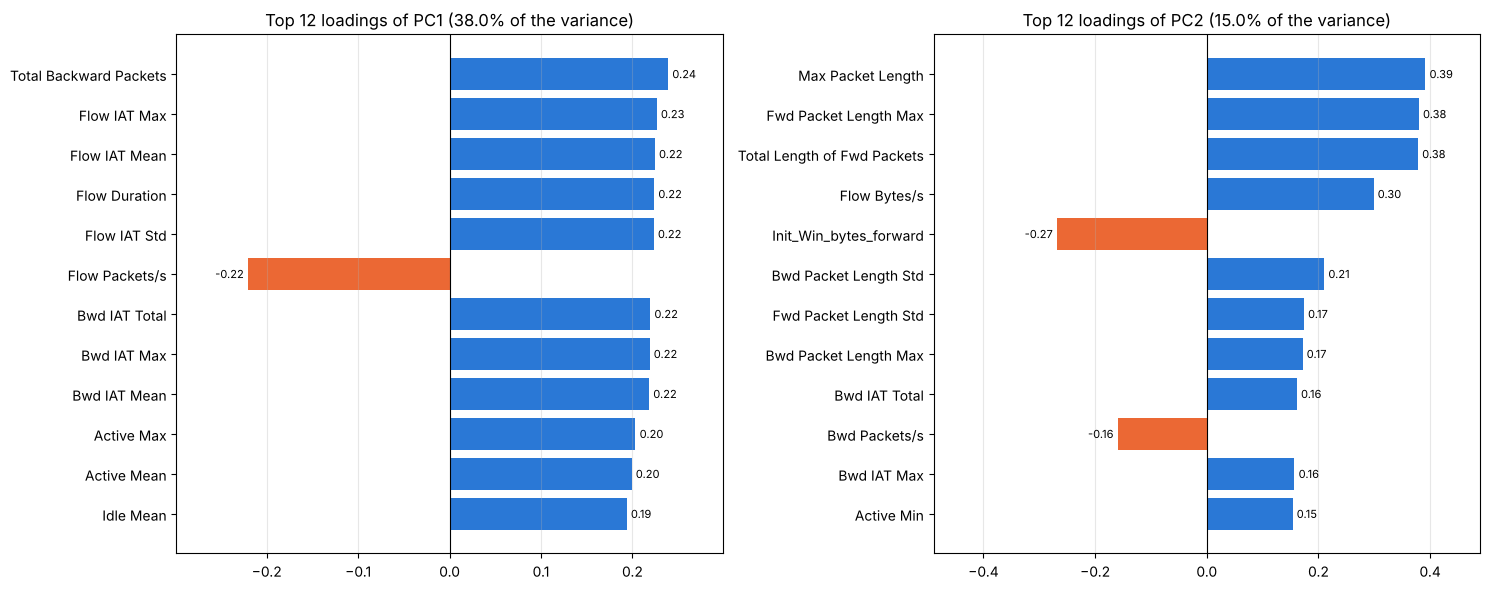

In [74]:
loadings = pd.DataFrame(pca.components_[:2].T, index=COLUMNS_OUT, columns=["PC1", "PC2"])
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, comp in zip(axes, ["PC1", "PC2"]):
    top = loadings[comp].abs().sort_values().tail(12).index
    bars = ax.barh(top, loadings.loc[top, comp],
                   color=["#2a78d6" if v > 0 else ATTACK_COLOR for v in loadings.loc[top, comp]])
    ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=8)
    ax.axvline(0, color="black", lw=0.8)
    lim = loadings[comp].abs().max() * 1.25
    ax.set_xlim(-lim, lim)
    ax.set_title(f"Top 12 loadings of {comp} ({ratio[int(comp[-1]) - 1]:.1%} of the variance)")
    ax.grid(axis="x", alpha=0.3)
show_figure(fig)

**PC1: "a long conversation or a burst?"** All its largest weights are positive and belong to the duration and timing of the flow: `Total Backward Packets` (0.24), `Flow IAT Max` (0.23), `Flow IAT Mean`, `Flow Duration` and `Flow IAT Std` (0.22), then the backward, activity and idle times. The only large negative weight is `Flow Packets/s` (−0.22). A flow with a high PC1 lasts long, has answers and pauses, and sends packets slowly; a flow with a low PC1 is a burst of a few packets in a few microseconds. This is why benign traffic is on the right and the UDP reflections on the left.

**PC2: "a big payload or an empty TCP flow?"** It grows with the size of the packets and the amount of data: `Max Packet Length` (0.39), `Fwd Packet Length Max` and `Total Length of Fwd Packets` (0.38), `Flow Bytes/s` (0.30). It decreases with `Init_Win_bytes_forward` (−0.27), which is non-zero only for TCP. Flows with large packets are at the top; TCP flows without payload, such as `ddos_syn`, `ddos_tftp` and part of `ddos_ntp`, are at the bottom.

The first two components therefore have a clear meaning, and they correspond to the two most separating aspects found in §5: timing and packet size.

### 13.5 When to use PCA

The assignment asks to decide where PCA is worth using. The answer depends on the model:

- **Classification with trees and random forests: no PCA.** Trees handle redundant features without problems, and they do not need a compact input. Above all, they work on the original features, so it remains possible to explain their decisions and to study the misclassified flows in terms of duration, packet size or rate (point 2.3). A component such as "0.24 × backward packets + 0.23 × max IAT + …" cannot be read in the same way.
- **Clustering and anomaly detection: PCA helps.** k-means and the methods based on distances suffer when many dimensions are redundant: the same information counted many times dominates the distance. With 8–11 components holding 90–95% of the variance, the distances become more meaningful and the computation cheaper.
- **Visualisation: always useful**, as §13.3 shows.

Like the scaler, PCA learns from the data (the directions of the components), so in Section 2 it must be fitted on the training set only, as a step of the pipeline after the scaling: `Pipeline([("pre", preprocessor), ("pca", PCA(n_components=0.90)), ("model", ...)])`.

# Section 1.3 – The final feature matrix

Point 1.3 asks to describe the matrix that the models of the following sections will receive: its size and the features it keeps (§14), which features carry the most information about the class (§15), how they are distributed after the log transform and the scaling (§16), and how much correlation remains among them (§17). The matrix is the one built by the pipeline in §12.2.

## 14. Size and composition

### 14.1 From the raw file to the feature matrix

In [75]:
stages_table = pd.DataFrame([
    ("raw file (§3)", f"{len(raw):,}", raw.shape[1], "identifiers, measurements and label"),
    ("cleaned dataset, data/ddos_pulito.csv (§8)", f"{len(ddos):,}", ddos.shape[1],
     f"{len(SERVICE_COLUMNS)} service columns + {len(FEATURES)} features + label"),
    ("features given to the pipeline (§12)", f"{len(X):,}", X.shape[1],
     f"{len(CATEGORICAL)} categorical + {len(CONTINUOUS)} continuous + "
     f"{len(BINARY) - len(MINUS_ONE_ALLOWED)} binary"),
    ("feature matrix (§12.2)", f"{X_matrix.shape[0]:,}", X_matrix.shape[1],
     f"{len(CONTINUOUS)} continuous + {X_matrix.shape[1] - len(CONTINUOUS) - len(BINARY)} one-hot + "
     f"{len(BINARY)} binary"),
], columns=["stage", "rows", "columns", "content"]).set_index("stage")
show_left(stages_table)

,rows,columns,content
stage,,,
raw file (§3),"64,239",87,"identifiers, measurements and label"
"cleaned dataset, data/ddos_pulito.csv (§8)","63,268",43,3 service columns + 39 features + label
features given to the pipeline (§12),"63,268",39,2 categorical + 31 continuous + 6 binary
feature matrix (§12.2),"63,268",45,31 continuous + 6 one-hot + 8 binary


- **Raw file:** 64,239 flows × 87 columns.
- **Cleaning:** 47 columns are removed by the funnel of §7 and 971 duplicate rows by the cleaning. The saved file has 63,268 rows and 43 columns: 3 service columns kept for Section 2, 39 features and the label.
- **Pipeline:** the 39 features are 2 categorical, 31 continuous and 6 binary.
- **Feature matrix:** after the encoding they become **45 columns**. The one-hot encoding adds 6 columns in place of the 2 categorical ones, and the indicators of §10.3 add 2.

The final dimension of the data given to the models is therefore **n = 63,268 flows × d = 45 features**.

### 14.2 The features kept, by group

§7.5 gave the reason for every single column. Here the 39 features are summarised by what they describe, with the treatment the pipeline applies; the cell checks that every feature belongs to exactly one group.

In [76]:
GROUPS = {
    "duration and timing": (["Flow Duration", "Flow IAT Mean", "Flow IAT Std", "Flow IAT Max", "Flow IAT Min",
                             "Bwd IAT Total", "Bwd IAT Mean", "Bwd IAT Max", "Bwd IAT Min"],
        "floods and reflections are bursts of 1-2 µs, normal traffic lasts milliseconds or more; "
        "the Bwd IAT describe the replies, absent in most attacks"),
    "activity and idle periods": (["Active Mean", "Active Std", "Active Max", "Active Min", "Idle Mean", "Idle Std"],
        "pauses and activity periods: long flows (benign, ddos_syn) against bursts"),
    "volume": (["Total Fwd Packets", "Total Backward Packets", "Total Length of Fwd Packets", "Down/Up Ratio"],
        "how much is sent in each direction, and whether the other side answers"),
    "packet size": (["Fwd Packet Length Max", "Fwd Packet Length Std", "Bwd Packet Length Max",
                     "Bwd Packet Length Min", "Bwd Packet Length Mean", "Bwd Packet Length Std", "Max Packet Length"],
        "the packet size identifies the amplifying service (229, 440, 483, 1,472 bytes)"),
    "rates": (["Flow Bytes/s", "Flow Packets/s", "Bwd Packets/s"],
        "intensity of the flow: up to 10^9 B/s for the volumetric attacks"),
    "TCP": (["Fwd PSH Flags", "ACK Flag Count", "URG Flag Count", "CWE Flag Count",
             "Init_Win_bytes_forward", "Init_Win_bytes_backward"],
        "flags and windows separate the TCP classes (ddos_syn, ddos_tftp, ddos_ntp, benign)"),
    "protocol and service": (["Protocol", "Destination Port"],
        "how the attack is carried: TCP or UDP, towards a service port or a random one"),
    "content and direction": (["SimillarHTTP", "Inbound"],
        "an HTTP request (benign, ddos_ntp); the direction of the flow, kept with a switch"),
}


def treatment(feature):
    if feature == "Destination Port":
        return "one-hot of the IANA range"
    if feature in CATEGORICAL:
        return "one-hot"
    if feature in MINUS_ONE_ALLOWED:
        return "log1p + scaling, indicator for -1"
    if feature in BINARY:
        return "unchanged (0/1)"
    return "log1p + scaling"


grouped = [f for fs, _ in GROUPS.values() for f in fs if f in FEATURES]
assert sorted(grouped) == sorted(FEATURES), "some features are missing from the groups, or repeated"
show_left(pd.DataFrame([{
    "group": g,
    "features": len([f for f in fs if f in FEATURES]),
    "columns": ", ".join(f for f in fs if f in FEATURES),
    "treatment": "; ".join(sorted({treatment(f) for f in fs if f in FEATURES})),
    "why the group is kept": why,
} for g, (fs, why) in GROUPS.items()]).set_index("group"))

,features,columns,treatment,why the group is kept
group,,,,
duration and timing,9,"Flow Duration, Flow IAT Mean, Flow IAT Std, Flow IAT Max, Flow IAT Min, Bwd IAT Total, Bwd IAT Mean, Bwd IAT Max, Bwd IAT Min",log1p + scaling,"floods and reflections are bursts of 1-2 µs, normal traffic lasts milliseconds or more; the Bwd IAT describe the replies, absent in most attacks"
activity and idle periods,6,"Active Mean, Active Std, Active Max, Active Min, Idle Mean, Idle Std",log1p + scaling,"pauses and activity periods: long flows (benign, ddos_syn) against bursts"
volume,4,"Total Fwd Packets, Total Backward Packets, Total Length of Fwd Packets, Down/Up Ratio",log1p + scaling,"how much is sent in each direction, and whether the other side answers"
packet size,7,"Fwd Packet Length Max, Fwd Packet Length Std, Bwd Packet Length Max, Bwd Packet Length Min, Bwd Packet Length Mean, Bwd Packet Length Std, Max Packet Length",log1p + scaling,"the packet size identifies the amplifying service (229, 440, 483, 1,472 bytes)"
rates,3,"Flow Bytes/s, Flow Packets/s, Bwd Packets/s",log1p + scaling,intensity of the flow: up to 10^9 B/s for the volumetric attacks
TCP,6,"Fwd PSH Flags, ACK Flag Count, URG Flag Count, CWE Flag Count, Init_Win_bytes_forward, Init_Win_bytes_backward","log1p + scaling, indicator for -1; unchanged (0/1)","flags and windows separate the TCP classes (ddos_syn, ddos_tftp, ddos_ntp, benign)"
protocol and service,2,"Protocol, Destination Port",one-hot; one-hot of the IANA range,"how the attack is carried: TCP or UDP, towards a service port or a random one"
content and direction,2,"SimillarHTTP, Inbound",unchanged (0/1),"an HTTP request (benign, ddos_ntp); the direction of the flow, kept with a switch"


All 39 features belong to one of eight groups, none is kept without a reason:

- **duration, timing, activity and volume (19 features)** carry the main difference between benign traffic and the attacks: how long a flow lasts, how fast it sends, whether it pauses and whether the other side answers;
- **packet size (7)** identifies *which* reflection attack is running, because each abused service produces answers of a characteristic size;
- **rates (3)** measure the intensity of the flow;
- **TCP flags and windows (6)** separate the TCP classes among themselves;
- **protocol and port range (2)** say how the attack is carried;
- **content and direction (2)** are the most delicate: `SimillarHTTP` is rare but specific; `Inbound` is kept with a switch (§7.5).

## 15. Which features carry the most information?

The **mutual information** (MI) between a feature and the class measures how much knowing the value of the feature reduces the uncertainty about the class. It is 0 when the feature tells nothing about the class, and it grows with the dependence, whatever its form: unlike a correlation, it also sees non-linear and non-monotone relations, and it works for a class with 12 values. It is measured in *nats*; its maximum is the entropy of the class, reached by a feature that determines the class completely.

`mutual_info_classif` of scikit-learn estimates it feature by feature, on the prepared features (port ranges and window indicators of §10.3, log1p for the continuous ones, which helps its nearest-neighbour estimator); categorical and binary features are declared as discrete. Two cautions:

- MI looks at **one feature at a time**: two redundant features both get a high score, and a feature that is useful only together with another may score low;
- it is an estimate, with some random noise; `random_state` makes it reproducible.

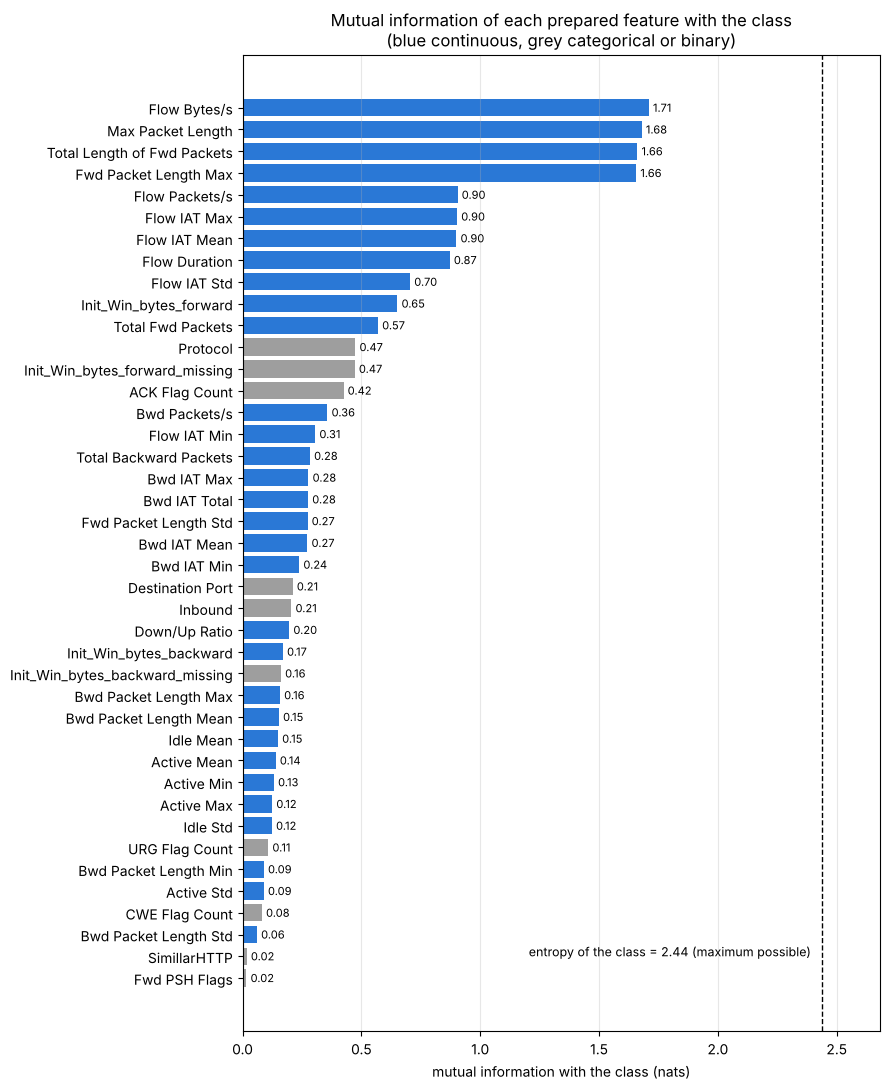

Features with MI > 1: 4, between 0.5 and 1: 7, below 0.1: 6 of 41


In [77]:
mi_input = X_prepared.copy()
mi_input["Destination Port"] = mi_input["Destination Port"].map({"well_known": 0, "registered": 1, "dynamic": 2})
mi_input[CONTINUOUS] = np.log1p(mi_input[CONTINUOUS])
discrete = [c in CATEGORICAL + BINARY for c in mi_input.columns]
with warnings.catch_warnings():
    warnings.simplefilter("ignore")           # sklearn warns about the discrete columns: harmless here
    mi = pd.Series(mutual_info_classif(mi_input, y, discrete_features=discrete, random_state=0),
                   index=mi_input.columns).sort_values()

class_share = np.bincount(y) / len(y)
entropy = -(class_share * np.log(class_share)).sum()
fig, ax = plt.subplots(figsize=(9, 11))
bars = ax.barh(mi.index, mi.values, color=["#9e9e9e" if d else "#2a78d6" for d in pd.Series(discrete, index=mi_input.columns)[mi.index]])
ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=8)
ax.axvline(entropy, color="black", ls="--", lw=1)
ax.annotate(f"entropy of the class = {entropy:.2f} (maximum possible)", (entropy, 1), xytext=(-8, 0),
            textcoords="offset points", ha="right", fontsize=9)
ax.set_xlim(0, entropy * 1.1)
ax.set_xlabel("mutual information with the class (nats)")
ax.set_title("Mutual information of each prepared feature with the class\n(blue continuous, grey categorical or binary)")
ax.grid(axis="x", alpha=0.3)
show_figure(fig)
print(f"Features with MI > 1: {(mi > 1).sum()}, between 0.5 and 1: {mi.between(0.5, 1).sum()}, "
      f"below 0.1: {(mi < 0.1).sum()} of {len(mi)}")

**Packet size, volume and rate carry the most information.** Four features exceed 1 nat, out of a maximum of 2.44: `Flow Bytes/s` (1.71), `Max Packet Length` (1.68), `Total Length of Fwd Packets` and `Fwd Packet Length Max` (1.66). They tell *which* attack is running, because each abused service produces its own packet size (§5.4). Next come the timing features (`Flow Packets/s`, `Flow IAT Max`, `Flow IAT Mean` 0.90, `Flow Duration` 0.87), which mostly separate bursts from normal traffic, then `Init_Win_bytes_forward` (0.65) and `Total Fwd Packets` (0.57).

**`Protocol` and the forward-window indicator get the same score** (0.47): they carry the same information, TCP or not (§17). This is the limit of a feature-by-feature measure: redundant features are all scored high, each on its own.

**The lowest scores are not useless features.** `SimillarHTTP` and `Fwd PSH Flags` (0.02) are 0 in more than 99% of the flows, so on average they say little; but when they are 1 they point almost certainly to benign traffic or `ddos_ntp` (§7.2). Most backward statistics (0.06–0.28) matter only for the minority of flows that have answers. `Inbound` and `Destination Port` (0.21 each) are useful but far from dominant: a first, reassuring sign that the models will not rely on them alone.

No feature is removed on this basis: the ranking describes the matrix, and Section 2 can compare it with the importance that the models give to each feature.

## 16. Distributions after the transformations

§5.3 showed the key features on their original scales, with a logarithmic axis. Here the same features are shown as the models will see them: after log1p and standardisation, on a common scale where 0 is the mean of all flows and each unit is one standard deviation. `Packet Length Mean`, removed in §7, is replaced by `Fwd Packet Length Max`.

An **EPDF** (empirical probability density function) is a normalised histogram: the height of each bar is the share of flows that fall in it, divided by the width of the bar, so that the total area is 1 and groups of different sizes can be compared. Benign flows (black outline) and all the attack flows together (orange outline) are drawn on top of each other: where the two shapes do not overlap, the feature separates them.

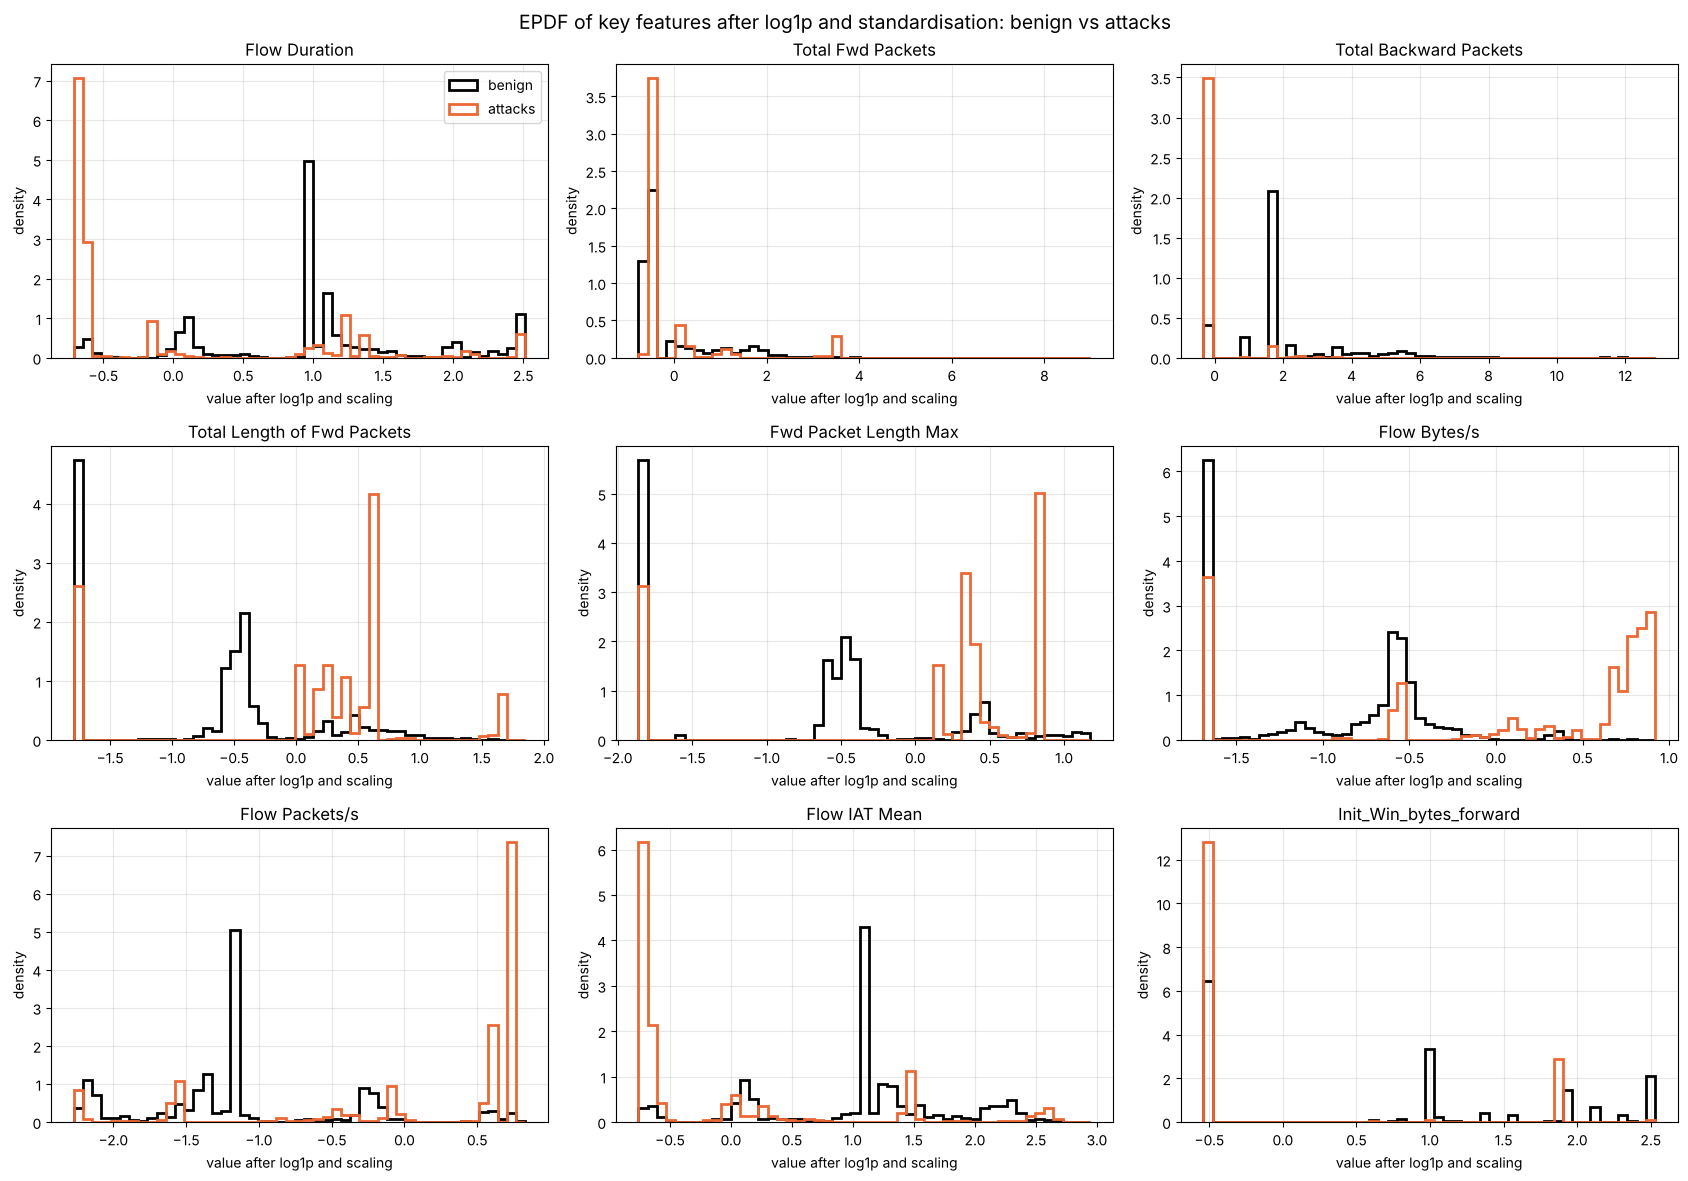

In [78]:
KEY_FINAL = ["Flow Duration", "Total Fwd Packets", "Total Backward Packets",
             "Total Length of Fwd Packets", "Fwd Packet Length Max", "Flow Bytes/s",
             "Flow Packets/s", "Flow IAT Mean", "Init_Win_bytes_forward"]
attack = ddos["label"].to_numpy() != "benign"

fig, axes = plt.subplots(3, 3, figsize=(17, 12))
for ax, feat in zip(axes.ravel(), KEY_FINAL):
    values = matrix[feat].to_numpy()
    bins = np.linspace(values.min(), values.max(), 50)
    ax.hist(values[~attack], bins=bins, density=True, histtype="step", lw=2, color=BENIGN_COLOR, label="benign")
    ax.hist(values[attack], bins=bins, density=True, histtype="step", lw=2, color=ATTACK_COLOR, label="attacks")
    ax.set_title(feat)
    ax.set_xlabel("value after log1p and scaling")
    ax.set_ylabel("density")
    ax.grid(alpha=0.3)
axes[0, 0].legend()
fig.suptitle("EPDF of key features after log1p and standardisation: benign vs attacks", fontsize=14)
show_figure(fig)

After the transformations the differences of §5.7 are still there, now on a common scale:

- **`Flow Duration` and `Flow IAT Mean`:** the attacks pile up at the far left (flows of a few µs), while benign traffic has its main peak to the right, around 1;
- **`Total Backward Packets`:** almost all the attack flows sit on the "no answer" value, while the benign ones spread to the right;
- **`Fwd Packet Length Max`, `Total Length of Fwd Packets` and `Flow Bytes/s`:** benign traffic is in the middle, the attacks are on the right (large packets, high rates). Both groups have a peak at the far left, the flows without payload;
- **`Flow Packets/s`:** the attacks concentrate at the right end, benign traffic is spread out;
- **`Init_Win_bytes_forward`:** most attack flows are at the lowest value (no window: UDP), and the TCP attacks share a single peak (near 1.9: the 5,840-byte window of `ddos_syn` and `ddos_tftp`), while the benign TCP flows take a few other typical window sizes.

The only feature where the two groups overlap broadly is `Total Fwd Packets`: both benign and attack flows usually contain one or two forward packets. The shapes are multimodal, with separate peaks rather than a single bell. This is normal, because each peak is a different class or a different kind of benign flow; it is also why no single threshold separates everything, and why the models will combine several features.

## 17. Residual correlation

The last check is the correlation among the columns of the final matrix, computed with Pearson on the transformed values. After the logarithm, relations that were curved on the raw scale can become almost straight lines, so Pearson can now see redundancies that it missed in §9. The cell lists the pairs above 0.95 and draws the correlation matrix of the columns involved in them, ordered so that the columns linked by a pair are next to each other (as the families of §7.4).

Pairs with |r| > 0.95: 22 of 990


,,|r|
feature 1,feature 2,
Protocol_6,Init_Win_bytes_forward_missing,1.000
Bwd IAT Total,Bwd IAT Max,0.999
Protocol_17,Init_Win_bytes_forward_missing,0.997
Protocol_6,Protocol_17,0.997
Bwd IAT Mean,Bwd IAT Max,0.997
Bwd IAT Total,Bwd IAT Mean,0.996
Flow Packets/s,Flow IAT Mean,0.994
Active Mean,Active Max,0.993
Fwd Packet Length Max,Max Packet Length,0.992


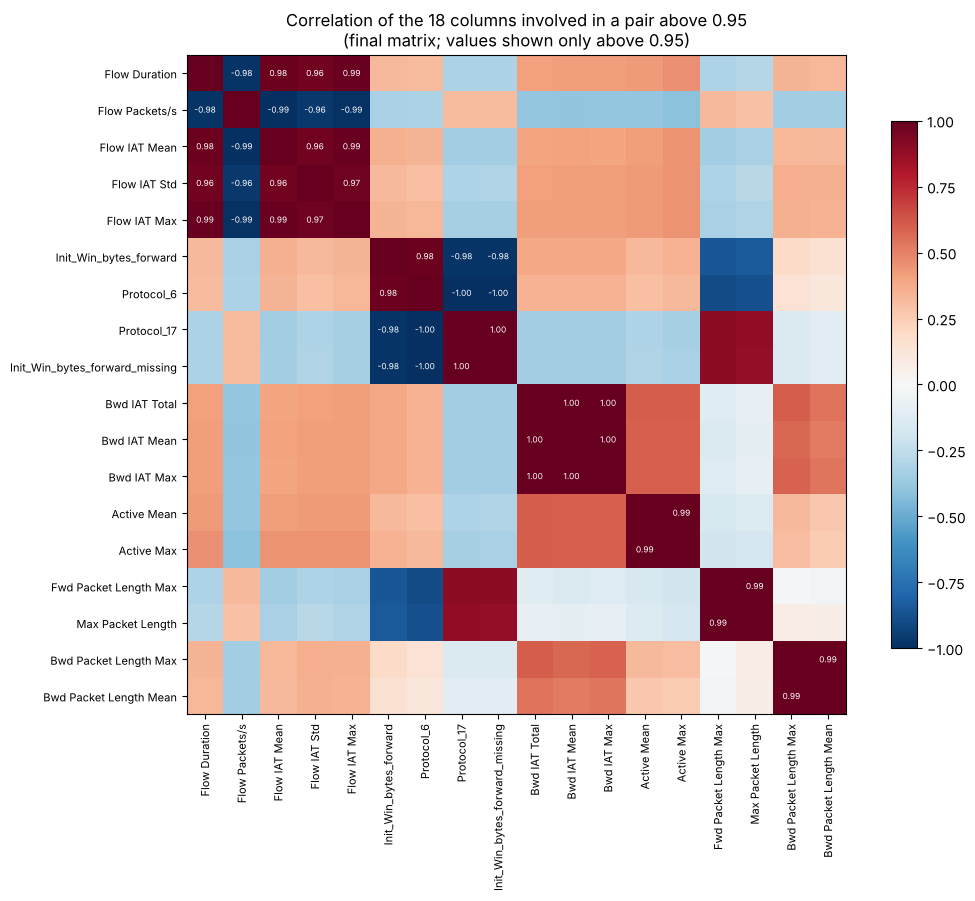

In [79]:
final_corr = matrix.corr()
residual = pairs_above(final_corr).round(3)
print(f"Pairs with |r| > 0.95: {len(residual)} of {len(final_corr) * (len(final_corr) - 1) // 2:,}")
display(residual.rename("|r|").rename_axis(["feature 1", "feature 2"]).to_frame())

blocks = []                       # columns linked by pairs above 0.95, as the families of §7.4
for a, b in residual.index:
    joined = [f for f in blocks if a in f or b in f]
    blocks = [f for f in blocks if f not in joined] + [set().union({a, b}, *joined)]
involved = [c for f in sorted(blocks, key=len, reverse=True) for c in sorted(f, key=COLUMNS_OUT.index)]
sub = final_corr.loc[involved, involved]
fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(sub.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(involved)))
ax.set_xticklabels(involved, rotation=90, fontsize=8)
ax.set_yticks(range(len(involved)))
ax.set_yticklabels(involved, fontsize=8)
for i in range(len(involved)):
    for j in range(len(involved)):
        if i != j and abs(sub.values[i, j]) > 0.95:
            ax.text(j, i, f"{sub.values[i, j]:.2f}", ha="center", va="center", fontsize=6, color="white")
ax.set_title(f"Correlation of the {len(involved)} columns involved in a pair above 0.95\n"
             "(final matrix; values shown only above 0.95)")
fig.colorbar(im, ax=ax, shrink=0.8)
show_figure(fig)

After the log transform, Pearson finds **22 pairs above 0.95 among the 990 pairs** of the final matrix, while it found none on the raw scale (§9.1): the logarithm turned curved relations into almost straight lines, so Pearson now sees what Spearman saw. The heatmap shows them as blocks:

- **the genuine redundancies of §9**, confirmed:
  - the timing of the flow: `Flow Duration`, `Flow IAT Mean/Std/Max` and `Flow Packets/s` (0.962–0.994, negative with `Flow Packets/s`);
  - the timing of the replies: `Bwd IAT Total/Mean/Max` (0.996–0.999);
  - `Active Mean`–`Active Max` (0.993), `Fwd Packet Length Max`–`Max Packet Length` (0.992), `Bwd Packet Length Max`–`Bwd Packet Length Mean` (0.990);
- **redundancies built by the encoding:**
  - `Protocol_6` and `Protocol_17` are almost complementary (0.997), because only 58 flows have neither;
  - `Init_Win_bytes_forward_missing` coincides with "not TCP" (1.000 with `Protocol_6`, 0.997 with `Protocol_17`), as noted in §10.3;
  - `Init_Win_bytes_forward` is 0 exactly when the indicator is 1 (0.981);
- **nothing unexpected:** no pair involves a column that should have been removed in §7.

**Decision: the matrix is kept as it is.** For trees and random forests these correlations do not matter. For the distance-based models, PCA (§13) merges the correlated columns into a few components. If a model in Section 2 needs a smaller or less redundant input without PCA, the candidates are those listed in §9.3, plus `Init_Win_bytes_forward_missing`.

# End of Section 1

**What the data are.** 64,239 flows in 12 classes, recorded on 1 December 2018 in 4 h 17 min. Every attack runs in its own short time window, between the same two addresses. Eleven classes have 5,261–5,986 flows each, while `ddos_ntp` has 986 (941 after the cleaning). Most benign flows come from the background traffic of the NTP capture (§6.1).

**What was wrong with them** (point 1.1):

- 12 constant columns, 6 exact copies and many redundant ones (§3.4, §3.5, §7.4);
- identifiers that reveal the class: IPs, time, source port (§4.3, §4.5, §5.2);
- two columns corrupted by invalid header lengths in 36.7% of the flows, almost all attacks, which a model would have used as a shortcut (§6.3–§6.4);
- −1 used as "not available" in the TCP window columns (§6.6);
- no missing or infinite values.

**Answers to the two questions of 1.1** (§5.8): benign traffic is easy to separate from the attacks. The attacks fall into easy classes and three groups that overlap: `ddos_ldap`/`ddos_mssql`/`ddos_ssdp`, `ddos_syn`/`ddos_tftp`, `ddos_udp`/`ddos_udp_lag`; `ddos_ntp` resembles benign traffic.

**What was decided** (point 1.2):

- 47 columns removed by a five-step funnel, each with its reason (§7.6): 4 identifiers, 19 constant, copied or almost constant columns, 2 corrupted, 21 redundant, and `Source Port`;
- 971 duplicate rows removed, `SimillarHTTP` turned into 0/1 (§8);
- `Inbound` kept with a switch, to be tested in Section 2 (§7.5);
- no further removal on the basis of Spearman, whose high values are partly due to the zeros (§9);
- encoding: one-hot for `Protocol` and for the IANA range of `Destination Port`, an indicator for the −1 windows, `LabelEncoder` for the label (§10);
- log1p and StandardScaler for the continuous features (§11), all in one pipeline (§12);
- PCA: 8 components for 90% of the variance; to be used for clustering and anomaly detection, not for the trees (§13).

**What the models receive** (point 1.3): 63,268 flows × 45 columns (§14). Packet size, volume and rate are the most informative features, followed by the timing (§15).

**Notes for Section 2**

1. Start from `data/ddos_pulito.csv` and drop the service columns (`Timestamp`, `Source IP`, `Destination IP`) and the label from the features.
2. Fit the pipeline of §12 (and PCA, if used) **on the training set only**, ideally inside a `Pipeline` together with the model.
3. For the split by time (point 2.1b) use `Timestamp`: every attack occupies its own window, so a split by time puts whole classes only in training or only in test (§4.5).
4. Class imbalance: `ddos_ntp` is about six times smaller than the other classes, so evaluate with per-class metrics, not with accuracy alone.
5. Train the main model with and without `Inbound` (switch `REMOVE_INBOUND` in §7.5) and compare the results.
6. Expect errors on the pairs of §5.8. The 1,032 ambiguous flows (§8.3) set an upper limit to the accuracy that any model can reach.